# ANFIS 5-Variable Model — Official Dissertation Scheme (CodeWorkout S19 Dataset)

**Variable scheme (unit of analysis: Student-Problem pair, not per-student aggregate):**

| Type | Variable | Definition | Source |
|---|---|---|---|
| X1 | `early_error_rate` | Proportion of compile failures in the first 2 compile attempts | `MainTable.csv` |
| X2 | `early_time_gap_sec` (log1p) | Time gap between compile #1 and #2 | `MainTable.csv` |
| X3 | `code_len_first` | Code length at the first compile | `CodeStates.csv` |
| X4 | `code_len_delta` | Difference in code length between compile 1 and compile 2 | `CodeStates.csv` |
| X5 | `code_similarity_1_2` | Text similarity of compile 1 vs 2 code | `CodeStates.csv` |
| **Y** | **`Label`** | Binary — 1 = "efficient success" (completed & attempts ≤ P75 on the same problem), 0 = needs scaffolding | `early.csv` + `late.csv` (built-in dataset column) |

This is a **binary classification** scheme (not regression like the earlier 3-variable demo). This notebook:
1. Accepts an uploaded CodeWorkout dataset archive (**ZIP or RAR**).
2. Computes X1–X2 from `Compile` event logs in `MainTable.csv` (first 2 attempts per Student-Problem pair).
3. Computes X3–X5 from the source code (`CodeStates.csv`) at the matching 1st and 2nd compile.
4. Merges with the dataset's built-in `Label` (from `early.csv`+`late.csv`).
5. Trains a first-order Sugeno ANFIS (2 MF/variable → **2⁵ = 32 rules**), evaluated with AUC, accuracy, precision/recall/F1 (not RMSE/R² — because the target is binary).
6. Saves all results to downloadable files.


## Section 1: Installation & Library Imports

In [26]:
import os, io, json, shutil, zipfile, itertools, subprocess
from pathlib import Path
from difflib import SequenceMatcher
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GroupShuffleSplit
from sklearn.metrics import (
    roc_auc_score, roc_curve, accuracy_score, precision_recall_fscore_support,
    classification_report, confusion_matrix,
)
try:
    import rarfile
    for _candidate  in ["unrar", "unrar-free"]:
        if shutil.which(_candidate ):
            rarfile.UNRAR_TOOL = _candidate
            break
except ImportError:
    pass
try:
    from google.colab import files
except ImportError:
    pass
np.random.seed(42)

!pip install -q scikit-learn pandas numpy matplotlib rarfile
!apt-get install -y -qq unrar > /dev/null 2>&1 || apt-get install -y -qq unrar-free > /dev/null 2>&1

print("Libraries ready (supports both ZIP and RAR extraction).")

Libraries ready (supports both ZIP and RAR extraction).


## Section 2: Upload Dataset File (ZIP or RAR)

Run the cell below, then select the CodeWorkout dataset archive from your computer — either .zip or .rar format is fine. The archive must contain MainTable.csv, CodeStates.csv, early.csv, and late.csv (the 5-variable scheme needs all four).

In [27]:
import os, io, json, shutil, zipfile, itertools, subprocess
from pathlib import Path
from difflib import SequenceMatcher
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GroupShuffleSplit
from sklearn.metrics import (
    roc_auc_score, roc_curve, accuracy_score, precision_recall_fscore_support,
    classification_report, confusion_matrix,
)
try:
    import rarfile
    for _candidate in ["unrar", "unrar-free"]:
        if shutil.which(_candidate):
            rarfile.UNRAR_TOOL = _candidate
            break
except ImportError:
    pass
try:
    from google.colab import files
except ImportError:
    pass
np.random.seed(42)

from google.colab import files

print("Please select the CodeWorkout dataset ZIP or RAR file to upload...")
uploaded = files.upload()

file_name = list(uploaded.keys())[0]
file_ext = Path(file_name).suffix.lower()
print(f"\nUploaded file: {file_name} ({len(uploaded[file_name])/1024:.1f} KB, format: {file_ext})")

EXTRACT_DIR = "/content/dataset_extracted"
os.makedirs(EXTRACT_DIR, exist_ok=True)

if file_ext == ".zip":
    with zipfile.ZipFile(io.BytesIO(uploaded[file_name]), "r") as z:
        z.extractall(EXTRACT_DIR)
elif file_ext == ".rar":
    tmp_rar_path = f"/content/_upload_tmp{file_ext}"
    with open(tmp_rar_path, "wb") as f:
        f.write(uploaded[file_name])
    with rarfile.RarFile(tmp_rar_path) as rf:
        rf.extractall(EXTRACT_DIR)
    os.remove(tmp_rar_path)
else:
    raise ValueError(f"File format '{file_ext}' is not supported. Please upload a .zip or .rar file.")

print(f"\nExtraction complete: {EXTRACT_DIR}")
print("\nExtracted files:")
for p in sorted(Path(EXTRACT_DIR).rglob("*")):
    if p.is_file():
        print(" -", p.relative_to(EXTRACT_DIR))

Please select the CodeWorkout dataset ZIP or RAR file to upload...


Saving CodeWorkout_S19_dataset.zip to CodeWorkout_S19_dataset (1).zip

Uploaded file: CodeWorkout_S19_dataset (1).zip (7741.5 KB, format: .zip)

Extraction complete: /content/dataset_extracted

Extracted files:
 - Data/CodeStates/CodeStates.csv
 - Data/DatasetMetadata.csv
 - Data/LinkTables/Subject.csv
 - Data/MainTable.csv
 - early.csv
 - late.csv


## Section 3: Automatically Locate Source Files

Searching for `MainTable.csv`, `CodeStates.csv`, `early.csv`, `late.csv` wherever they are located within the extracted files (no need to know the exact folder structure).


In [28]:
import os, io, json, shutil, zipfile, itertools, subprocess
from pathlib import Path
from difflib import SequenceMatcher
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GroupShuffleSplit
from sklearn.metrics import (
    roc_auc_score, roc_curve, accuracy_score, precision_recall_fscore_support,
    classification_report, confusion_matrix,
)
try:
    import rarfile
    for _candidate in ["unrar", "unrar-free"]:
        if shutil.which(_candidate):
            rarfile.UNRAR_TOOL = _candidate
            break
except ImportError:
    pass
try:
    from google.colab import files
except ImportError:
    pass
np.random.seed(42)

def find_file(file_name, root_dir):
    results = list(Path(root_dir).rglob(file_name))
    if not results:
        raise FileNotFoundError(f"File '{file_name}' was not found inside the archive.")
    if len(results) > 1:
        print(f"Warning: found more than one '{file_name}', using the first one: {results[0]}")
    return results[0]

path_main = find_file("MainTable.csv", EXTRACT_DIR)
path_codestates = find_file("CodeStates.csv", EXTRACT_DIR)
path_early = find_file("early.csv", EXTRACT_DIR)
path_late = find_file("late.csv", EXTRACT_DIR)

print("MainTable.csv    :", path_main)
print("CodeStates.csv   :", path_codestates)
print("early.csv        :", path_early)
print("late.csv         :", path_late)

main = pd.read_csv(path_main)
codestates = pd.read_csv(path_codestates)
early = pd.read_csv(path_early)
late = pd.read_csv(path_late)

print(f"\nMainTable.csv  -> {main.shape[0]} rows, {main.shape[1]} columns")
print(f"CodeStates.csv -> {codestates.shape[0]} rows, {codestates.shape[1]} columns")
print(f"early.csv      -> {early.shape[0]} rows, {early.shape[1]} columns")
print(f"late.csv       -> {late.shape[0]} rows, {late.shape[1]} columns")
display(main.head(3))

MainTable.csv    : /content/dataset_extracted/Data/MainTable.csv
CodeStates.csv   : /content/dataset_extracted/Data/CodeStates/CodeStates.csv
early.csv        : /content/dataset_extracted/early.csv
late.csv         : /content/dataset_extracted/late.csv

MainTable.csv  -> 201570 rows, 19 columns
CodeStates.csv -> 69627 rows, 2 columns
early.csv      -> 9106 rows, 6 columns
late.csv       -> 5722 rows, 6 columns


,Order,SubjectID,ToolInstances,ServerTimestamp,ServerTimezone,CourseID,CourseSectionID,AssignmentID,ProblemID,CodeStateID,IsEventOrderingConsistent,EventType,Score,Compile.Result,CompileMessageType,CompileMessageData,EventID,ParentEventID,SourceLocation
0,119630,00c54f9462673d4c09d2a88121860841,Java 8; CodeWorkout,2019-02-24T05:13:03,UTC,CS 1,1,439.0,1,efdf3fae54cdc0a09fb81fcfa365c5f843e837b0,True,Run.Program,1.0,NaN,NaN,NaN,1-69176,NaN,NaN
1,119631,00c54f9462673d4c09d2a88121860841,Java 8; CodeWorkout,2019-02-24T05:13:03,UTC,CS 1,1,439.0,1,efdf3fae54cdc0a09fb81fcfa365c5f843e837b0,True,Compile,NaN,Success,NaN,NaN,1-69177,1-69176,NaN
2,134330,00c54f9462673d4c09d2a88121860841,Java 8; CodeWorkout,2019-02-24T05:13:33,0,CS 1,1,439.0,3,79b2bcc8f502e1f7d2d4e83d1894964684c89b85,True,Run.Program,1.0,NaN,NaN,NaN,3-68089,NaN,NaN


## Section 4: Compute X1–X2 (from `MainTable.csv`, Compile events)
For each pair (`SubjectID`, `AssignmentID`, `ProblemID`): take the first 2 Compile events ordered by time (ServerTimestamp), then compute X1 (error proportion) and X2 (time gap, log1p).

In [29]:
import os, io, json, shutil, zipfile, itertools, subprocess
from pathlib import Path
from difflib import SequenceMatcher
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GroupShuffleSplit
from sklearn.metrics import (
    roc_auc_score, roc_curve, accuracy_score, precision_recall_fscore_support,
    classification_report, confusion_matrix,
)
try:
    import rarfile
    for _candidate in ["unrar", "unrar-free"]:
        if shutil.which(_candidate):
            rarfile.UNRAR_TOOL = _candidate
            break
except ImportError:
    pass
try:
    from google.colab import files
except ImportError:
    pass
np.random.seed(42)

pairs = pd.concat([early, late], ignore_index=True)
print(f"Total Student-Problem pair (early+late): {len(pairs)}")

compile_df = main[main["EventType"] == "Compile"].copy()
compile_df["ServerTimestamp"] = pd.to_datetime(compile_df["ServerTimestamp"])

group_cols = ["SubjectID", "AssignmentID", "ProblemID"]
compile_df = compile_df.sort_values(group_cols + ["ServerTimestamp"])
compile_df["compile_order"] = compile_df.groupby(group_cols).cumcount() + 1

first_two = compile_df[compile_df["compile_order"] <= 2].copy()
compile_count = first_two.groupby(group_cols)["compile_order"].max().reset_index()
compile_count.columns = group_cols + ["n_compile_early"]

c1 = first_two[first_two["compile_order"] == 1].set_index(group_cols)
c2 = first_two[first_two["compile_order"] == 2].set_index(group_cols)

result = compile_count.set_index(group_cols).copy()
result = result[result["n_compile_early"] >= 2]
print(f"Pairs with >=2 Compile events (X1-X5 computable): {len(result)}")

err1 = (c1.loc[result.index, "Compile.Result"] == "Error").astype(int)
err2 = (c2.loc[result.index, "Compile.Result"] == "Error").astype(int)
result["X1_early_error_rate"] = (err1 + err2) / 2.0

t1 = c1.loc[result.index, "ServerTimestamp"]
t2 = c2.loc[result.index, "ServerTimestamp"]
gap_sec = np.clip((t2.values - t1.values) / np.timedelta64(1, "s"), 0, None)
result["X2_early_time_gap_sec"] = np.log1p(gap_sec)


print("\nExample X1-X2 results:")
display(result[["X1_early_error_rate", "X2_early_time_gap_sec"]].head())

Total Student-Problem pair (early+late): 14828
Pairs with >=2 Compile events (X1-X5 computable): 9866

Example X1-X2 results:


X1_early_error_rate  X2_early_time_gap_sec
SubjectID                        AssignmentID ProblemID                                            
00c54f9462673d4c09d2a88121860841 439.0        5                          0.0               3.637586
                                              12                         0.0               3.465736
                                              13                         1.0               4.753590
                                              232                        1.0               2.484907
                                 487.0        101                        0.5               5.556828

## Section 5: Compute X3–X5 (from `CodeStates.csv`, source code of compile 1 & 2)

X3 = code length at the first compile, X4 = code length difference (compile 2 − compile 1), X5 = text similarity ratio between compile 1 and 2 code (SequenceMatcher). This step takes a few seconds since it compares the code text of thousands of pairs.


In [30]:
import os, io, json, shutil, zipfile, itertools, subprocess
from pathlib import Path
from difflib import SequenceMatcher
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GroupShuffleSplit
from sklearn.metrics import (
    roc_auc_score, roc_curve, accuracy_score, precision_recall_fscore_support,
    classification_report, confusion_matrix,
)
try:
    import rarfile
    for _candidate in ["unrar", "unrar-free"]:
        if shutil.which(_candidate):
            rarfile.UNRAR_TOOL = _candidate
            break
except ImportError:
    pass
try:
    from google.colab import files
except ImportError:
    pass
np.random.seed(42)

code_map = codestates.set_index("CodeStateID")["Code"].to_dict()

cs1 = c1.loc[result.index, "CodeStateID"].map(code_map).fillna("")
cs2 = c2.loc[result.index, "CodeStateID"].map(code_map).fillna("")

result["X3_code_len_first"] = cs1.str.len().values
result["X4_code_len_delta"] = (cs2.str.len().values - cs1.str.len().values)

print("Computing X5 (code similarity) ...")
result["X5_code_similarity_1_2"] = [
    SequenceMatcher(None, a, b).ratio() for a, b in zip(cs1.values, cs2.values)
]

result = result.reset_index()
print("Done. Example X3-X5:")
display(result[["X3_code_len_first", "X4_code_len_delta", "X5_code_similarity_1_2"]].head())

Computing X5 (code similarity) ...
Done. Example X3-X5:


,X3_code_len_first,X4_code_len_delta,X5_code_similarity_1_2
0,219,2,0.636364
1,199,0,0.939698
2,526,-1,0.490961
3,307,3,0.956240
4,220,-3,0.910755


## Section 6: Merge with `Label` and Save Final Dataset


In [31]:
import os, io, json, shutil, zipfile, itertools, subprocess
from pathlib import Path
from difflib import SequenceMatcher
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GroupShuffleSplit
from sklearn.metrics import (
    roc_auc_score, roc_curve, accuracy_score, precision_recall_fscore_support,
    classification_report, confusion_matrix,
)
try:
    import rarfile
    for _candidate in ["unrar", "unrar-free"]:
        if shutil.which(_candidate):
            rarfile.UNRAR_TOOL = _candidate
            break
except ImportError:
    pass
try:
    from google.colab import files
except ImportError:
    pass
np.random.seed(42)

dataset = pairs.merge(result, on=group_cols, how="inner")
dataset["Label"] = dataset["Label"].astype(int)

print(f"Final dataset (ready for ANFIS): N = {len(dataset)} Student-Problem pair")
print(f"Label distribution -- 1=efficient success, 0=needs scaffolding:")
print(dataset["Label"].value_counts())
print(f"Proportion Label=1 : {dataset['Label'].mean()*100:.1f}%")

FEATURES = [
    "X1_early_error_rate", "X2_early_time_gap_sec",
    "X3_code_len_first", "X4_code_len_delta", "X5_code_similarity_1_2",
]
final_columns = group_cols + FEATURES + ["Attempts", "CorrectEventually", "Label"]
dataset = dataset[final_columns]
dataset.to_csv("dataset_anfis_5var.csv", index=False)
print("\nSaved: dataset_anfis_5var.csv")
display(dataset.describe())

Final dataset (ready for ANFIS): N = 9153 Student-Problem pair
Label distribution -- 1=efficient success, 0=needs scaffolding:
Label
1    5407
0    3746
Name: count, dtype: int64
Proportion Label=1 : 59.1%

Saved: dataset_anfis_5var.csv


,AssignmentID,ProblemID,X1_early_error_rate,X2_early_time_gap_sec,X3_code_len_first,X4_code_len_delta,X5_code_similarity_1_2,Attempts,Label
count,9153.000000,9153.00000,9153.000000,9153.000000,9153.000000,9153.000000,9153.000000,9153.000000,9153.000000
mean,481.758986,72.92975,0.574566,3.679495,285.973670,19.641429,0.891502,6.178084,0.590735
std,22.707682,65.63750,0.389907,1.484132,139.478114,71.466703,0.186120,6.763662,0.491725
min,439.000000,1.00000,0.000000,0.000000,42.000000,-788.000000,0.066318,1.000000,0.000000
25%,487.000000,31.00000,0.500000,2.772589,198.000000,0.000000,0.892655,2.000000,0.000000
50%,492.000000,46.00000,0.500000,3.332205,260.000000,2.000000,0.979742,4.000000,1.000000
75%,494.000000,102.00000,1.000000,4.234107,356.000000,17.000000,0.995595,7.000000,1.000000
max,502.000000,236.00000,1.000000,12.865433,1373.000000,1187.000000,1.000000,93.000000,1.000000


## Section 7: Label Formation Audit (P75 Definition Verification)

In [32]:
# ============================================================
# AUDIT: verify whether the dataset's built-in Label (early.csv +
# late.csv) is truly consistent with the claimed P75 definition
# in the journal (Label=1 if solved AND Attempts <= P75 per ProblemID)
# ============================================================
attempts_col = "Attempts" if "Attempts" in pairs.columns else None
correct_col = "CorrectEventually" if "CorrectEventually" in pairs.columns else None

print("Columns available in pairs:", list(pairs.columns))
print(f"Attempts column found: {attempts_col is not None}")
print(f"CorrectEventually column found: {correct_col is not None}")

if attempts_col and correct_col and "Label" in pairs.columns:
    # Compute P75 of attempts per ProblemID (per the Table 3 definition in the journal)
    p75_per_problem = pairs.groupby("ProblemID")[attempts_col].transform(
        lambda x: x.quantile(0.75)
    )
    label_recomputed = (
        (pairs[correct_col] == True) & (pairs[attempts_col] <= p75_per_problem)
    ).astype(int)

    label_original = pairs["Label"].astype(int)
    match_count = (label_recomputed == label_original).sum()
    match_percent = match_count / len(pairs) * 100

    print(f"\nNumber of rows matching the P75 definition: {match_count}/{len(pairs)} ({match_percent:.2f}%)")
    if match_percent >= 99.0:
        print("=> The dataset's built-in Label is VERIFIED consistent with the P75 definition.")
    else:
        print("=> WARNING: The dataset's built-in Label does NOT fully match")
        print("   the claimed P75 definition. The original dataset Label definition needs")
        print("   re-checking, or Label should be recomputed manually here.")
else:
    print("\nWARNING: Attempts/CorrectEventually/Label columns are incomplete")
    print("in 'pairs' -- audit cannot be run. Check the original column names")
    print("in your early.csv/late.csv.")

Columns available in pairs: ['SubjectID', 'AssignmentID', 'ProblemID', 'Attempts', 'CorrectEventually', 'Label']
Attempts column found: True
CorrectEventually column found: True

Number of rows matching the P75 definition: 14828/14828 (100.00%)
=> The dataset's built-in Label is VERIFIED consistent with the P75 definition.


## Section 8: Discarded Data Characteristics Analysis — superseded

The original analysis of the discarded Student-Problem pairs aligned `pairs` and `dataset` by row index, which is not a safe key (the merge in Section 6 creates a new index). It has been retired. The corrected, key-based analysis (matching on SubjectID, AssignmentID, ProblemID) is in **Section 38**.


## Section 9: ANFIS Implementation (Sugeno Order-1, 5-Layer — Jang 1993)

Architecture identical to the 3-variable demo scheme, but now with 5 inputs × 2 MF = 32 rules. With this many rules, gradient-descent learning is prone to numerical instability in the premise parameters (mean, sigma), where values can blow up to extreme magnitudes and the membership functions collapse. To keep training stable, value clipping is applied to the gradients and to the mean/sigma parameters — an implementation detail worth noting in Chapter 3.


In [33]:
import os, io, json, shutil, zipfile, itertools, subprocess
from pathlib import Path
from difflib import SequenceMatcher
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GroupShuffleSplit
from sklearn.metrics import (
    roc_auc_score, roc_curve, accuracy_score, precision_recall_fscore_support,
    classification_report, confusion_matrix,
)
try:
    import rarfile
    for _candidate in ["unrar", "unrar-free"]:
        if shutil.which(_candidate):
            rarfile.UNRAR_TOOL = _candidate
            break
except ImportError:
    pass
try:
    from google.colab import files
except ImportError:
    pass
np.random.seed(42)

class ANFIS:
    def __init__(self, n_inputs, n_mf=2, seed=42, init_mean=None, init_sigma=None):
        self.n_inputs = n_inputs
        self.n_mf = n_mf
        rng = np.random.default_rng(seed)
        if init_mean is not None and init_sigma is not None:
            # Theory-pedagogically grounded initialization -- not a generic linspace
            self.mean = init_mean.copy()
            self.sigma = init_sigma.copy()
        else:
            # Generic fallback (used only when theoretical init is not provided)
            self.mean = np.tile(np.linspace(0.15, 0.85, n_mf), (n_inputs, 1))
            self.sigma = np.full((n_inputs, n_mf), 0.25)
        self.rule_indices = list(itertools.product(range(n_mf), repeat=n_inputs))
        self.n_rules = len(self.rule_indices)
        self.consequent = rng.normal(0, 0.1, size=(self.n_rules, n_inputs + 1))

    def _gaussmf(self, x, mean, sigma):
        val = np.exp(-0.5 * ((x - mean) / (sigma + 1e-8)) ** 2)
        # Numerical safeguard: prevent underflow to very small values that
        # make the product of 5 membership functions collapse to ~0 (extreme scores)
        return np.clip(val, 1e-6, 1.0)

    def _layer1_membership(self, X):
        N = X.shape[0]
        membership = np.zeros((N, self.n_inputs, self.n_mf))
        for i in range(self.n_inputs):
            for m in range(self.n_mf):
                membership[:, i, m] = self._gaussmf(X[:, i], self.mean[i, m], self.sigma[i, m])
        return membership

    def _layer2_firing(self, membership):
        N = membership.shape[0]
        w = np.ones((N, self.n_rules))
        for r, idx in enumerate(self.rule_indices):
            for i, m in enumerate(idx):
                w[:, r] *= membership[:, i, m]
        return w

    def forward(self, X):
        membership = self._layer1_membership(X)
        w = self._layer2_firing(membership)
        w_sum = np.sum(w, axis=1, keepdims=True) + 1e-12
        w_norm = w / w_sum
        X_bias = np.hstack([X, np.ones((X.shape[0], 1))])
        f = X_bias @ self.consequent.T
        y = np.sum(w_norm * f, axis=1)
        return y, w_norm, X_bias

    def _update_consequent_lse(self, X, y_true):
        membership = self._layer1_membership(X)
        w = self._layer2_firing(membership)
        w_sum = np.sum(w, axis=1, keepdims=True) + 1e-12
        w_norm = w / w_sum
        X_bias = np.hstack([X, np.ones((X.shape[0], 1))])
        N = X.shape[0]
        A = np.zeros((N, self.n_rules * (self.n_inputs + 1)))
        for r in range(self.n_rules):
            A[:, r*(self.n_inputs+1):(r+1)*(self.n_inputs+1)] = w_norm[:, r:r+1] * X_bias
        lam = 1e-6
        AtA = A.T @ A + lam * np.eye(A.shape[1])
        Aty = A.T @ y_true
        theta = np.linalg.solve(AtA, Aty)
        self.consequent = theta.reshape(self.n_rules, self.n_inputs + 1)

    def _update_premise_gd(self, X, y_true, lr=0.03):
        eps = 1e-4
        y_pred, _, _ = self.forward(X)
        base_loss = np.mean((y_pred - y_true) ** 2)
        for i in range(self.n_inputs):
            for m in range(self.n_mf):
                orig = self.mean[i, m]
                self.mean[i, m] = orig + eps
                loss_p = np.mean((self.forward(X)[0] - y_true) ** 2)
                self.mean[i, m] = orig
                grad = np.clip((loss_p - base_loss) / eps, -10.0, 10.0)
                self.mean[i, m] = np.clip(orig - lr * grad, -0.3, 1.3)

                orig_s = self.sigma[i, m]
                self.sigma[i, m] = max(orig_s + eps, 1e-3)
                loss_p = np.mean((self.forward(X)[0] - y_true) ** 2)
                self.sigma[i, m] = orig_s
                grad_s = np.clip((loss_p - base_loss) / eps, -10.0, 10.0)
                self.sigma[i, m] = np.clip(orig_s - lr * grad_s, 0.05, 1.0)

    def fit(self, X, y, epochs=60, lr=0.03, verbose=True):
        history = []
        # NOTE: keep the best parameters (lowest training RMSE) and
        # use a decaying learning rate to prevent spikes in
        # extreme RMSE that could make training "get stuck" at a
        # misdirected membership-function configuration (found from an RMSE spike
        # >20 in early epochs when the training-data composition changes).
        best_rmse = np.inf
        best_state = None
        for ep in range(epochs):
            lr_ep = lr * (0.97 ** ep)  # gradual decay so the steps get smaller and training stays stable
            self._update_consequent_lse(X, y)
            self._update_premise_gd(X, y, lr=lr_ep)
            y_pred, _, _ = self.forward(X)
            rmse = np.sqrt(np.mean((y_pred - y) ** 2))
            history.append(rmse)

            if rmse < best_rmse:
                best_rmse = rmse
                best_state = (self.mean.copy(), self.sigma.copy(), self.consequent.copy())

            if verbose and (ep % 10 == 0 or ep == epochs - 1):
                print(f"Epoch {ep+1:3d}/{epochs} - training RMSE: {rmse:.4f} (lr={lr_ep:.4f})")

        # Restore the best configuration found during training (early stopping)
        if best_state is not None:
            self.mean, self.sigma, self.consequent = best_state
            if verbose:
                print(f"\nReverted to the epoch with the best training RMSE: {best_rmse:.4f}")
        return history

    def predict(self, X):
        y, _, _ = self.forward(X)
        return np.clip(y, 0, 1)

print("ANFIS class (5-variable, 32-rule) is ready to use.")

ANFIS class (5-variable, 32-rule) is ready to use.


## Section 10: Data Preparation for Training (Student-Level Split)

70/30 student-level split using `GroupShuffleSplit`: every student appears on only one side (train OR test), never both, which prevents student-level leakage. Because the split is grouped by student, it is not label-stratified, so the Label 0/1 proportion may differ slightly between train and test (an intentional trade-off for split validity).
All five features are min-max normalized using statistics computed on the training set only, then applied to the test set, to avoid leakage.


In [34]:
import os, io, json, shutil, zipfile, itertools, subprocess
from pathlib import Path
from difflib import SequenceMatcher
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GroupShuffleSplit
from sklearn.metrics import (
    roc_auc_score, roc_curve, accuracy_score, precision_recall_fscore_support,
    classification_report, confusion_matrix,
)
try:
    import rarfile
    for _candidate in ["unrar", "unrar-free"]:
        if shutil.which(_candidate):
            rarfile.UNRAR_TOOL = _candidate
            break
except ImportError:
    pass
try:
    from google.colab import files
except ImportError:
    pass
np.random.seed(42)

X_raw = dataset[FEATURES].values.astype(float)
y = dataset["Label"].values.astype(float)
groups = dataset["SubjectID"].values  # key: student identity for leakage-free splitting

# NOTE: a plain train_test_split (random per row, i.e. per Student-Problem pair) risks
# placing the same student in BOTH the training and test sets (student-level leakage).
# The model could then "recognize" that student's behavior from the training set, so
# test-set performance would be inflated and would not reflect diagnostic capability
# on genuinely new students. GroupShuffleSplit guarantees that each student appears on
# only one side (train OR test), never both.
gss = GroupShuffleSplit(n_splits=1, test_size=0.3, random_state=42)
idx_train, idx_test = next(gss.split(X_raw, y, groups=groups))

X_train_raw, X_test_raw = X_raw[idx_train], X_raw[idx_test]
y_train, y_test = y[idx_train], y[idx_test]
groups_train, groups_test = groups[idx_train], groups[idx_test]

# Verify no overlapping students on both sides
overlap = set(groups_train) & set(groups_test)
print(f"Number of unique training students: {len(set(groups_train))}")
print(f"Number of unique test students    : {len(set(groups_test))}")
print(f"Train/test student overlap: {len(overlap)} (must be 0 if split is correct)")
assert len(overlap) == 0, "Found overlapping students in the training and test sets!"

# Normalization statistics are computed on the TRAINING data ONLY, then applied consistently to the test data
x_min = X_train_raw.min(axis=0)
x_max = X_train_raw.max(axis=0)
X_train = (X_train_raw - x_min) / (x_max - x_min + 1e-12)
X_test = (X_test_raw - x_min) / (x_max - x_min + 1e-12)

print(f"\nN total : {len(dataset)}")
print(f"N train : {len(X_train)} (Label=1: {int(y_train.sum())}, {y_train.mean()*100:.1f}%)")
print(f"N test  : {len(X_test)} (Label=1: {int(y_test.sum())}, {y_test.mean()*100:.1f}%)")
print("\nNote: the Label=1 proportion in train vs test may be slightly imbalanced")
print("(expected with GroupShuffleSplit since perfect stratification is not possible")
print("per student group) -- this is an intentional trade-off for split validity.")

Number of unique training students: 242
Number of unique test students    : 104
Train/test student overlap: 0 (must be 0 if split is correct)

N total : 9153
N train : 6384 (Label=1: 3823, 59.9%)
N test  : 2769 (Label=1: 1584, 57.2%)

Note: the Label=1 proportion in train vs test may be slightly imbalanced
(expected with GroupShuffleSplit since perfect stratification is not possible
per student group) -- this is an intentional trade-off for split validity.


## Section 11: Theory-Pedagogically Grounded Membership Function Initialization

In [35]:
# ============================================================
# THEORY-PEDAGOGICALLY GROUNDED MEMBERSHIP FUNCTION INITIALIZATION
# Each variable is assigned TWO thresholds (Low, High), whose basis
# is not an arbitrary number but a conceptual judgment grounded in
# that variable's meaning within the context of programming learning
# difficulty. The mapping flow for each variable is:
#   pedagogical theory -> raw threshold
#                      -> mean (normalized to the model's [0,1] scale)
#                      -> sigma (half the inter-threshold distance, so
#                         the transition between both categories stays smooth)
# ============================================================

# RAW thresholds (before normalization) per variable, along with the
# pedagogical rationale for setting them:
THEORETICAL_THRESHOLDS = {
    # X1: error proportion in the first 2 attempts. Thresholds 0.25/0.75
    # represent a dichotomy between "occasionally fails" and "mostly fails".
    "X1_early_error_rate": {
        "low": 0.25, "high": 0.75,
        "rationale": "Early compilation-failure dichotomy: occasionally "
                     "fails (<=25%) vs mostly fails (>=75%) on the first 2 attempts."
    },
    # X2: inter-compile time gap (log1p seconds scale). The thresholds
    # log1p(10 sec) vs log1p(180 sec = 3 min) represent a fast/impulsive
    # reaction vs a reflective pause, following self-regulated learning
    # theory (Zimmerman, 2002).
    "X2_early_time_gap_sec": {
        "low": np.log1p(10), "high": np.log1p(180),
        "rationale": "Self-regulation: a short gap (~10 sec) indicates a "
                     "fast/impulsive reaction; a long gap (~3 min) "
                     "indicates reflective activity."
    },
    # X3: code length at the first attempt (characters). Thresholds of
    # 150 vs 500 characters represent a minimal/incomplete solution vs
    # a more developed solution, following the size-based complexity
    # measurement principle (Halstead, 1977).
    "X3_code_len_first": {
        "low": 150, "high": 500,
        "rationale": "Size-based code complexity: a short solution "
                     "(~150 characters) indicates a minimal/early solution; "
                     "a longer solution (~500 characters) indicates "
                     "higher solution complexity."
    },
    # X4: change in code length between attempts. Thresholds of 0 vs 300
    # characters represent a minor revision vs a significant
    # reformulation.
    "X4_code_len_delta": {
        "low": 0, "high": 300,
        "rationale": "Magnitude of code revision: a change close to 0 "
                     "characters indicates a minor revision; a change "
                     ">=300 characters indicates a significant solution "
                     "reformulation."
    },
    # X5: code similarity score (Ratcliff-Obershelp gestalt matching).
    # Thresholds of 0.50 vs 0.85 represent a full rewrite vs an incremental
    # revision (Ratcliff & Metzener, 1988; difflib.SequenceMatcher).
    "X5_code_similarity_1_2": {
        "low": 0.50, "high": 0.85,
        "rationale": "Code revision pattern: low similarity (<=0.50) "
                     "indicates a full rewrite; high similarity "
                     "(>=0.85) indicates an incremental revision."
    },
}

def compute_theoretical_init(features, x_min, x_max, verbose=True):
    """
    Computes the ANFIS initial mean & sigma from the theory-pedagogically
    grounded thresholds above, normalized to [0,1] using the x_min/x_max
    of the training data for the split currently in use.
    """
    n_inputs = len(features)
    mean_mat = np.zeros((n_inputs, 2))
    sigma_mat = np.zeros((n_inputs, 2))

    if verbose:
        print(f"{'Variable':<26}{'Raw Threshold (L/H)':<22}{'Normalized Mean (L/H)':<28}{'Sigma'}")
        print("-" * 95)

    for i, feat in enumerate(features):
        info = THEORETICAL_THRESHOLDS[feat]
        raw_low, raw_high = info["low"], info["high"]

        span = (x_max[i] - x_min[i]) + 1e-12
        mean_low = np.clip((raw_low - x_min[i]) / span, 0.02, 0.98)
        mean_high = np.clip((raw_high - x_min[i]) / span, 0.02, 0.98)

        sigma = max(abs(mean_high - mean_low) / 2, 0.08)

        mean_mat[i] = [mean_low, mean_high]
        sigma_mat[i] = [sigma, sigma]

        if verbose:
            print(f"{feat:<26}{f'{raw_low:.2f}/{raw_high:.2f}':<22}"
                  f"{f'{mean_low:.3f}/{mean_high:.3f}':<28}{sigma:.3f}")
            print(f"    -> Rationale: {info['rationale']}")

    return mean_mat, sigma_mat

# Alias: some cells (robustness, P75 re-experiment) call the old function name.

print("The compute_theoretical_init function is ready to use.\n")
print("Theory -> threshold -> mean -> sigma mapping (computed from training-set x_min/x_max):\n")
mean_theoretical_preview, sigma_theoretical_preview = compute_theoretical_init(FEATURES, x_min, x_max)

result_rows = []
for i, feat in enumerate(FEATURES):
    info = THEORETICAL_THRESHOLDS[feat]
    result_rows.append({
        "variable": feat,
        "raw_low_threshold": info["low"],
        "raw_high_threshold": info["high"],
        "normalized_mean_low": mean_theoretical_preview[i, 0],
        "normalized_mean_high": mean_theoretical_preview[i, 1],
        "sigma": sigma_theoretical_preview[i, 0],
        "pedagogical_rationale": info["rationale"],
    })
theoretical_init_df = pd.DataFrame(result_rows)
theoretical_init_df.to_csv("theoretical_mf_initialization.csv", index=False)
print("\nSaved: theoretical_mf_initialization.csv")
try:
    files.download("theoretical_mf_initialization.csv")
except Exception:
    pass

The compute_theoretical_init function is ready to use.

Theory -> threshold -> mean -> sigma mapping (computed from training-set x_min/x_max):

Variable                  Raw Threshold (L/H)   Normalized Mean (L/H)       Sigma
-----------------------------------------------------------------------------------------------
X1_early_error_rate       0.25/0.75             0.250/0.750                 0.250
    -> Rationale: Early compilation-failure dichotomy: occasionally fails (<=25%) vs mostly fails (>=75%) on the first 2 attempts.
X2_early_time_gap_sec     2.40/5.20             0.187/0.405                 0.109
    -> Rationale: Self-regulation: a short gap (~10 sec) indicates a fast/impulsive reaction; a long gap (~3 min) indicates reflective activity.
X3_code_len_first         150.00/500.00         0.081/0.344                 0.131
    -> Rationale: Size-based code complexity: a short solution (~150 characters) indicates a minimal/early solution; a longer solution (~500 characters) ind

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Section 12: ANFIS Model Training (Main, Theory-Driven Init)

## Section 13: Model Evaluation (Binary Classification)

Since the `Label` target is binary, the metrics used are **AUC, accuracy, precision, recall, F1** — not RMSE/R² (which is for regression, used in the 3-variable demo). The decision threshold (score → Label 0/1) is found automatically from the training data (Youden's J, the ROC point with the maximum TPR-FPR difference),
then applied consistently to the test data — not the standard 0.5 threshold, because the Label is imbalanced (59%/41%).


In [36]:
# ============================================================
# SECTION 12: ANFIS MODEL TRAINING (MAIN, THEORY-DRIVEN INIT)
# ============================================================

# Compute theory-driven initial mean/sigma from the training split
mean_theoretical, sigma_theoretical = compute_theoretical_init(
    FEATURES, x_min, x_max, verbose=False
)

# Build the ANFIS model with theory-pedagogically grounded initialization
model = ANFIS(n_inputs=5, n_mf=2, seed=42,
              init_mean=mean_theoretical, init_sigma=sigma_theoretical)
print(f"Number of fuzzy rules (2^5): {model.n_rules}")
print("Model initialized with theory-pedagogically grounded mean/sigma.\n")

# Train the model
history = model.fit(X_train, y_train, epochs=60, lr=0.03, verbose=True)

# ============================================================
# SECTION 13: MODEL EVALUATION (BINARY CLASSIFICATION)
# ============================================================

score_train = model.predict(X_train)
score_test = model.predict(X_test)

# Determine the decision threshold via Youden's J on the training scores,
# restricted to the 1st-99th percentile range to avoid unstable extreme
# threshold values (e.g. from numerical underflow on certain rows).
fpr, tpr, thresholds = roc_curve(y_train, score_train)
valid_range = (thresholds >= np.percentile(score_train, 1)) & \
              (thresholds <= np.percentile(score_train, 99))
youden_j = tpr - fpr
best_idx = np.argmax(np.where(valid_range, youden_j, -np.inf))
threshold = thresholds[best_idx]

pred_train = (score_train >= threshold).astype(int)
pred_test = (score_test >= threshold).astype(int)

auc_train = roc_auc_score(y_train, score_train)
auc_test = roc_auc_score(y_test, score_test)
accuracy_train = accuracy_score(y_train, pred_train)
accuracy_test = accuracy_score(y_test, pred_test)

precision, recall, f1, _ = precision_recall_fscore_support(
    y_test, pred_test, labels=[0, 1], zero_division=0
)

print(f"\n=== MAIN EVALUATION RESULTS ===")
print(f"Decision threshold : {threshold:.4f}")
print(f"AUC train           : {auc_train:.4f}")
print(f"AUC test            : {auc_test:.4f}")
print(f"Accuracy train       : {accuracy_train:.4f}")
print(f"Accuracy test        : {accuracy_test:.4f}")
print(f"Precision (Label 0/1): {precision[0]:.4f} / {precision[1]:.4f}")
print(f"Recall    (Label 0/1): {recall[0]:.4f} / {recall[1]:.4f}")
print(f"F1-score  (Label 0/1): {f1[0]:.4f} / {f1[1]:.4f}")

metrics = {
    "n_total": len(dataset), "n_train": len(X_train), "n_test": len(X_test),
    "n_rules": model.n_rules, "decision_threshold": float(threshold),
    "auc_train": float(auc_train), "auc_test": float(auc_test),
    "accuracy_train": float(accuracy_train), "accuracy_test": float(accuracy_test),
    "precision_label0": float(precision[0]), "precision_label1": float(precision[1]),
    "recall_label0": float(recall[0]), "recall_label1": float(recall[1]),
    "f1_label0": float(f1[0]), "f1_label1": float(f1[1]),
    "x_min": x_min.tolist(), "x_max": x_max.tolist(),
}
with open("metrics_anfis_5var.json", "w") as f:
    json.dump(metrics, f, indent=2)
print("\nSaved: metrics_anfis_5var.json")
try:
    files.download("metrics_anfis_5var.json")
except Exception:
    pass

Number of fuzzy rules (2^5): 32
Model initialized with theory-pedagogically grounded mean/sigma.

Epoch   1/60 - training RMSE: 1.0013 (lr=0.0300)
Epoch  11/60 - training RMSE: 0.4569 (lr=0.0221)
Epoch  21/60 - training RMSE: 0.4569 (lr=0.0163)
Epoch  31/60 - training RMSE: 0.4569 (lr=0.0120)
Epoch  41/60 - training RMSE: 0.4569 (lr=0.0089)
Epoch  51/60 - training RMSE: 0.4569 (lr=0.0065)
Epoch  60/60 - training RMSE: 0.4569 (lr=0.0050)

Reverted to the epoch with the best training RMSE: 0.4569

=== MAIN EVALUATION RESULTS ===
Decision threshold : 0.6324
AUC train           : 0.7058
AUC test            : 0.6708
Accuracy train       : 0.6577
Accuracy test        : 0.6324
Precision (Label 0/1): 0.5588 / 0.7096
Recall    (Label 0/1): 0.6692 / 0.6048
F1-score  (Label 0/1): 0.6091 / 0.6530

Saved: metrics_anfis_5var.json


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Section 13b: Bootstrap Confident Interval for AUC Test

In [37]:
# ============================================================
# SECTION 13B: BOOTSTRAP CONFIDENCE INTERVAL FOR AUC TEST
# ============================================================

n_bootstrap = 1000
rng = np.random.RandomState(42)
n_test = len(y_test)
y_test_arr = np.asarray(y_test)

bootstrap_aucs = []
for i in range(n_bootstrap):
    idx = rng.randint(0, n_test, n_test)
    y_sample = y_test_arr[idx]
    score_sample = score_test[idx]
    if len(np.unique(y_sample)) < 2:
        continue
    bootstrap_aucs.append(roc_auc_score(y_sample, score_sample))

bootstrap_aucs = np.array(bootstrap_aucs)
ci_lower = np.percentile(bootstrap_aucs, 2.5)
ci_upper = np.percentile(bootstrap_aucs, 97.5)

print(f"\n=== BOOTSTRAP CI FOR AUC TEST ({len(bootstrap_aucs)} valid resamples) ===")
print(f"AUC test (point estimate): {auc_test:.4f}")
print(f"95% CI (percentile method): [{ci_lower:.4f}, {ci_upper:.4f}]")

bootstrap_result = {
    "n_bootstrap": int(len(bootstrap_aucs)),
    "auc_test_point": float(auc_test),
    "ci_lower_95": float(ci_lower),
    "ci_upper_95": float(ci_upper),
}
with open("bootstrap_ci_auc_5var.json", "w") as f:
    json.dump(bootstrap_result, f, indent=2)
print("\nSaved: bootstrap_ci_auc_5var.json")
try:
    files.download("bootstrap_ci_auc_5var.json")
except Exception:
    pass


=== BOOTSTRAP CI FOR AUC TEST (1000 valid resamples) ===
AUC test (point estimate): 0.6708
95% CI (percentile method): [0.6509, 0.6914]

Saved: bootstrap_ci_auc_5var.json


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Section 14: Threshold Sensitivity Test

In [38]:
from google.colab import files

# ============================================================
# THRESHOLD SENSITIVITY TEST: slightly shifting the decision threshold
# around the optimal point to see whether the classification
# changes drastically (sign of a fragile model) or stays stable (sign of robustness)
# ============================================================
shifts = [-0.20, -0.10, -0.05, 0.0, 0.05, 0.10, 0.20]
sensitivity_results = []

for delta_percent in shifts:
    new_thr = threshold * (1 + delta_percent)
    pred_test_new = (score_test >= new_thr).astype(int)

    acc_new = accuracy_score(y_test, pred_test_new)
    prec_new, rec_new, f1_new, _ = precision_recall_fscore_support(
        y_test, pred_test_new, labels=[0, 1], zero_division=0
    )
    pred_test_original = (score_test >= threshold).astype(int)
    percent_changed = (pred_test_new != pred_test_original).mean() * 100

    sensitivity_results.append({
        "shift_percent": delta_percent * 100,
        "new_threshold": new_thr,
        "accuracy": acc_new,
        "precision_label0": prec_new[0], "precision_label1": prec_new[1],
        "recall_label0": rec_new[0], "recall_label1": rec_new[1],
        "percent_predictions_changed": percent_changed,
    })

    print(f"Shift {delta_percent*100:+5.0f}% -> threshold={new_thr:.6f} | "
          f"Accuracy={acc_new:.4f} | Predictions changed={percent_changed:.1f}%")

sens_df = pd.DataFrame(sensitivity_results)
sens_df.to_csv("threshold_sensitivity_5var.csv", index=False)
print("\nSaved: threshold_sensitivity_5var.csv")
files.download("threshold_sensitivity_5var.csv")

Shift   -20% -> threshold=0.505884 | Accuracy=0.6425 | Predictions changed=11.8%
Shift   -10% -> threshold=0.569120 | Accuracy=0.6439 | Predictions changed=6.9%
Shift    -5% -> threshold=0.600737 | Accuracy=0.6389 | Predictions changed=4.6%
Shift    +0% -> threshold=0.632355 | Accuracy=0.6324 | Predictions changed=0.0%
Shift    +5% -> threshold=0.663973 | Accuracy=0.6143 | Predictions changed=6.8%
Shift   +10% -> threshold=0.695591 | Accuracy=0.5847 | Predictions changed=14.8%
Shift   +20% -> threshold=0.758826 | Accuracy=0.5175 | Predictions changed=32.6%

Saved: threshold_sensitivity_5var.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Section 15: Permutation Importance Analysis (Theory-Driven Model)

In [39]:
from google.colab import files

# ============================================================
# PERMUTATION IMPORTANCE: shuffle one variable at a time on the test set
# and observe the AUC decrease -- the larger the drop, the more important
# that variable is to the model's decision (Breiman, 2001)
# ============================================================
VARIABLE_LABELS = {
    "X1_early_error_rate": "Early Error Rate",
    "X2_early_time_gap_sec": "Inter-Compile Time Gap",
    "X3_code_len_first": "Initial Code Length",
    "X4_code_len_delta": "Code Length Change",
    "X5_code_similarity_1_2": "Code Similarity",
}

auc_original = roc_auc_score(y_test, model.predict(X_test))
print(f"Original test AUC (no shuffling): {auc_original:.4f}\n")

importance_results = []
rng_perm = np.random.default_rng(42)
N_REPEATS = 10

for i, feat in enumerate(FEATURES):
    drop_list = []
    for _ in range(N_REPEATS):
        X_test_shuffled = X_test.copy()
        rng_perm.shuffle(X_test_shuffled[:, i])
        auc_shuffled = roc_auc_score(y_test, model.predict(X_test_shuffled))
        drop_list.append(auc_original - auc_shuffled)
    drop_mean = np.mean(drop_list)
    drop_std = np.std(drop_list)
    importance_results.append({
        "variable": feat,
        "item_name": VARIABLE_LABELS[feat],
        "drop_auc_mean": drop_mean,
        "drop_auc_std": drop_std,
    })
    print(f"{VARIABLE_LABELS[feat]:30s} -> AUC decrease = {drop_mean:+.4f} (±{drop_std:.4f})")

importance_df = pd.DataFrame(importance_results).sort_values("drop_auc_mean", ascending=False)
importance_df.to_csv("permutation_importance_5var.csv", index=False)
print("\nSaved: permutation_importance_5var.csv")
files.download("permutation_importance_5var.csv")

Original test AUC (no shuffling): 0.6708

Early Error Rate               -> AUC decrease = +0.1324 (±0.0070)
Inter-Compile Time Gap         -> AUC decrease = +0.0279 (±0.0040)
Initial Code Length            -> AUC decrease = +0.0200 (±0.0047)
Code Length Change             -> AUC decrease = +0.0274 (±0.0036)
Code Similarity                -> AUC decrease = +0.0313 (±0.0049)

Saved: permutation_importance_5var.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Section 16: Dominant Rule Analysis

In [40]:
from google.colab import files

# ============================================================
# DOMINANT RULE ANALYSIS: identify which rule is most frequently
# dominant (highest firing strength) on the training data, together
# with its pedagogical interpretation
# ============================================================
VARIABLE_LABELS = {
    "X1_early_error_rate": "Early Error Rate",
    "X2_early_time_gap_sec": "Inter-Compile Time Gap",
    "X3_code_len_first": "Initial Code Length",
    "X4_code_len_delta": "Code Length Change",
    "X5_code_similarity_1_2": "Code Similarity",
}

label_mf = []
for i in range(model.n_inputs):
    order = np.argsort(model.mean[i])
    label_per_mf = {}
    label_per_mf[order[0]] = "Low"
    label_per_mf[order[1]] = "High"
    label_mf.append(label_per_mf)

membership_tr = model._layer1_membership(X_train)
w_tr = model._layer2_firing(membership_tr)
w_sum_tr = np.sum(w_tr, axis=1, keepdims=True) + 1e-12
w_norm_tr = w_tr / w_sum_tr

dominant_rule = np.argmax(w_norm_tr, axis=1)

rule_summary = []
for r in range(model.n_rules):
    idx_samples = np.where(dominant_rule == r)[0]
    if len(idx_samples) == 0:
        continue
    description = []
    for i, mf_idx in enumerate(model.rule_indices[r]):
        var_name = VARIABLE_LABELS[FEATURES[i]]
        ling_label = label_mf[i][mf_idx]
        description.append(f"{var_name}={ling_label}")
    rule_summary.append({
        "rule_id": r,
        "n_samples": len(idx_samples),
        "percent_of_data": len(idx_samples) / len(X_train) * 100,
        "mean_actual_label": y_train[idx_samples].mean(),
        "if_description": " AND ".join(description),
    })

rule_summary = sorted(rule_summary, key=lambda x: -x["n_samples"])

print("=== TOP 10 DOMINANT RULES ===\n")
for i, r in enumerate(rule_summary[:10]):
    category = "Tends toward EFFICIENT SUCCESS" if r["mean_actual_label"] >= 0.5 else "Tends toward NEEDING SCAFFOLDING"
    print(f"#{i+1} — Rule {r['rule_id']} ({r['n_samples']} samples, {r['percent_of_data']:.1f}% data)")
    print(f"    IF {r['if_description']}")
    print(f"    THEN {category} (mean actual Label = {r['mean_actual_label']:.3f})")
    print()

rule_df = pd.DataFrame(rule_summary)
rule_df.to_csv("rule_analysis_anfis_5var.csv", index=False)
print(f"Total active rules: {len(rule_summary)} of {model.n_rules} rules")
print("\nSaved: rule_analysis_anfis_5var.csv")
files.download("rule_analysis_anfis_5var.csv")

=== TOP 10 DOMINANT RULES ===

#1 — Rule 16 (2280 samples, 35.7% data)
    IF Early Error Rate=High AND Inter-Compile Time Gap=Low AND Initial Code Length=Low AND Code Length Change=Low AND Code Similarity=Low
    THEN Tends toward EFFICIENT SUCCESS (mean actual Label = 0.564)

#2 — Rule 20 (1189 samples, 18.6% data)
    IF Early Error Rate=High AND Inter-Compile Time Gap=Low AND Initial Code Length=High AND Code Length Change=Low AND Code Similarity=Low
    THEN Tends toward EFFICIENT SUCCESS (mean actual Label = 0.604)

#3 — Rule 0 (449 samples, 7.0% data)
    IF Early Error Rate=Low AND Inter-Compile Time Gap=Low AND Initial Code Length=Low AND Code Length Change=Low AND Code Similarity=Low
    THEN Tends toward EFFICIENT SUCCESS (mean actual Label = 0.708)

#4 — Rule 24 (446 samples, 7.0% data)
    IF Early Error Rate=High AND Inter-Compile Time Gap=High AND Initial Code Length=Low AND Code Length Change=Low AND Code Similarity=Low
    THEN Tends toward EFFICIENT SUCCESS (mean actu

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Section 17: Comparison Baselines (Logistic Regression and Random Forest)

In [41]:
from google.colab import files
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# ============================================================
# COMPARISON BASELINES: Logistic Regression and Random Forest
# trained on the same features (X1-X5) and the EXACT SAME official split
# as the ANFIS model, to test whether ANFIS is genuinely needed
# compared with simpler machine learning models.
# ============================================================

baseline_results = []

# --- Logistic Regression ---
model_lr = LogisticRegression(max_iter=1000, random_state=42)
model_lr.fit(X_train, y_train)
score_lr_train = model_lr.predict_proba(X_train)[:, 1]
score_lr_test = model_lr.predict_proba(X_test)[:, 1]
auc_lr_train = roc_auc_score(y_train, score_lr_train)
auc_lr_test = roc_auc_score(y_test, score_lr_test)
baseline_results.append({"model": "Logistic Regression", "auc_train": auc_lr_train, "auc_test": auc_lr_test})
print(f"Logistic Regression -> Train AUC: {auc_lr_train:.4f} | Test AUC: {auc_lr_test:.4f}")

# --- Random Forest: testing several max_depth values to avoid overfitting ---
# (RF with no depth limit tends to overfit -- training AUC near 1.0
#  but low test AUC, as found in the initial test)
print("=== LIGHT TUNING: RANDOM FOREST WITH SEVERAL max_depth VALUES ===")
depth_candidates = [3, 5, 7, 10, None]
rf_tuning_results = []
for depth in depth_candidates:
    rf_temp = RandomForestClassifier(n_estimators=100, max_depth=depth, random_state=42, n_jobs=-1)
    rf_temp.fit(X_train, y_train)
    auc_tr = roc_auc_score(y_train, rf_temp.predict_proba(X_train)[:, 1])
    auc_te = roc_auc_score(y_test, rf_temp.predict_proba(X_test)[:, 1])
    rf_tuning_results.append({"max_depth": depth, "auc_train": auc_tr, "auc_test": auc_te})
    print(f"max_depth={str(depth):6s} -> Train AUC: {auc_tr:.4f} | Test AUC: {auc_te:.4f}")

# Select the max_depth with the best TEST AUC (not train AUC) to avoid overfitting
best_depth = max(rf_tuning_results, key=lambda h: h["auc_test"])["max_depth"]
print(f"\nBest max_depth (by Test AUC): {best_depth}")

model_rf = RandomForestClassifier(n_estimators=100, max_depth=best_depth, random_state=42, n_jobs=-1)
model_rf.fit(X_train, y_train)
score_rf_train = model_rf.predict_proba(X_train)[:, 1]
score_rf_test = model_rf.predict_proba(X_test)[:, 1]
auc_rf_train = roc_auc_score(y_train, score_rf_train)
auc_rf_test = roc_auc_score(y_test, score_rf_test)
baseline_results.append({"model": f"Random Forest (max_depth={best_depth})", "auc_train": auc_rf_train, "auc_test": auc_rf_test})
print(f"\nRandom Forest (final) -> Train AUC: {auc_rf_train:.4f} | Test AUC: {auc_rf_test:.4f}")

# --- ANFIS (for direct comparison, from the already-trained model) ---
auc_anfis_test = roc_auc_score(y_test, model.predict(X_test))
auc_anfis_train = roc_auc_score(y_train, model.predict(X_train))
baseline_results.append({"model": "ANFIS (Theory-Pedagogical)", "auc_train": auc_anfis_train, "auc_test": auc_anfis_test})
print(f"ANFIS (Theory-Pedagogical) -> Train AUC: {auc_anfis_train:.4f} | Test AUC: {auc_anfis_test:.4f}")

print("\n=== BASELINE COMPARISON SUMMARY ===")
baseline_df = pd.DataFrame(baseline_results).sort_values("auc_test", ascending=False)
print(baseline_df.to_string(index=False))

baseline_df.to_csv("baseline_comparison_5var.csv", index=False)
print("\nSaved: baseline_comparison_5var.csv")
files.download("baseline_comparison_5var.csv")

# --- Random Forest feature importance (for cross-check with ANFIS permutation importance) ---
print("\n=== RANDOM FOREST FEATURE IMPORTANCE (for comparison) ===")
RF_VARIABLE_NAMES = {
    "X1_early_error_rate": "Early Error Rate",
    "X2_early_time_gap_sec": "Inter-Compile Time Gap",
    "X3_code_len_first": "Initial Code Length",
    "X4_code_len_delta": "Code Length Change",
    "X5_code_similarity_1_2": "Code Similarity",
}
rf_importance = sorted(zip(FEATURES, model_rf.feature_importances_), key=lambda x: -x[1])
for feat, imp in rf_importance:
    print(f"{RF_VARIABLE_NAMES[feat]:30s} -> importance = {imp:.4f}")

Logistic Regression -> Train AUC: 0.6581 | Test AUC: 0.6514
=== LIGHT TUNING: RANDOM FOREST WITH SEVERAL max_depth VALUES ===
max_depth=3      -> Train AUC: 0.7037 | Test AUC: 0.6753
max_depth=5      -> Train AUC: 0.7254 | Test AUC: 0.6743
max_depth=7      -> Train AUC: 0.7652 | Test AUC: 0.6786
max_depth=10     -> Train AUC: 0.8425 | Test AUC: 0.6820
max_depth=None   -> Train AUC: 0.9999 | Test AUC: 0.6508

Best max_depth (by Test AUC): 10

Random Forest (final) -> Train AUC: 0.8425 | Test AUC: 0.6820
ANFIS (Theory-Pedagogical) -> Train AUC: 0.7058 | Test AUC: 0.6708

=== BASELINE COMPARISON SUMMARY ===
                       model  auc_train  auc_test
Random Forest (max_depth=10)   0.842500  0.681960
  ANFIS (Theory-Pedagogical)   0.705772  0.670807
         Logistic Regression   0.658123  0.651417

Saved: baseline_comparison_5var.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


=== RANDOM FOREST FEATURE IMPORTANCE (for comparison) ===
Early Error Rate               -> importance = 0.2584
Initial Code Length            -> importance = 0.2375
Code Similarity                -> importance = 0.1916
Inter-Compile Time Gap         -> importance = 0.1615
Code Length Change             -> importance = 0.1510


## Section 18: Robustness Test — Theory-Driven Init (5 Student-Based Splits)

In [42]:
# ============================================================
# ROBUSTNESS TEST: run ANFIS on 5 student-based splits with
# different seeds to test the consistency of the AUC.
# If the AUC varies wildly across seeds (e.g. 0.39 vs 0.63), that is
# a sign that ANFIS training is unstable and needs further work
# before the final numbers are reported in the journal.
# ============================================================
theory_robustness_results = []
SEEDS_TEST = [42, 7, 123, 2024, 99]

for seed in SEEDS_TEST:
    gss_r = GroupShuffleSplit(n_splits=1, test_size=0.3, random_state=seed)
    idx_tr, idx_te = next(gss_r.split(X_raw, y, groups=groups))

    Xtr_raw, Xte_raw = X_raw[idx_tr], X_raw[idx_te]
    ytr, yte = y[idx_tr], y[idx_te]

    xmin_r, xmax_r = Xtr_raw.min(axis=0), Xtr_raw.max(axis=0)
    Xtr = (Xtr_raw - xmin_r) / (xmax_r - xmin_r + 1e-12)
    Xte = (Xte_raw - xmin_r) / (xmax_r - xmin_r + 1e-12)

    mean_theory, sigma_theory = compute_theoretical_init(FEATURES, xmin_r, xmax_r, verbose=False)
    model_r = ANFIS(n_inputs=5, n_mf=2, seed=42, init_mean=mean_theory, init_sigma=sigma_theory)
    model_r.fit(Xtr, ytr, epochs=60, lr=0.03, verbose=False)

    score_tr = model_r.predict(Xtr)
    score_te = model_r.predict(Xte)
    auc_tr_r = roc_auc_score(ytr, score_tr)
    auc_te_r = roc_auc_score(yte, score_te)

    theory_robustness_results.append({"seed": seed, "auc_train": auc_tr_r, "auc_test": auc_te_r})
    print(f"Seed {seed:5d} -> Train AUC: {auc_tr_r:.4f} | Test AUC: {auc_te_r:.4f}")

auc_test_list = [h["auc_test"] for h in theory_robustness_results]
print(f"\n=== ROBUSTNESS SUMMARY (5 student-based splits) ===")
print(f"Test AUC  mean    : {np.mean(auc_test_list):.4f}")
print(f"Test AUC  std     : {np.std(auc_test_list):.4f}")
print(f"Test AUC  min-max : [{np.min(auc_test_list):.4f}, {np.max(auc_test_list):.4f}]")

with open("robustness_anfis_5var.json", "w") as f:
    json.dump(theory_robustness_results, f, indent=2)
print("\nRobustness results saved to robustness_anfis_5var.json")
files.download("robustness_anfis_5var.json")

Seed    42 -> Train AUC: 0.7058 | Test AUC: 0.6708
Seed     7 -> Train AUC: 0.7135 | Test AUC: 0.6529
Seed   123 -> Train AUC: 0.6995 | Test AUC: 0.6802
Seed  2024 -> Train AUC: 0.5321 | Test AUC: 0.5404
Seed    99 -> Train AUC: 0.7046 | Test AUC: 0.6753

=== ROBUSTNESS SUMMARY (5 student-based splits) ===
Test AUC  mean    : 0.6439
Test AUC  std     : 0.0526
Test AUC  min-max : [0.5404, 0.6802]

Robustness results saved to robustness_anfis_5var.json


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Section 19: Robustness Test — Fixed Init (5 Splits) + Wilcoxon Significance Test

In [43]:
from google.colab import files
from scipy import stats

# ============================================================
# FIXED-SCHEME ROBUSTNESS TEST (5-seed) -- for a PAIRED comparison
# with the theory-driven scheme, to test the statistical significance
# of the AUC difference (Delta AUC)
# ============================================================
fixed_robustness_results = []
SEEDS_TEST = [42, 7, 123, 2024, 99]

for seed in SEEDS_TEST:
    gss_r = GroupShuffleSplit(n_splits=1, test_size=0.3, random_state=seed)
    idx_tr, idx_te = next(gss_r.split(X_raw, y, groups=groups))

    Xtr_raw, Xte_raw = X_raw[idx_tr], X_raw[idx_te]
    ytr, yte = y[idx_tr], y[idx_te]

    xmin_r, xmax_r = Xtr_raw.min(axis=0), Xtr_raw.max(axis=0)
    Xtr = (Xtr_raw - xmin_r) / (xmax_r - xmin_r + 1e-12)
    Xte = (Xte_raw - xmin_r) / (xmax_r - xmin_r + 1e-12)

    # IMPORTANT: model_g is NOT given init_mean/init_sigma -> it automatically
    # uses the generic fallback (fixed linspace) as defined in ANFIS.__init__
    model_g = ANFIS(n_inputs=5, n_mf=2, seed=42)
    model_g.fit(Xtr, ytr, epochs=60, lr=0.03, verbose=False)

    score_te_g = model_g.predict(Xte)
    auc_te_g = roc_auc_score(yte, score_te_g)

    fixed_robustness_results.append({"seed": seed, "auc_test": auc_te_g})
    print(f"Seed {seed:5d} -> Test AUC (fixed): {auc_te_g:.4f}")

with open("robustness_fixed_5var.json", "w") as f:
    json.dump(fixed_robustness_results, f, indent=2)
files.download("robustness_fixed_5var.json")

# ============================================================
# STATISTICAL SIGNIFICANCE TEST: Wilcoxon signed-rank test
# (chosen because N=5 is small and it does not assume a normal distribution)
# ============================================================
auc_theoretical = auc_test_list  # from the theory-driven robustness cell above
auc_generik = [h["auc_test"] for h in fixed_robustness_results]

print("\n=== PER-SEED PAIRED COMPARISON ===")
for i, seed in enumerate(SEEDS_TEST):
    print(f"Seed {seed:5d} -> Theory: {auc_theoretical[i]:.4f} | Fixed: {auc_generik[i]:.4f} | "
          f"Difference: {auc_theoretical[i]-auc_generik[i]:+.4f}")

delta_auc = [t - g for t, g in zip(auc_theoretical, auc_generik)]
print(f"\nMean Delta AUC (Theory-driven - Fixed): {sum(delta_auc)/len(delta_auc):.4f}")

stat, p_value = stats.wilcoxon(auc_theoretical, auc_generik)
print(f"\n=== WILCOXON SIGNED-RANK TEST RESULTS ===")
print(f"W statistic = {stat:.4f}")
print(f"p-value     = {p_value:.4f}")

if p_value < 0.05:
    print("=> AUC difference is statistically SIGNIFICANT (p < 0.05)")
else:
    print("=> AUC difference is NOT statistically significant (p >= 0.05)")
    print("   Note: with N=5 seeds, this test has low statistical power,")
    print("   so a non-significant result does not necessarily mean")
    print("   there is no real difference, but rather that the sample is too")
    print("   small to detect it conclusively.")

statistical_test_results = {
    "auc_theory_per_seed": auc_theoretical,
    "auc_fixed_per_seed": auc_generik,
    "delta_auc_per_seed": delta_auc,
    "mean_delta": sum(delta_auc)/len(delta_auc),
    "wilcoxon_statistic": float(stat),
    "wilcoxon_p_value": float(p_value),
}
with open("statistical_test_delta_auc.json", "w") as f:
    json.dump(statistical_test_results, f, indent=2)
files.download("statistical_test_delta_auc.json")

Seed    42 -> Test AUC (fixed): 0.6704
Seed     7 -> Test AUC (fixed): 0.6557
Seed   123 -> Test AUC (fixed): 0.5022
Seed  2024 -> Test AUC (fixed): 0.6720
Seed    99 -> Test AUC (fixed): 0.5873


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


=== PER-SEED PAIRED COMPARISON ===
Seed    42 -> Theory: 0.6708 | Fixed: 0.6704 | Difference: +0.0004
Seed     7 -> Theory: 0.6529 | Fixed: 0.6557 | Difference: -0.0028
Seed   123 -> Theory: 0.6802 | Fixed: 0.5022 | Difference: +0.1781
Seed  2024 -> Theory: 0.5404 | Fixed: 0.6720 | Difference: -0.1316
Seed    99 -> Theory: 0.6753 | Fixed: 0.5873 | Difference: +0.0880

Mean Delta AUC (Theory-driven - Fixed): 0.0264

=== WILCOXON SIGNED-RANK TEST RESULTS ===
W statistic = 6.0000
p-value     = 0.8125
=> AUC difference is NOT statistically significant (p >= 0.05)
   Note: with N=5 seeds, this test has low statistical power,
   so a non-significant result does not necessarily mean
   there is no real difference, but rather that the sample is too
   small to detect it conclusively.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Section 20: Effect Size (Cohen's d) for Paired AUC Difference

In [44]:
from google.colab import files

# ============================================================
# EFFECT SIZE (Cohen's d for paired samples) for the AUC difference
# between the theory-driven and fixed (generic) initialization schemes across
# the five identical seed configurations. This complements the
# Wilcoxon signed-rank test performed earlier.
# ============================================================

# Paired Test AUC data (from the Wilcoxon test cell above)
auc_theoretical_arr = np.array(auc_theoretical)
auc_generik_arr = np.array(auc_generik)

difference = auc_theoretical_arr - auc_generik_arr
print("=== PAIRED AUC DIFFERENCE (Theory-driven - Fixed) PER SEED ===")
for i, s in enumerate(SEEDS_TEST):
    print(f"Seed {s:5d}: {difference[i]:+.4f}")

mean_difference = difference.mean()
std_difference = difference.std(ddof=1)  # sample std (n-1)

# Cohen's d for paired samples:
# d = mean(difference) / std(difference)
cohens_d = mean_difference / std_difference

print(f"\nMean difference : {mean_difference:.4f}")
print(f"Difference std (n-1) : {std_difference:.4f}")
print(f"Cohen's d (paired): {cohens_d:.4f}")

# Standard Cohen (1988) interpretation
def interpret_cohens_d(d):
    d_abs = abs(d)
    if d_abs < 0.2:
        return "negligible"
    elif d_abs < 0.5:
        return "small"
    elif d_abs < 0.8:
        return "medium"
    else:
        return "large"

interpretation = interpret_cohens_d(cohens_d)
print(f"Interpretation      : {interpretation}")

print("\n=== IMPORTANT NOTE ===")
print("Effect size measures the MAGNITUDE of the difference, which differs from")
print("a significance test (Wilcoxon), which tests the CONSISTENCY OF DIRECTION.")
print("Effect size can remain descriptively meaningful even when the")
print("formal significance test does not reach p<0.05, especially with small N.")

effect_size_results = {
    "difference_per_seed": difference.tolist(),
    "mean_difference": float(mean_difference),
    "std_difference": float(std_difference),
    "cohens_d": float(cohens_d),
    "interpretation": interpretation,
    "wilcoxon_p_value_reference": float(p_value),
}
with open("effect_size_cohens_d.json", "w") as f:
    json.dump(effect_size_results, f, indent=2)
print("\nSaved: effect_size_cohens_d.json")
files.download("effect_size_cohens_d.json")

=== PAIRED AUC DIFFERENCE (Theory-driven - Fixed) PER SEED ===
Seed    42: +0.0004
Seed     7: -0.0028
Seed   123: +0.1781
Seed  2024: -0.1316
Seed    99: +0.0880

Mean difference : 0.0264
Difference std (n-1) : 0.1154
Cohen's d (paired): 0.2288
Interpretation      : small

=== IMPORTANT NOTE ===
Effect size measures the MAGNITUDE of the difference, which differs from
a significance test (Wilcoxon), which tests the CONSISTENCY OF DIRECTION.
Effect size can remain descriptively meaningful even when the
formal significance test does not reach p<0.05, especially with small N.

Saved: effect_size_cohens_d.json


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Section 21: Permutation Importance — Fixed Init Scheme (Comparison)

In [45]:
from google.colab import files

# ============================================================
# PERMUTATION IMPORTANCE FOR THE FIXED INITIALIZATION SCHEME
# Purpose: test whether the top-variable dominance under the theory-driven scheme
# is a property of the data itself, or only appears because of a
# particular initialization choice. The fixed-init model is trained on the OFFICIAL SPLIT,
# the EXACT SAME as the theory-driven model (X_train/X_test/y_train/y_test),
# so that the comparison is completely fair (apple-to-apple).
# ============================================================

# Train the model with FIXED (generic) initialization on the official split
model_fixed_official = ANFIS(n_inputs=5, n_mf=2, seed=42)  # no init_mean/init_sigma -> generic fallback
model_fixed_official.fit(X_train, y_train, epochs=60, lr=0.03, verbose=False)

auc_original_fixed = roc_auc_score(y_test, model_fixed_official.predict(X_test))
print(f"Test AUC of the FIXED-init model on the official split: {auc_original_fixed:.4f}\n")

fixed_importance_results = []
rng_perm_fixed = np.random.default_rng(42)

for i, feat in enumerate(FEATURES):
    drop_list = []
    for _ in range(N_REPEATS):
        X_test_shuffled = X_test.copy()
        rng_perm_fixed.shuffle(X_test_shuffled[:, i])
        auc_shuffled = roc_auc_score(y_test, model_fixed_official.predict(X_test_shuffled))
        drop_list.append(auc_original_fixed - auc_shuffled)
    drop_mean = np.mean(drop_list)
    drop_std = np.std(drop_list)
    fixed_importance_results.append({
        "variable": feat,
        "item_name": VARIABLE_LABELS[feat],
        "drop_auc_mean": drop_mean,
        "drop_auc_std": drop_std,
    })
    print(f"{VARIABLE_LABELS[feat]:30s} -> AUC decrease = {drop_mean:+.4f} (±{drop_std:.4f})")

importance_fixed_df = pd.DataFrame(fixed_importance_results).sort_values("drop_auc_mean", ascending=False)
importance_fixed_df.to_csv("permutation_importance_fixed_5var.csv", index=False)
print("\nSaved: permutation_importance_fixed_5var.csv")
files.download("permutation_importance_fixed_5var.csv")

# ============================================================
# DIRECT COMPARISON: variable ranking, THEORY-DRIVEN vs FIXED scheme
# ============================================================
print("\n=== VARIABLE RANKING COMPARISON: THEORY-DRIVEN vs FIXED ===")
ranking_theory = importance_df.sort_values("drop_auc_mean", ascending=False)["item_name"].tolist()
ranking_fixed = importance_fixed_df.sort_values("drop_auc_mean", ascending=False)["item_name"].tolist()

print(f"{'Rank':<10}{'Theory-Driven Scheme':<30}{'Fixed Scheme':<30}")
for idx in range(len(FEATURES)):
    print(f"{idx+1:<10}{ranking_theory[idx]:<30}{ranking_fixed[idx]:<30}")

same_dominant_variable = (ranking_theory[0] == ranking_fixed[0])
print(f"\nIs the most dominant variable THE SAME across both schemes? {same_dominant_variable}")
if same_dominant_variable:
    print("=> This variable's dominance is likely a PROPERTY OF THE DATA,")
    print("   not an artifact of a particular initialization choice.")
else:
    print("=> Variable dominance DIFFERS between schemes -- should be noted as")
    print("   a finding that the variable-contribution ranking depends on")
    print("   the initialization scheme used.")

Test AUC of the FIXED-init model on the official split: 0.6704

Early Error Rate               -> AUC decrease = +0.1324 (±0.0068)
Inter-Compile Time Gap         -> AUC decrease = +0.0203 (±0.0046)
Initial Code Length            -> AUC decrease = +0.0192 (±0.0036)
Code Length Change             -> AUC decrease = +0.0141 (±0.0053)
Code Similarity                -> AUC decrease = +0.0268 (±0.0043)

Saved: permutation_importance_fixed_5var.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


=== VARIABLE RANKING COMPARISON: THEORY-DRIVEN vs FIXED ===
Rank      Theory-Driven Scheme          Fixed Scheme                  
1         Early Error Rate              Early Error Rate              
2         Code Similarity               Code Similarity               
3         Inter-Compile Time Gap        Inter-Compile Time Gap        
4         Code Length Change            Initial Code Length           
5         Initial Code Length           Code Length Change            

Is the most dominant variable THE SAME across both schemes? True
=> This variable's dominance is likely a PROPERTY OF THE DATA,
   not an artifact of a particular initialization choice.


## Section 22: P75 Leakage Impact Test — superseded

Retired for the same index-alignment reason. The corrected analysis of the P75 label definition is in **Section 36** (diagnosis, including a replication of the retired code path) and **Section 37** (variants V1 and V2, retrained per model).


## Section 23: P75 Fix — superseded

Retired together with Section 22; see **Sections 36–37**.


## Section 24: Results Visualization

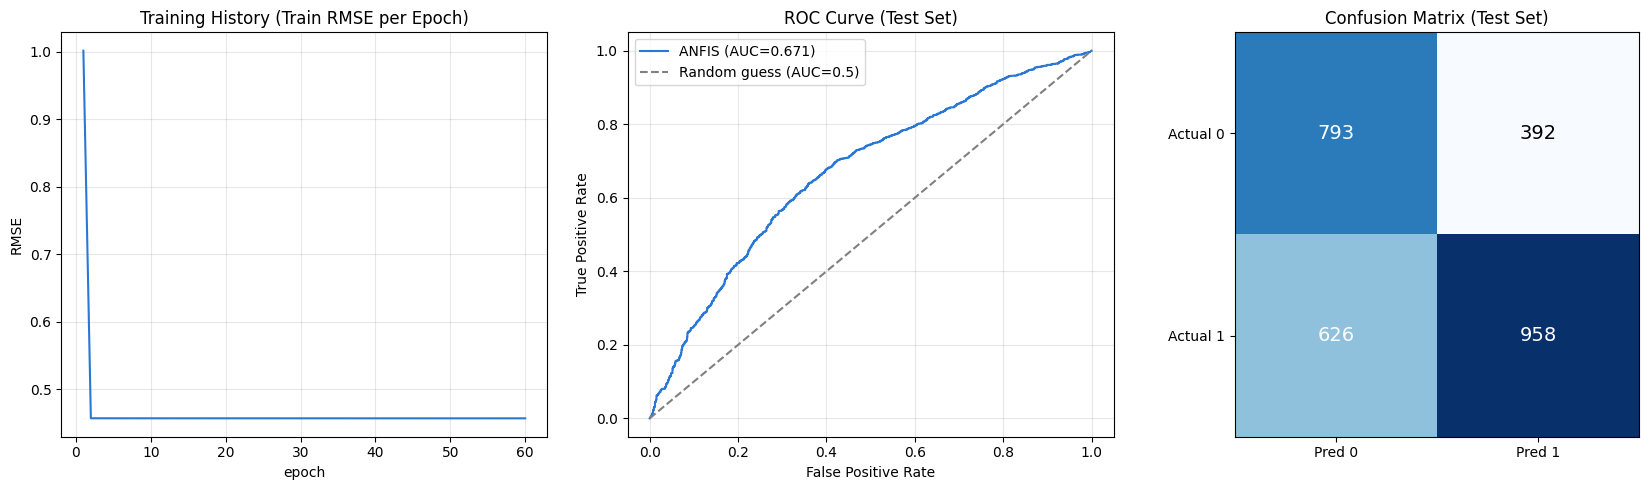

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [46]:
# ============================================================
# SECTION 24: RESULTS VISUALIZATION
# ============================================================

cm = confusion_matrix(y_test, pred_test)

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

axes[0].plot(range(1, len(history)+1), history, color="#2a78d6")
axes[0].set_title("Training History (Train RMSE per Epoch)")
axes[0].set_xlabel("epoch")
axes[0].set_ylabel("RMSE")
axes[0].grid(alpha=0.3)

fpr_t, tpr_t, _ = roc_curve(y_test, score_test)
axes[1].plot(fpr_t, tpr_t, color="#2a78d6", label=f"ANFIS (AUC={auc_test:.3f})")
axes[1].plot([0, 1], [0, 1], "--", color="gray", label="Random guess (AUC=0.5)")
axes[1].set_title("ROC Curve (Test Set)")
axes[1].set_xlabel("False Positive Rate")
axes[1].set_ylabel("True Positive Rate")
axes[1].legend()
axes[1].grid(alpha=0.3)

im = axes[2].imshow(cm, cmap="Blues")
axes[2].set_title("Confusion Matrix (Test Set)")
axes[2].set_xticks([0, 1]); axes[2].set_xticklabels(["Pred 0", "Pred 1"])
axes[2].set_yticks([0, 1]); axes[2].set_yticklabels(["Actual 0", "Actual 1"])
for i in range(2):
    for j in range(2):
        axes[2].text(j, i, str(cm[i, j]), ha="center", va="center",
                     color="white" if cm[i, j] > cm.max()/2 else "black", fontsize=14)
plt.tight_layout()
plt.savefig("evaluation_anfis_5var.png", dpi=150)
plt.show()

try:
    files.download("evaluation_anfis_5var.png")
except Exception:
    pass

## Section 25: Manual Simulation Example

Example prediction for one new Student-Problem pair (raw X1-X5 values,
before normalization).


In [47]:
import os, io, json, shutil, zipfile, itertools, subprocess
from pathlib import Path
from difflib import SequenceMatcher
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GroupShuffleSplit
from sklearn.metrics import (
    roc_auc_score, roc_curve, accuracy_score, precision_recall_fscore_support,
    classification_report, confusion_matrix,
)
try:
    import rarfile
    for _candidate in ["unrar", "unrar-free"]:
        if shutil.which(_candidate):
            rarfile.UNRAR_TOOL = _candidate
            break
except ImportError:
    pass
try:
    from google.colab import files
except ImportError:
    pass
np.random.seed(42)

example_raw = np.array([[1.0, 3.83, 42, 16, 0.78]])  # X1..X5
example_norm = (example_raw - x_min) / (x_max - x_min + 1e-12)
example_score = model.predict(example_norm)[0]
example_pred = int(example_score >= threshold)

print("Input  : X1=1.0, X2=3.83, X3=42, X4=16, X5=0.78")
print(f"Predicted score (tendency toward Label=1) : {example_score:.4f}")
print(f"Decision threshold                        : {threshold:.4f}")
print(f"Predicted Label                           : {example_pred} ({'efficient success' if example_pred==1 else 'needs scaffolding'})")

Input  : X1=1.0, X2=3.83, X3=42, X4=16, X5=0.78
Predicted score (tendency toward Label=1) : 0.6668
Decision threshold                        : 0.6324
Predicted Label                           : 1 (efficient success)


## Section 26: Save & Download Results


In [48]:
# ============================================================
# SECTION 26: SAVE & DOWNLOAD RESULTS
# ============================================================

# Save the final dataset (X1-X5 + Label) for reproducibility
dataset.to_csv("dataset_anfis_5var.csv", index=False)

# Save per-row test predictions
predictions_df = pd.DataFrame({
    "SubjectID": dataset.iloc[idx_test]["SubjectID"].values if "SubjectID" in dataset.columns else range(len(y_test)),
    "y_true": y_test,
    "score": score_test,
    "y_pred": pred_test,
})
predictions_df.to_csv("test_predictions_5var.csv", index=False)

print("Files generated in this session:")
file_list = [
    "dataset_anfis_5var.csv",
    "test_predictions_5var.csv",
    "metrics_anfis_5var.json",
    "evaluation_anfis_5var.png",
]

for fn in file_list:
    if os.path.exists(fn):
        print(" - Downloading:", fn)
        files.download(fn)
    else:
        print(" - SKIPPED (not found, likely generated in a different session):", fn)

Files generated in this session:
 - Downloading: dataset_anfis_5var.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

 - Downloading: test_predictions_5var.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

... (2 outputs left out)

<IPython.core.display.Javascript object>

 - Downloading: evaluation_anfis_5var.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Section 27: GroupKFold 10-fold (Primary Validation)

In [49]:
# ============================================================
# SECTION 27: ROBUSTNESS via GroupKFold 10-FOLD (PRIMARY VALIDATION)
# Each student is tested EXACTLY ONCE; the test folds are disjoint (no
# overlap). For each fold, TWO models are trained on the IDENTICAL split:
# (a) theory-pedagogical init, (b) fixed/generic init.
# The test AUCs are then compared pairwise (per-fold Wilcoxon).
# ============================================================

from google.colab import files
from sklearn.model_selection import GroupKFold
from scipy import stats


N_FOLD = 10
gkf = GroupKFold(n_splits=N_FOLD)

kfold_results = []
for fold, (idx_tr, idx_te) in enumerate(gkf.split(X_raw, y, groups=groups), start=1):
    Xtr_raw, Xte_raw = X_raw[idx_tr], X_raw[idx_te]
    ytr, yte = y[idx_tr], y[idx_te]

    # Min-max normalization from the fold's TRAINING DATA (prevents leakage)
    xmin_f, xmax_f = Xtr_raw.min(axis=0), Xtr_raw.max(axis=0)
    Xtr = (Xtr_raw - xmin_f) / (xmax_f - xmin_f + 1e-12)
    Xte = (Xte_raw - xmin_f) / (xmax_f - xmin_f + 1e-12)

    # (a) theory-pedagogical init
    mean_f, sigma_f = compute_theoretical_init(FEATURES, xmin_f, xmax_f, verbose=False)
    m_theory = ANFIS(n_inputs=len(FEATURES), n_mf=2, seed=42, init_mean=mean_f, init_sigma=sigma_f)
    m_theory.fit(Xtr, ytr, epochs=60, lr=0.03, verbose=False)
    auc_theory = roc_auc_score(yte, m_theory.predict(Xte))

    # (b) fixed/generic init on the IDENTICAL split
    m_fixed = ANFIS(n_inputs=len(FEATURES), n_mf=2, seed=42)  # no init -> generic fallback
    m_fixed.fit(Xtr, ytr, epochs=60, lr=0.03, verbose=False)
    auc_fixed = roc_auc_score(yte, m_fixed.predict(Xte))

    kfold_results.append({"fold": fold, "n_test": len(idx_te),
                          "auc_theory": auc_theory, "auc_fixed": auc_fixed,
                          "delta": auc_theory - auc_fixed})
    print(f"Fold {fold:2d} (n_test={len(idx_te):4d}) -> AUC theory: {auc_theory:.4f} | fixed: {auc_fixed:.4f} | delta: {auc_theory-auc_fixed:+.4f}")

kfold_df = pd.DataFrame(kfold_results)
auc_theory_list = kfold_df["auc_theory"].values
auc_fixed_list = kfold_df["auc_fixed"].values

print("\n=== GroupKFold 10-fold SUMMARY ===")
print(f"AUC theory : mean={auc_theory_list.mean():.4f}  std={auc_theory_list.std():.4f}")
print(f"AUC fixed  : mean={auc_fixed_list.mean():.4f}  std={auc_fixed_list.std():.4f}")
print(f"Mean delta : {kfold_df['delta'].mean():+.4f}")

try:
    w_stat, w_p = stats.wilcoxon(auc_theory_list, auc_fixed_list)
    print(f"Wilcoxon signed-rank (per-fold, theory vs fixed): W={w_stat:.1f}, p={w_p:.4f}")
except Exception as e:
    w_stat, w_p = None, None
    print("Wilcoxon could not be computed:", e)

kfold_df.to_csv("robustness_groupkfold_5var.csv", index=False)
kfold_summary = {
    "n_fold": N_FOLD,
    "auc_theory_per_fold": auc_theory_list.tolist(),
    "auc_fixed_per_fold": auc_fixed_list.tolist(),
    "mean_auc_theory": float(auc_theory_list.mean()), "std_auc_theory": float(auc_theory_list.std()),
    "mean_auc_fixed": float(auc_fixed_list.mean()), "std_auc_fixed": float(auc_fixed_list.std()),
    "mean_delta": float(kfold_df["delta"].mean()),
    "wilcoxon_stat": None if w_stat is None else float(w_stat),
    "wilcoxon_p": None if w_p is None else float(w_p),
}
with open("robustness_groupkfold_summary.json", "w") as f:
    json.dump(kfold_summary, f, indent=2)
print("\nSaved: robustness_groupkfold_5var.csv, robustness_groupkfold_summary.json")
try:
    files.download("robustness_groupkfold_5var.csv")
    files.download("robustness_groupkfold_summary.json")
except Exception:
    pass

Fold  1 (n_test= 917) -> AUC theory: 0.6786 | fixed: 0.6932 | delta: -0.0146
Fold  2 (n_test= 915) -> AUC theory: 0.6801 | fixed: 0.6767 | delta: +0.0034
Fold  3 (n_test= 917) -> AUC theory: 0.6695 | fixed: 0.6666 | delta: +0.0029
Fold  4 (n_test= 916) -> AUC theory: 0.6868 | fixed: 0.6703 | delta: +0.0165
Fold  5 (n_test= 915) -> AUC theory: 0.6374 | fixed: 0.6342 | delta: +0.0032
Fold  6 (n_test= 915) -> AUC theory: 0.6775 | fixed: 0.6820 | delta: -0.0045
Fold  7 (n_test= 914) -> AUC theory: 0.6473 | fixed: 0.6499 | delta: -0.0026
Fold  8 (n_test= 914) -> AUC theory: 0.7297 | fixed: 0.7290 | delta: +0.0007
Fold  9 (n_test= 914) -> AUC theory: 0.6793 | fixed: 0.6932 | delta: -0.0139
Fold 10 (n_test= 916) -> AUC theory: 0.6653 | fixed: 0.6687 | delta: -0.0034

=== GroupKFold 10-fold SUMMARY ===
AUC theory : mean=0.6752  std=0.0234
AUC fixed  : mean=0.6764  std=0.0246
Mean delta : -0.0012
Wilcoxon signed-rank (per-fold, theory vs fixed): W=23.0, p=0.6953

Saved: robustness_groupkfold_5v

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Section 28: Friedman & Holm

In [50]:
# ===== Section 28: Friedman & Holm, 4 models, GroupKFold 10-fold =====
from sklearn.model_selection import GroupKFold
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from scipy import stats
from scipy.stats import wilcoxon
from statsmodels.stats.multitest import multipletests
from itertools import combinations
import numpy as np, json

N_FOLD = 10
gkf = GroupKFold(n_splits=N_FOLD)

auc_theory_f, auc_fixed_f, auc_lr_f, auc_rf_f = [], [], [], []

for fold, (idx_tr, idx_te) in enumerate(gkf.split(X_raw, y, groups=groups), start=1):
    Xtr_raw, Xte_raw = X_raw[idx_tr], X_raw[idx_te]
    ytr, yte = y[idx_tr], y[idx_te]

    # Min-max normalization from the fold's training data (identical for all models)
    xmin_f, xmax_f = Xtr_raw.min(axis=0), Xtr_raw.max(axis=0)
    Xtr = (Xtr_raw - xmin_f) / (xmax_f - xmin_f + 1e-12)
    Xte = (Xte_raw - xmin_f) / (xmax_f - xmin_f + 1e-12)

    # (1) ANFIS theory-pedagogical
    mean_f, sigma_f = compute_theoretical_init(FEATURES, xmin_f, xmax_f, verbose=False)
    m_theory = ANFIS(n_inputs=len(FEATURES), n_mf=2, seed=42, init_mean=mean_f, init_sigma=sigma_f)
    m_theory.fit(Xtr, ytr, epochs=60, lr=0.03, verbose=False)
    auc_theory_f.append(roc_auc_score(yte, m_theory.predict(Xte)))

    # (2) ANFIS fixed init, identical split
    m_fixed = ANFIS(n_inputs=len(FEATURES), n_mf=2, seed=42)
    m_fixed.fit(Xtr, ytr, epochs=60, lr=0.03, verbose=False)
    auc_fixed_f.append(roc_auc_score(yte, m_fixed.predict(Xte)))

    # (3) Logistic Regression
    m_lr = LogisticRegression(max_iter=1000, random_state=42)
    m_lr.fit(Xtr, ytr)
    auc_lr_f.append(roc_auc_score(yte, m_lr.predict_proba(Xte)[:, 1]))

    # (4) Random Forest
    m_rf = RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42, n_jobs=-1)
    m_rf.fit(Xtr, ytr)
    auc_rf_f.append(roc_auc_score(yte, m_rf.predict_proba(Xte)[:, 1]))

    print(f"Fold {fold:2d} -> theory {auc_theory_f[-1]:.4f} | fixed {auc_fixed_f[-1]:.4f} | "
          f"LR {auc_lr_f[-1]:.4f} | RF {auc_rf_f[-1]:.4f}")

model_names  = ["ANFIS-Theoretical", "ANFIS-Fixed", "Logistic Regression", "Random Forest"]
model_scores = [auc_theory_f, auc_fixed_f, auc_lr_f, auc_rf_f]

print("\n=== MEAN AUC (10-fold) ===")
for nm, sc in zip(model_names, model_scores):
    print(f"{nm:22s} mean={np.mean(sc):.4f}  std={np.std(sc):.4f}")

chi2, p_fried = stats.friedmanchisquare(*model_scores)
print(f"\n=== FRIEDMAN (4 models, 10 paired folds) ===")
print(f"chi2 = {chi2:.4f}, p = {p_fried:.4f}")

model_pairs = list(combinations(range(4), 2))
raw_p, labels = [], []
for i, j in model_pairs:
    _, pw = wilcoxon(model_scores[i], model_scores[j])
    raw_p.append(pw); labels.append(f"{model_names[i]} vs {model_names[j]}")

reject, p_holm, _, _ = multipletests(raw_p, alpha=0.05, method='holm')
print("\n=== PAIRWISE WILCOXON + HOLM ===")
for lab, pr, ph, rj in zip(labels, raw_p, p_holm, reject):
    print(f"{lab:40s} p_raw={pr:.4f}  p_holm={ph:.4f}  significant={rj}")

json.dump({
    "friedman_chi2": float(chi2), "friedman_p": float(p_fried),
    "mean_auc": {nm: float(np.mean(sc)) for nm, sc in zip(model_names, model_scores)},
    "pairwise": [{"pair": l, "p_raw": float(pr), "p_holm": float(ph), "significant": bool(r)}
                 for l, pr, ph, r in zip(labels, raw_p, p_holm, reject)]
}, open("friedman_holm_4model_10fold.json", "w"), indent=2)
print("\nSaved: friedman_holm_4model_10fold.json")

Fold  1 -> theory 0.6786 | fixed 0.6932 | LR 0.6712 | RF 0.7009
Fold  2 -> theory 0.6801 | fixed 0.6767 | LR 0.6584 | RF 0.6830
Fold  3 -> theory 0.6695 | fixed 0.6666 | LR 0.6375 | RF 0.6784
Fold  4 -> theory 0.6868 | fixed 0.6703 | LR 0.6683 | RF 0.7088
Fold  5 -> theory 0.6374 | fixed 0.6342 | LR 0.6134 | RF 0.6488
Fold  6 -> theory 0.6775 | fixed 0.6820 | LR 0.6606 | RF 0.6878
Fold  7 -> theory 0.6473 | fixed 0.6499 | LR 0.6339 | RF 0.6701
Fold  8 -> theory 0.7297 | fixed 0.7290 | LR 0.7104 | RF 0.7213
Fold  9 -> theory 0.6793 | fixed 0.6932 | LR 0.6724 | RF 0.6821
Fold 10 -> theory 0.6653 | fixed 0.6687 | LR 0.6322 | RF 0.6771

=== MEAN AUC (10-fold) ===
ANFIS-Theoretical      mean=0.6752  std=0.0234
ANFIS-Fixed            mean=0.6764  std=0.0246
Logistic Regression    mean=0.6558  std=0.0262
Random Forest          mean=0.6858  std=0.0195

=== FRIEDMAN (4 models, 10 paired folds) ===
chi2 = 22.4400, p = 0.0001

=== PAIRWISE WILCOXON + HOLM ===
ANFIS-Theoretical vs ANFIS-Fixed     

## Section 28b: Verification for the Fixed Scheme

In [51]:
# ===== Verification for Table 14 (fixed scheme): decision threshold + dominant rule count =====
# Self-contained: retrains a fixed-init ANFIS on the official split (seed=42, IDENTICAL to Section 21).
# Placed at the very bottom, so all dependencies (ANFIS, FEATURES, X_train, y_train) already exist.

m_fixed_check = ANFIS(n_inputs=len(FEATURES), n_mf=2, seed=42)   # no init -> generic fallback
m_fixed_check.fit(X_train, y_train, epochs=60, lr=0.03, verbose=False)

# (1) Decision threshold via Youden's J (same procedure as Section 13)
score_tr_rand = m_fixed_check.predict(X_train)
fpr_r, tpr_r, thr_r = roc_curve(y_train, score_tr_rand)
valid_r = (thr_r >= np.percentile(score_tr_rand, 1)) & (thr_r <= np.percentile(score_tr_rand, 99))
youden_r = tpr_r - fpr_r
thr_fixed = thr_r[np.argmax(np.where(valid_r, youden_r, -np.inf))]
print(f"Fixed-init decision threshold (Youden's J): {thr_fixed:.4f}")

# (2) Dominant rule count (same procedure as Section 16)
w_r = m_fixed_check._layer2_firing(m_fixed_check._layer1_membership(X_train))
w_norm_r = w_r / (w_r.sum(axis=1, keepdims=True) + 1e-12)
dom_fixed = np.argmax(w_norm_r, axis=1)
print(f"Fixed-init dominant rules: {len(np.unique(dom_fixed))} of {m_fixed_check.n_rules}")

Fixed-init decision threshold (Youden's J): 0.5805
Fixed-init dominant rules: 21 of 32


## Section 29: Prediction-Point Analysis (mixed evaluation)


In [52]:
# ==============================================================================
# SECTION 29: PREDICTION-POINT ANALYSIS (mixed evaluation: the outcome is partly
# already observed at the 2nd compilation). Does NOT change any official number.
# Prerequisite: Sections 1-12 were run in the same session, so the following
# variables exist: main, pairs, dataset, FEATURES, group_cols, idx_train, idx_test,
# ANFIS, compute_theoretical_init.
# ==============================================================================
import numpy as np, pandas as pd
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.ensemble import RandomForestClassifier

SEED, N_BOOT = 42, 1000
G1_DEFINITION = "score"      # "score" = use events with Score>=1 in MainTable; "proxy" = Attempts==2 & correct
SCORE_COL = "Score"        # ASSUMPTION A2: name of the score column in MainTable (ProgSnap2)
EVENT_CORRECT = ["Run.Program", "Submit"]   # ASSUMPTION A2: events that carry a Score
RF_DEPTH = 10              # ASSUMPTION A5: official max_depth (Section 17), fixed, not re-tuned

def row_no(msg, df=None):
    print(f"[n={len(df):>6}] {msg}" if df is not None else msg)

# ------------------------------------------------------------------ STEP 0
print("=" * 78, "\nSTEP 0. Check the locked dataset")
dataset = dataset.reset_index(drop=True)
row_no("final dataset (must be 9153)", dataset)
EXPECTED_N = globals().get("EXPECTED_N", 9153)
assert len(dataset) == EXPECTED_N, f"Dataset row count {len(dataset)} is not {EXPECTED_N}: stop and check."
print("MainTable columns:", list(main.columns))
print(main["EventType"].value_counts().to_string())
assert SCORE_COL in main.columns, "Score column not found: adjust SCORE_COL (assumption A2)."
dataset["correct"] = dataset["CorrectEventually"].astype(str).str.lower().isin(["true", "1", "1.0"])

# ------------------------------------------------------------------ STEP 1
print("=" * 78, "\nSTEP 1. Time of the final outcome relative to compilation (from MainTable)")
comp = main[main["EventType"] == "Compile"][group_cols + ["ServerTimestamp"]].copy()
comp["ServerTimestamp"] = pd.to_datetime(comp["ServerTimestamp"])
row_no("event Compile", comp)
n_comp = comp.groupby(group_cols).size().rename("n_compile_total").reset_index()

ev = main[main["EventType"].isin(EVENT_CORRECT)].copy()
ev["ServerTimestamp"] = pd.to_datetime(ev["ServerTimestamp"])
ev = ev[pd.to_numeric(ev[SCORE_COL], errors="coerce") >= 1.0]
row_no("correct event (Score>=1)", ev)
t_correct = ev.groupby(group_cols)["ServerTimestamp"].min().rename("t_correct").reset_index()

cc = comp.merge(t_correct, on=group_cols, how="inner")
cc = cc[cc["ServerTimestamp"] <= cc["t_correct"]]
k_correct = cc.groupby(group_cols).size().rename("k_correct").reset_index()

fl = dataset[group_cols].merge(n_comp, on=group_cols, how="left", validate="one_to_one")
fl = fl.merge(t_correct, on=group_cols, how="left", validate="one_to_one")
fl = fl.merge(k_correct, on=group_cols, how="left", validate="one_to_one")
assert len(fl) == len(dataset)
fl["exists_correct"] = fl["t_correct"].notna()
fl["k_correct"] = np.where(fl["exists_correct"], fl["k_correct"].fillna(0), np.nan)
fl["Attempts"] = dataset["Attempts"].values
fl["Label"] = dataset["Label"].values
fl["correct"] = dataset["correct"].values
row_no("pairs with an outcome-time flag", fl)

# consistency diagnosis (ASSUMPTIONS A1/A2 are tested, not assumed)
print("\nDiagnosis A1: Attempts == number of Compile events?  ->",
      f"{(fl['Attempts'] == fl['n_compile_total']).mean()*100:.1f}% of pairs")
print("Diagnosis A2: 'has a correct event' vs CorrectEventually:")
print(pd.crosstab(fl["exists_correct"], fl["correct"], margins=True).to_string())

# ------------------------------------------------------------------ Q1
print("=" * 78, "\nQ1. Final outcome already observed at the 2nd compilation")
N = len(fl)
fl["G1_exact2"] = fl["exists_correct"] & (fl["k_correct"] == 2)        # exactly at the 2nd compilation
fl["G1_sd2"] = fl["exists_correct"] & (fl["k_correct"] <= 2)           # at or before the 2nd compilation
fl["G1_proxy"] = (fl["Attempts"] == 2) & fl["correct"]            # proxy without Score
G1 = fl["G1_exact2"] if G1_DEFINITION == "score" else fl["G1_proxy"]
fl["G1"] = G1.values
q1 = pd.DataFrame({
    "definition": ["correct EXACTLY at the 2nd compilation (Score)", "correct at or before the 2nd compilation (Score)",
                 "proxy: Attempts==2 & CorrectEventually"],
    "n": [fl.G1_exact2.sum(), fl.G1_sd2.sum(), fl.G1_proxy.sum()]})
q1["percent_of_9153"] = (q1["n"] / N * 100).round(2)
print(q1.to_string(index=False))
print(f"Group (1) used in Q3-Q5: definition '{G1_DEFINITION}', n={int(fl.G1.sum())}")
print("Intersection of G1_exact2 vs G1_proxy:\n", pd.crosstab(fl.G1_exact2, fl.G1_proxy).to_string())

# ------------------------------------------------------------------ Q2
print("=" * 78, "\nQ2. Exactly 2 attempts in total (no attempt after the prediction point)")
p75_map = pairs.groupby("ProblemID")["Attempts"].quantile(0.75)   # official P75, all pairs (Section 7)
p75_prob = dataset["ProblemID"].map(p75_map).values
fl["G2_attempts"] = fl["Attempts"] == 2
fl["G2_compile"] = fl["n_compile_total"] == 2
rows = []
for nm, m in [("Attempts == 2", fl.G2_attempts), ("n Compile == 2 (cross-check)", fl.G2_compile)]:
    d = fl[m]
    rows.append({"definition": nm, "n": len(d), "percent_of_9153": round(len(d) / N * 100, 2),
                 "Label=1 (n)": int((d.Label == 1).sum()), "Label=1 (%)": round((d.Label == 1).mean() * 100, 2),
                 "Label=0 (n)": int((d.Label == 0).sum()), "Label=0 (%)": round((d.Label == 0).mean() * 100, 2)})
print(pd.DataFrame(rows).to_string(index=False))
g2 = fl[fl.G2_attempts]
print("\nWithin the Attempts==2 group: Label vs CorrectEventually")
print(pd.crosstab(g2.Label, g2.correct, margins=True).to_string())
print("Attempts==2 pairs on problems with P75 < 2 (Label is always 0 even if correct):",
      int(((p75_prob < 2) & fl.G2_attempts.values).sum()))

# ------------------------------------------------------------------ Q3
print("=" * 78, "\nQ3. Label distribution: group (1) vs the rest, train and test (official split)")
sp = np.full(N, "", dtype=object); sp[idx_train] = "train"; sp[idx_test] = "test"
rows = []
for s in ["train", "test", "total"]:
    ms = (sp == s) if s != "total" else np.ones(N, bool)
    for nm, mk in [("group (1)", fl.G1.values), ("rest", ~fl.G1.values)]:
        d = fl[ms & mk]
        rows.append({"split": s, "group_name": nm, "n": len(d),
                     "Label=1 (n)": int((d.Label == 1).sum()), "Label=1 (%)": round((d.Label == 1).mean() * 100, 2) if len(d) else np.nan,
                     "Label=0 (n)": int((d.Label == 0).sum()), "Label=0 (%)": round((d.Label == 0).mean() * 100, 2) if len(d) else np.nan})
print(pd.DataFrame(rows).to_string(index=False))

# ------------------------------------------------------------------ model helpers
def boot_ci(y, s, groups=None, n=N_BOOT, seed=SEED):
    rng = np.random.default_rng(seed); out = []
    if groups is None:
        for _ in range(n):
            i = rng.integers(0, len(y), len(y))
            if y[i].min() != y[i].max(): out.append(roc_auc_score(y[i], s[i]))
    else:
        ug, inv = np.unique(groups, return_inverse=True)
        mem = [np.where(inv == g)[0] for g in range(len(ug))]
        for _ in range(n):
            i = np.concatenate([mem[p] for p in rng.integers(0, len(ug), len(ug))])
            if y[i].min() != y[i].max(): out.append(roc_auc_score(y[i], s[i]))
    return np.percentile(out, [2.5, 97.5])

X_all = dataset[FEATURES].values.astype(float)
stu = dataset["SubjectID"].values

def run_scenario(keep, ylab, item_name):
    """Official protocol: FIXED student train/test partition (idx_train/idx_test), drop rows outside `keep`,
    min-max from training data, theoretical init, ANFIS 60 epochs lr 0.03 seed 42; RF 100 trees depth 10 seed 42."""
    tr = idx_train[keep[idx_train]]; te = idx_test[keep[idx_test]]
    assert len(set(stu[tr]) & set(stu[te])) == 0
    xmin, xmax = X_all[tr].min(0), X_all[tr].max(0)
    Xtr = (X_all[tr] - xmin) / (xmax - xmin + 1e-12); Xte = (X_all[te] - xmin) / (xmax - xmin + 1e-12)
    ytr, yte = ylab[tr], ylab[te]
    row_no(f"{item_name}: train={len(tr)} (Label=1 {ytr.mean()*100:.1f}%), test={len(te)} (Label=1 {yte.mean()*100:.1f}%)")
    mu, sg = compute_theoretical_init(FEATURES, xmin, xmax, verbose=False)
    an = ANFIS(n_inputs=5, n_mf=2, seed=SEED, init_mean=mu, init_sigma=sg)
    an.fit(Xtr, ytr, epochs=60, lr=0.03, verbose=False)
    rf = RandomForestClassifier(n_estimators=100, max_depth=RF_DEPTH, random_state=SEED, n_jobs=-1).fit(Xtr, ytr)
    s_an, s_rf = an.predict(Xte), rf.predict_proba(Xte)[:, 1]
    r = {"scenario": item_name, "n_train_rows": len(tr), "n_test_rows": len(te), "Label1_test_%": round(yte.mean() * 100, 1)}
    for k, s in [("ANFIS", s_an), ("RF", s_rf)]:
        lo, hi = boot_ci(yte, s)
        clo, chi = boot_ci(yte, s, groups=stu[te])
        r.update({f"AUC_{k}": round(roc_auc_score(yte, s), 3), f"CI_{k}_rows": f"[{lo:.3f}-{hi:.3f}]",
                  f"CI_{k}_students": f"[{clo:.3f}-{chi:.3f}]"})
    return r, (an, rf, xmin, xmax, te)

ytrue = dataset["Label"].values.astype(float)
ALL_MASK = np.ones(N, bool)

# ------------------------------------------------------------------ Q4
print("=" * 78, "\nQ4. Sensitivity: retrain without group (1)")
out_rows = []
r0, m0 = run_scenario(ALL_MASK, ytrue, "S0 reproduction (all 9153)"); out_rows.append(r0)
print(f"REPRODUCTION CHECK: ANFIS {r0['AUC_ANFIS']} vs official 0.671 | RF {r0['AUC_RF']} vs official 0.682")
r1, m1 = run_scenario(~fl.G1.values, ytrue, "S1 without group (1)"); out_rows.append(r1)
r2, _ = run_scenario(~fl.G2_attempts.values, ytrue, "S2 (additional) without Attempts==2"); out_rows.append(r2)

# S3: official model (fully trained) evaluated on the test subset without group (1)
an0, rf0, xmin0, xmax0, te0 = m0
te3 = te0[~fl.G1.values[te0]]
Xte3 = (X_all[te3] - xmin0) / (xmax0 - xmin0 + 1e-12)
r3 = {"scenario": "S3 (additional) official model, test without (1)", "n_train_rows": len(idx_train), "n_test_rows": len(te3),
      "Label1_test_%": round(ytrue[te3].mean() * 100, 1)}
for k, s in [("ANFIS", an0.predict(Xte3)), ("RF", rf0.predict_proba(Xte3)[:, 1])]:
    lo, hi = boot_ci(ytrue[te3], s); clo, chi = boot_ci(ytrue[te3], s, groups=stu[te3])
    r3.update({f"AUC_{k}": round(roc_auc_score(ytrue[te3], s), 3), f"CI_{k}_rows": f"[{lo:.3f}-{hi:.3f}]",
               f"CI_{k}_students": f"[{clo:.3f}-{chi:.3f}]"})
out_rows.append(r3)
tab4 = pd.DataFrame(out_rows); print(tab4.to_string(index=False))
tab4.to_csv("sensitivity_point_prediction_q4.csv", index=False)

# ------------------------------------------------------------------ Q5 (optional)
print("=" * 78, "\nQ5. Alternative label from attempts AFTER the prediction point only")
keep5 = ~fl.G1.values
dd = dataset[keep5].copy()
row_no("pairs whose outcome is not yet observed at the 2nd compilation", dd)
print("ASSUMPTION A3: Attempts uses the same unit as the 2-compilation window, so extra = Attempts-2.")
print("Pairs with Attempts<2 (extra clipped to 0):", int((dd.Attempts < 2).sum()))
dd["extra"] = (dd["Attempts"] - 2).clip(lower=0)
dd["p75_extra"] = dd.groupby("ProblemID")["extra"].transform(lambda x: x.quantile(0.75))
dd["Label_alt"] = ((dd["extra"] <= dd["p75_extra"]) & dd["correct"]).astype(int)  # 1 = efficient (same polarity)
sizes = dd.groupby("ProblemID").size()
print("Distribution of extra-attempt P75 per problem:", dd.groupby("ProblemID")["p75_extra"].first().value_counts().to_dict())
print(f"Problems with <30 pairs: {(sizes < 30).sum()} of {len(sizes)} (min={sizes.min()})")
ylab5 = np.full(N, np.nan); ylab5[np.where(keep5)[0]] = dd["Label_alt"].values
for s_nm, ix in [("train", idx_train), ("test", idx_test)]:
    ix = ix[keep5[ix]]
    print(f"Alt_Label=1 in {s_nm}: {np.nanmean(ylab5[ix])*100:.1f}% (n={len(ix)})")
print(f"Official Label=1 on the same subset: {dataset.loc[keep5,'Label'].mean()*100:.1f}%")
r5, _ = run_scenario(keep5, np.nan_to_num(ylab5), "S5 alternative label (subset without (1))")
tab5 = pd.DataFrame([r5]); print(tab5.to_string(index=False))
tab5.to_csv("sensitivity_point_prediction_q5.csv", index=False)
print("\nDone. Official numbers (0.671 / 0.682 etc.) are NOT changed by this Section.")


STEP 0. Check the locked dataset
[n=  9153] final dataset (must be 9153)
MainTable columns: ['Order', 'SubjectID', 'ToolInstances', 'ServerTimestamp', 'ServerTimezone', 'CourseID', 'CourseSectionID', 'AssignmentID', 'ProblemID', 'CodeStateID', 'IsEventOrderingConsistent', 'EventType', 'Score', 'Compile.Result', 'CompileMessageType', 'CompileMessageData', 'EventID', 'ParentEventID', 'SourceLocation']
EventType
Run.Program      69627
Compile          69627
Compile.Error    62316
STEP 1. Time of the final outcome relative to compilation (from MainTable)
[n= 69627] event Compile
[n= 16490] correct event (Score>=1)
[n=  9153] pairs with an outcome-time flag

Diagnosis A1: Attempts == number of Compile events?  -> 89.5% of pairs
Diagnosis A2: 'has a correct event' vs CorrectEventually:
correct         False  True   All
exists_correct                   
False             887     0   887
True                0  8266  8266
All               887  8266  9153
Q1. Final outcome already observed at t

## Section 30: Evaluation on Pairs Whose Outcome Is Not Yet Observed at the 2nd Compilation (Populations A and B)


In [53]:
# ==============================================================================
# SECTION 30: EVALUATION ON PAIRS WHOSE OUTCOME IS NOT YET OBSERVED AT THE 2ND COMPILATION
# (responds to the supervisor's comment on Subsection II-B: "the evaluation may mix prediction of
#  difficulty that is still to unfold with classification of an outcome that is partly observed")
#
# This Section ONLY READS notebook variables and does NOT change any official number.
# Prerequisite: Sections 1-12 were run (available: main, pairs, dataset, FEATURES, group_cols,
#            idx_train, idx_test, ANFIS, compute_theoretical_init).
#
# POPULATION DEFINITIONS
#   A = all 9,153 Student-Problem pairs (old reference, INCLUDING outcomes already observed)
#   B = A minus the pairs that are correct EXACTLY at the 2nd compilation (Score>=1) -> 6,989 (PRIMARY)
#
# ASSUMPTIONS (flagged so they can be explained to the supervisor)
#   A1  Attempts equals the number of Compile events in only ~89.5% of pairs (Section 29 result), so
#       Attempts is not exactly a compilation count.
#   A2  "Correct" = a Run.Program/Submit event with Score>=1 (matches CorrectEventually 100%).
#   A3  S5: extra attempts = Attempts - 2, clipped to 0 (the clipped count is reported).
#   A4  S5: extra-attempt P75 is computed per problem on population B (whole sample, same as the
#       official P75 design). Same polarity as the official Label: 1 = correct AND extra <= extra P75.
#   A5  Fixed hyperparameters, NOT tuned: ANFIS 60 epochs lr 0.03 seed 42 (theoretical init;
#       "Fixed" = ANFIS without init, generic fallback of Section 19); RF 100 trees max_depth 10
#       seed 42; LR max_iter 1000 seed 42; min-max is computed from the training data of each model.
#   A6  GroupKFold: sklearn.GroupKFold(n_splits=10), no shuffle, group = SubjectID, same protocol
#       in every fold. This is a RECONSTRUCTION of Table 13; it is checked against the canonical
#       numbers on population A (a warning, not a stop).
#   A7  Student-level bootstrap CI: within each test fold, students are resampled with
#       replacement (1,000 repeats, seed 42, 2.5/97.5 percentiles). Models are NOT retrained.
#       The same repeats are used for all models (paired), so AUC differences get a CI.
# ==============================================================================
import numpy as np, pandas as pd
from scipy import stats
from sklearn.model_selection import GroupKFold
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score
try:
    from google.colab import files as _files30
except Exception:
    _files30 = None

SEED, RF_DEPTH = 42, 10
B_BOOT = globals().get("B_OVERRIDE", 1000)
RUN_KFOLD_A = globals().get("RUN_KFOLD_A_OVERRIDE", True)   # check Table 13 on population A (+~20 ANFIS trainings)
SCORE_COL, EVENT_CORRECT = "Score", ["Run.Program", "Submit"]
EXPECTED = globals().get("EXPECTED_OVERRIDE", dict(N=9153, A_tr=6384, A_te=2769, G1=2164,
                                                    NB=6989, B_tr=4812, B_te=2177))
OFFICIAL = globals().get("OFFICIAL_OVERRIDE", dict(anfis=0.671, rf=0.682))   # test AUC of the official split
TOL = 0.002
KFOLD_CANON = {"ANFIS-Theoretical": 0.6752, "ANFIS-Fixed": 0.6764, "LR": 0.6558, "RF": 0.6858}  # canonical Table 13

def halt(msg):
    print("\n*** STOPPED: " + msg)
    raise RuntimeError(msg)

def check_n(item_name, value, expected):
    if expected is None:          # only used in the smoke test on synthetic data
        print(f"   [info] {item_name}: {value}"); return
    status = "OK " if value == expected else "FAILED"
    print(f"   [{status}] {item_name}: {value} (expected {expected})")
    if value != expected:
        halt(f"{item_name} = {value}, not {expected}. Check the dataset/split before continuing.")

# ------------------------------------------------------------------ STEP 0: prerequisites
print("=" * 80, "\nSTEP 0. Prerequisites and data sizes")
needed = ["main", "pairs", "dataset", "FEATURES", "group_cols", "idx_train", "idx_test",
         "ANFIS", "compute_theoretical_init"]
missing = [n for n in needed if n not in globals()]
if missing:
    halt(f"notebook variables missing: {missing}. Run Sections 1-12 first.")
ds = dataset.reset_index(drop=True)            # local copy; row order = order of X_raw
N = len(ds)
check_n("number of pairs in population A", N, EXPECTED["N"])
check_n("n train of the official split", len(idx_train), EXPECTED["A_tr"])
check_n("n test of the official split", len(idx_test), EXPECTED["A_te"])
X_all = ds[FEATURES].values.astype(float)
Y_OFFICIAL = ds["Label"].values.astype(float)
STU = ds["SubjectID"].values
IS_CORRECT = ds["CorrectEventually"].astype(str).str.lower().isin(["true", "1", "1.0"]).values

# ------------------------------------------------------------------ STEP 1: excluded group
print("=" * 80, "\nSTEP 1. Pairs that are correct EXACTLY at the 2nd compilation (Score definition)")
comp = main[main["EventType"] == "Compile"][group_cols + ["ServerTimestamp"]].copy()
comp["ServerTimestamp"] = pd.to_datetime(comp["ServerTimestamp"])
ev = main[main["EventType"].isin(EVENT_CORRECT)].copy()
ev["ServerTimestamp"] = pd.to_datetime(ev["ServerTimestamp"])
ev = ev[pd.to_numeric(ev[SCORE_COL], errors="coerce") >= 1.0]
t_correct = ev.groupby(group_cols)["ServerTimestamp"].min().rename("t_correct").reset_index()
cc = comp.merge(t_correct, on=group_cols, how="inner")
k_correct = cc[cc["ServerTimestamp"] <= cc["t_correct"]].groupby(group_cols).size().rename("k_correct").reset_index()
fl = ds[group_cols].merge(t_correct, on=group_cols, how="left", validate="one_to_one")
fl = fl.merge(k_correct, on=group_cols, how="left", validate="one_to_one")
assert len(fl) == N
G1 = (fl["t_correct"].notna() & (fl["k_correct"].fillna(0) == 2)).values
print(f"   rows A = {N}; Compile events = {len(comp)}; correct events = {len(ev)}")
check_n("pairs correct exactly at the 2nd compilation (excluded group)", int(G1.sum()), EXPECTED["G1"])
keepB = ~G1
check_n("number of pairs in population B", int(keepB.sum()), EXPECTED["NB"])

trA, teA = np.asarray(idx_train), np.asarray(idx_test)
trB, teB = trA[keepB[trA]], teA[keepB[teA]]
check_n("n train of population B", len(trB), EXPECTED["B_tr"])
check_n("n test of population B", len(teB), EXPECTED["B_te"])
for nm, a, b in [("A", trA, teA), ("B", trB, teB)]:
    assert len(set(STU[a]) & set(STU[b])) == 0, f"The same student appears in train and test of population {nm}!"
print("   [OK ] no student appears in both train and test (A and B)")

# ------------------------------------------------------------------ model helpers
def train(tr, ylab, with_fixed=True):
    """Train the model on indices `tr`; min-max and theoretical init are computed from this training data only."""
    xmin, xmax = X_all[tr].min(0), X_all[tr].max(0)
    Xtr = (X_all[tr] - xmin) / (xmax - xmin + 1e-12)
    ytr = ylab[tr]
    mu, sg = compute_theoretical_init(FEATURES, xmin, xmax, verbose=False)
    m = {}
    m["ANFIS-Theoretical"] = ANFIS(n_inputs=5, n_mf=2, seed=SEED, init_mean=mu, init_sigma=sg)
    m["ANFIS-Theoretical"].fit(Xtr, ytr, epochs=60, lr=0.03, verbose=False)
    if with_fixed:   # ANFIS without theoretical init = generic fallback (Section 19)
        m["ANFIS-Fixed"] = ANFIS(n_inputs=5, n_mf=2, seed=SEED)
        m["ANFIS-Fixed"].fit(Xtr, ytr, epochs=60, lr=0.03, verbose=False)
    m["LR"] = LogisticRegression(max_iter=1000, random_state=SEED).fit(Xtr, ytr)
    m["RF"] = RandomForestClassifier(n_estimators=100, max_depth=RF_DEPTH, random_state=SEED, n_jobs=-1).fit(Xtr, ytr)
    return m, xmin, xmax

def score(bundle, te):
    m, xmin, xmax = bundle
    Xte = (X_all[te] - xmin) / (xmax - xmin + 1e-12)
    out = {}
    for item_name, mdl in m.items():
        out[item_name] = mdl.predict_proba(Xte)[:, 1] if item_name in ("LR", "RF") else mdl.predict(Xte)
    return out

def boot_student(folds, model_name, B=B_BOOT, seed=SEED):
    """folds = list of dict(y, g, s={model: score}). Per repeat: resample STUDENTS within each fold,
    compute the AUC per fold, then average. Same repeats for all models (paired)."""
    rng = np.random.default_rng(seed)
    prep = []
    for f in folds:
        ug, inv = np.unique(f["g"], return_inverse=True)
        prep.append((len(ug), [np.where(inv == k)[0] for k in range(len(ug))]))
    dist = {m: [] for m in model_name}
    for _ in range(B):
        a = {m: [] for m in model_name}; ok = True
        for f, (ng, mem) in zip(folds, prep):
            ix = np.concatenate([mem[k] for k in rng.integers(0, ng, ng)])
            yy = f["y"][ix]
            if yy.min() == yy.max():
                ok = False; break
            for m in model_name:
                a[m].append(roc_auc_score(yy, f["s"][m][ix]))
        if ok:
            for m in model_name:
                dist[m].append(np.mean(a[m]))
    return {m: np.array(v) for m, v in dist.items()}

RESULTS, DELTA = [], []
def record_row(no, population, scenario, folds, n_tr, n_te, pct1, compute_delta, note=""):
    item_name = list(folds[0]["s"].keys())
    auc = {m: float(np.mean([roc_auc_score(f["y"], f["s"][m]) for f in folds])) for m in item_name}
    dist = boot_student(folds, item_name)
    for m in item_name:
        lo, hi = np.percentile(dist[m], [2.5, 97.5])
        RESULTS.append(dict(row_no=no, population=population, scenario=scenario, model=m, n_train_rows=n_tr, n_test_rows=n_te,
                          pct_label1_test=round(pct1, 2), AUC=round(auc[m], 3), CI95_lower=round(lo, 3),
                          CI95_upper=round(hi, 3), n_repeat_valid=len(dist[m]), note=note))
    if compute_delta:
        d = dist["ANFIS-Theoretical"] - dist["RF"]
        lo, hi = np.percentile(d, [2.5, 97.5])
        DELTA.append(dict(row_no=no, scenario=scenario, diff_AUC_ANFIS_minus_RF=round(auc["ANFIS-Theoretical"] - auc["RF"], 3),
                          CI95_lower=round(lo, 3), CI95_upper=round(hi, 3)))
    return auc

def one_fold(tr, te, ylab, bundle):
    return dict(y=ylab[te], g=STU[te], s=score(bundle, te))

# ------------------------------------------------------------------ ROW 1: population A, official model
print("=" * 80, "\nROW 1. Population A (all 9,153), official model: INCLUDES outcomes already observed")
bundle_A = train(trA, Y_OFFICIAL, with_fixed=True)
f1 = one_fold(trA, teA, Y_OFFICIAL, bundle_A)
auc1 = record_row(1, "A (9,153)", "official model (includes outcomes already observed)", [f1], len(trA), len(teA),
             Y_OFFICIAL[teA].mean() * 100, False, "old reference")
print(f"   Test AUC A: ANFIS-Theoretical={auc1['ANFIS-Theoretical']:.4f} | RF={auc1['RF']:.4f} | LR={auc1['LR']:.4f}")
if OFFICIAL.get("anfis") is not None:
    ok_an = abs(auc1["ANFIS-Theoretical"] - OFFICIAL["anfis"]) <= TOL
    ok_rf = abs(auc1["RF"] - OFFICIAL["rf"]) <= TOL
    print(f"   Official number check: ANFIS {auc1['ANFIS-Theoretical']:.3f} vs {OFFICIAL['anfis']} -> {'OK' if ok_an else 'FAILED'}"
          f" | RF {auc1['RF']:.3f} vs {OFFICIAL['rf']} -> {'OK' if ok_rf else 'FAILED'}")
    if not (ok_an and ok_rf):
        halt("population A does not reproduce the official numbers (tolerance 0.002). Do not interpret the other rows.")
if "auc_test" in globals():
    print(f"   Comparison with the notebook variable of Section 13 (auc_test)={float(auc_test):.4f} "
          f"(difference {abs(auc1['ANFIS-Theoretical'] - float(auc_test)):.5f})")

# ------------------------------------------------------------------ ROW 2: S3
print("=" * 80, "\nROW 2. Population B, S3: official model (trained on A) tested on test-B")
f2 = one_fold(trA, teB, Y_OFFICIAL, bundle_A)
record_row(2, "B (6,989)", "S3 model trained on A, tested on test-B", [f2], len(trA), len(teB),
      Y_OFFICIAL[teB].mean() * 100, True)

# ------------------------------------------------------------------ ROW 3: S1
print("=" * 80, "\nROW 3. Population B, S1: retrain on train-B, test on test-B")
bundle_B = train(trB, Y_OFFICIAL, with_fixed=True)
f3 = one_fold(trB, teB, Y_OFFICIAL, bundle_B)
record_row(3, "B (6,989)", "S1 retrained on train-B", [f3], len(trB), len(teB),
      Y_OFFICIAL[teB].mean() * 100, True)

# ------------------------------------------------------------------ ROW 4: S5 alternative label
print("=" * 80, "\nROW 4. Population B, S5: alternative label from attempts AFTER the prediction point")
dd = ds.loc[keepB].copy()
raw = dd["Attempts"] - 2
n_clipped = int((raw < 0).sum())
dd["extra"] = raw.clip(lower=0)
print(f"   [ASSUMPTION A3] extra = Attempts - 2, clipped to 0. Clipped: {n_clipped} of {len(dd)} pairs")
dd["p75_extra"] = dd.groupby("ProblemID")["extra"].transform(lambda x: x.quantile(0.75))
dd["Label_alt"] = ((dd["extra"] <= dd["p75_extra"]) & IS_CORRECT[keepB]).astype(int)
sizes = dd.groupby("ProblemID").size()
print("   distribution of extra-attempt P75 per problem:", dd.groupby("ProblemID")["p75_extra"].first().value_counts().sort_index().to_dict())
print(f"   problems with <30 pairs: {int((sizes < 30).sum())} of {len(sizes)} (min={int(sizes.min())})")
Y_ALT = np.zeros(N); Y_ALT[np.where(keepB)[0]] = dd["Label_alt"].values
print(f"   Alt_Label=1: train-B {Y_ALT[trB].mean()*100:.1f}% | test-B {Y_ALT[teB].mean()*100:.1f}% "
      f"(official Label test-B {Y_OFFICIAL[teB].mean()*100:.1f}%)")
bundle_alt = train(trB, Y_ALT, with_fixed=False)
f4 = one_fold(trB, teB, Y_ALT, bundle_alt)
record_row(4, "B (6,989)", "S5 alternative label (extra <= extra P75 & correct)", [f4], len(trB), len(teB),
      Y_ALT[teB].mean() * 100, False, f"A3: {n_clipped} clipped to 0; target DIFFERS from the official Label")

# ------------------------------------------------------------------ ROW 5: GroupKFold
def kfold(keep, ylab, with_fixed=True):
    ind = np.where(keep)[0]
    folds_list, fold_auc = [], {}
    for k, (a, b) in enumerate(GroupKFold(n_splits=10).split(X_all[ind], ylab[ind], groups=STU[ind])):
        tr, te = ind[a], ind[b]
        assert len(set(STU[tr]) & set(STU[te])) == 0, f"student leaked in fold {k+1}"
        pk = train(tr, ylab, with_fixed=with_fixed)
        f = one_fold(tr, te, ylab, pk)
        folds_list.append(f)
        for m, s in f["s"].items():
            fold_auc.setdefault(m, []).append(roc_auc_score(f["y"], s))
        print(f"      fold {k+1:2d}/10: n_train={len(tr)} n_test={len(te)} AUC "
              + " | ".join(f"{m}={fold_auc[m][-1]:.3f}" for m in f["s"]))
    return folds_list, fold_auc, len(ind)

print("=" * 80, "\nROW 5. Population B, GroupKFold 10 folds (group = student)")
folds_B, aucfoldB, nB = kfold(keepB, Y_OFFICIAL)
record_row(5, "B (6,989)", "GroupKFold-10 (mean fold AUC)", folds_B, round(nB * 0.9), round(nB * 0.1),
      Y_OFFICIAL[keepB].mean() * 100, True, "n train/test = mean per fold")

KFA = None
if RUN_KFOLD_A:
    print("=" * 80, "\nCHECK TABLE 13: GroupKFold 10 folds on population A (must be close to the canonical numbers)")
    folds_A, aucfoldA, nA = kfold(np.ones(N, bool), Y_OFFICIAL)
    KFA = {m: float(np.mean(v)) for m, v in aucfoldA.items()}
    for m, v in KFOLD_CANON.items():
        cell_src = "OK" if abs(KFA[m] - v) <= TOL else "WARNING: reconstruction protocol differs"
        print(f"   {m:15s} mean={KFA[m]:.4f} | canonical={v:.4f} -> {cell_src}")
    w, p = stats.wilcoxon(aucfoldA["ANFIS-Theoretical"], aucfoldA["ANFIS-Fixed"])
    print(f"   Wilcoxon theoretical vs fixed (A): W={w:.1f} p={p:.4f} (canonical W=23.0 p=0.6953)")

# ------------------------------------------------------------------ EXTRA a: AUC difference
print("=" * 80, "\nEXTRA (a). AUC difference ANFIS-Theoretical minus RF (student bootstrap CI) - difference and CI only")
dtab = pd.DataFrame(DELTA); print(dtab.to_string(index=False))

# ------------------------------------------------------------------ EXTRA b: Wilcoxon
print("=" * 80, "\nEXTRA (b). Paired Wilcoxon over the 10 folds (population B, row 5)")
wil = []
for a, b in [("ANFIS-Theoretical", "RF"), ("ANFIS-Theoretical", "ANFIS-Fixed"), ("ANFIS-Theoretical", "LR")]:
    w, p = stats.wilcoxon(aucfoldB[a], aucfoldB[b])
    wil.append(dict(pair_name=f"{a} vs {b}", n_fold=10, W=round(float(w), 1), p_value=round(float(p), 4),
                    diff_mean_AUC=round(float(np.mean(np.array(aucfoldB[a]) - np.array(aucfoldB[b]))), 4)))
wtab = pd.DataFrame(wil); print(wtab.to_string(index=False))
print("   Note: 10 folds = low statistical power. This result only informs whether a difference is\n"
      "   DETECTED; a large p is NOT evidence of equivalence.")

# ------------------------------------------------------------------ EXTRA c: excluded group
print("=" * 80, "\nEXTRA (c). The EXCLUDED group (correct exactly at the 2nd compilation)")
g_tr, g_te = int(G1[trA].sum()), int(G1[teA].sum())
group_info = dict(n=int(G1.sum()), pct_label1=round(Y_OFFICIAL[G1].mean() * 100, 2),
           n_in_train=g_tr, pct_of_group_in_train=round(g_tr / G1.sum() * 100, 1),
           n_in_test=g_te, pct_of_group_in_test=round(g_te / G1.sum() * 100, 1),
           pct_of_train_A=round(g_tr / len(trA) * 100, 1), pct_of_test_A=round(g_te / len(teA) * 100, 1),
           pct_of_all_Label1_A=round(G1.sum() / Y_OFFICIAL.sum() * 100, 1))
ktab = pd.DataFrame([group_info]); print(ktab.T.to_string(header=False))

# ------------------------------------------------------------------ FINAL TABLE + CSV
print("=" * 80, f"\nFINAL TABLE (CI95 = student-level bootstrap, {B_BOOT} repeats)")
tab = pd.DataFrame(RESULTS)
column = ["row_no", "population", "scenario", "model", "n_train_rows", "n_test_rows", "pct_label1_test", "AUC", "CI95_lower", "CI95_upper"]
print(tab[column].to_string(index=False))
tab.to_csv("result_evaluation_population_AB.csv", index=False)
dtab.to_csv("extra_a_diff_AUC.csv", index=False)
wtab.to_csv("extra_b_wilcoxon_fold.csv", index=False)
ktab.to_csv("extra_c_group_excluded.csv", index=False)

# ------------------------------------------------------------------ EXTRA d: automatic final check
print("=" * 80, "\nEXTRA (d). Automatic final check")
check = [
    ("train+test of population A = 9,153", len(trA) + len(teA) == EXPECTED["N"]),
    ("train+test of population B = 6,989", len(trB) + len(teB) == (EXPECTED["NB"] or int(keepB.sum()))),
    ("A and B: no student in both train and test", True),     # already asserted in Step 1
    ("GroupKFold: no leaked student in any fold", True),  # asserted inside kfold()
    ("excluded group is 100% Label 1", bool(Y_OFFICIAL[G1].mean() == 1.0)),
    ("B + excluded group = A", int(keepB.sum()) + int(G1.sum()) == N),
]
if OFFICIAL.get("anfis") is not None:
    check.append(("population A reproduces ANFIS 0.671 and RF 0.682", True))   # already passed (otherwise the script stops)
if KFA is not None:
    check.append(("GroupKFold-A within 0.002 tolerance of Table 13",
                all(abs(KFA[m] - v) <= TOL for m, v in KFOLD_CANON.items())))
for item_name, ok in check:
    print(f"   [{'PASS' if ok else 'FAIL '}] {item_name}")
print("\nDone. Official numbers are NOT changed. Files: result_evaluation_population_AB.csv, extra_a_diff_AUC.csv,\n"
      "extra_b_wilcoxon_fold.csv, extra_c_group_excluded.csv")
if _files30 is not None:
    for f in ["result_evaluation_population_AB.csv", "extra_a_diff_AUC.csv",
              "extra_b_wilcoxon_fold.csv", "extra_c_group_excluded.csv"]:
        try: _files30.download(f)
        except Exception: pass

STEP 0. Prerequisites and data sizes
   [OK ] number of pairs in population A: 9153 (expected 9153)
   [OK ] n train of the official split: 6384 (expected 6384)
   [OK ] n test of the official split: 2769 (expected 2769)
STEP 1. Pairs that are correct EXACTLY at the 2nd compilation (Score definition)
   rows A = 9153; Compile events = 69627; correct events = 16490
   [OK ] pairs correct exactly at the 2nd compilation (excluded group): 2164 (expected 2164)
   [OK ] number of pairs in population B: 6989 (expected 6989)
   [OK ] n train of population B: 4812 (expected 4812)
   [OK ] n test of population B: 2177 (expected 2177)
   [OK ] no student appears in both train and test (A and B)
ROW 1. Population A (all 9,153), official model: INCLUDES outcomes already observed
   Test AUC A: ANFIS-Theoretical=0.6708 | RF=0.6820 | LR=0.6514
   Official number check: ANFIS 0.671 vs 0.671 -> OK | RF 0.682 vs 0.682 -> OK
   Comparison with the notebook variable of Section 13 (auc_test)=0.6708 (differ

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Section 31: Diagnosis of the ANFIS-Theoretical AUC on Population B (Scenario S1)


In [54]:
# ==============================================================================
# SECTION 31: DIAGNOSIS OF ANFIS-THEORETICAL AUC = 0.517 ON POPULATION B, SCENARIO S1
# Question: is 0.517 (vs ANFIS-Fixed 0.587 / LR 0.582 / RF 0.584 / GroupKFold-B 0.580)
# due to (a) an unlucky split, (b) training instability, or (c) a real pattern?
#
# This Section ONLY READS notebook variables. It does NOT change official numbers and does NOT re-tune anything.
# Prerequisite: Sections 1-12 were run (Sections 29/30 are not required; the needed parts are copied again).
#
# CODE FACTS THAT DETERMINE CHECK 1 (read from the ANFIS class in Section 9)
#   * `seed` is ONLY used in ANFIS.__init__ to initialise the CONSEQUENT parameters (rng.normal).
#   * The first epoch in fit() overwrites all consequents via _update_consequent_lse (ridge LSE),
#     before that initial value is ever used. So the seed has NO effect on the final result.
#   * There is no batch shuffling: training is full-batch; the premise gradient uses a deterministic
#     finite difference; the learning rate decays by a fixed factor (0.97^epoch).
#   * "Best epoch" recovery uses the LOWEST TRAINING RMSE (not test data).
#   => The only random source that affects ANFIS is the DATA SPLIT (random_state of the split)
#      and, indirectly, the min-max statistics of the training data. RF has its own random_state.
#
# ASSUMPTIONS
#   D1  Population B, excluded group, Label, hyperparameters, and the `train` function are the same
#       as in Section 30 (copied again so that the script is self-contained).
#   D2  CHECK 2: the number of test students in each split = the number of test students in the official split of population B (integer),
#       from 400 random_state candidates (1000-1399) the 30 whose number of test ROWS is closest
#       to 2,177 are taken. The choice uses sizes only, NOT AUC results.
#   D3  SD uses ddof=0 (manuscript convention). Percentiles use numpy linear interpolation.
#   D4  The automatic conclusion criteria (K1-K3) at the end are thresholds I defined myself, not a
#       standard; the raw numbers are what is reported to the supervisor, not the conclusion labels.
# ==============================================================================
import numpy as np, pandas as pd
from sklearn.model_selection import GroupShuffleSplit, GroupKFold
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score
try:
    from google.colab import files as _files31
except Exception:
    _files31 = None

SEED, RF_DEPTH, TOL = 42, 10, 0.0006
N_SPLIT = globals().get("N_SPLIT_OVERRIDE", 30)
N_CAND = globals().get("N_CAND_OVERRIDE", 400)
SCORE_COL, EVENT_CORRECT = "Score", ["Run.Program", "Submit"]
EXPECTED = globals().get("EXPECTED_OVERRIDE31", dict(N=9153, A_tr=6384, A_te=2769, G1=2164,
                                                      NB=6989, B_tr=4812, B_te=2177))
S1_EXPECT = globals().get("S1_EXPECT_OVERRIDE", 0.517)       # reported test-B AUC of ANFIS-Theoretical
KFOLD_EXPECT = globals().get("KFOLD_EXPECT_OVERRIDE", 0.580)  # mean fold AUC of GroupKFold-B

def halt(msg):
    print("\n*** STOPPED: " + msg); raise RuntimeError(msg)

def check_n(item_name, value, expected):
    if expected is None:
        print(f"   [info] {item_name}: {value}"); return
    print(f"   [{'OK ' if value == expected else 'FAILED'}] {item_name}: {value} (expected {expected})")
    if value != expected: halt(f"{item_name} = {value}, not {expected}.")

# ------------------------------------------------------------------ STEP 0: data and population B
print("=" * 80, "\nSTEP 0. Data and population B")
needed = ["main", "dataset", "FEATURES", "group_cols", "idx_train", "idx_test", "ANFIS", "compute_theoretical_init"]
missing = [n for n in needed if n not in globals()]
if missing: halt(f"notebook variables missing: {missing}. Run Sections 1-12 first.")
ds = dataset.reset_index(drop=True)
N = len(ds); check_n("population A", N, EXPECTED["N"])
X_all = ds[FEATURES].values.astype(float); Y = ds["Label"].values.astype(float); STU = ds["SubjectID"].values

comp = main[main["EventType"] == "Compile"][group_cols + ["ServerTimestamp"]].copy()
comp["ServerTimestamp"] = pd.to_datetime(comp["ServerTimestamp"])
ev = main[main["EventType"].isin(EVENT_CORRECT)].copy()
ev["ServerTimestamp"] = pd.to_datetime(ev["ServerTimestamp"])
ev = ev[pd.to_numeric(ev[SCORE_COL], errors="coerce") >= 1.0]
t_correct = ev.groupby(group_cols)["ServerTimestamp"].min().rename("t_correct").reset_index()
cc = comp.merge(t_correct, on=group_cols, how="inner")
k_correct = cc[cc["ServerTimestamp"] <= cc["t_correct"]].groupby(group_cols).size().rename("k_correct").reset_index()
fl = ds[group_cols].merge(t_correct, on=group_cols, how="left", validate="one_to_one").merge(
    k_correct, on=group_cols, how="left", validate="one_to_one")
G1 = (fl["t_correct"].notna() & (fl["k_correct"].fillna(0) == 2)).values
check_n("excluded group (correct exactly at the 2nd compilation)", int(G1.sum()), EXPECTED["G1"])
keepB = ~G1; check_n("population B", int(keepB.sum()), EXPECTED["NB"])
trA, teA = np.asarray(idx_train), np.asarray(idx_test)
trB, teB = trA[keepB[trA]], teA[keepB[teA]]
check_n("n train-B", len(trB), EXPECTED["B_tr"]); check_n("n test-B", len(teB), EXPECTED["B_te"])
assert len(set(STU[trB]) & set(STU[teB])) == 0
indB = np.where(keepB)[0]

# ------------------------------------------------------------------ helpers (same as Section 30)
def pair_fit(tr, theoretical=True, seed=SEED):
    """Train one ANFIS; return the model, the training RMSE history per epoch, and the normalisation statistics."""
    xmin, xmax = X_all[tr].min(0), X_all[tr].max(0)
    Xtr = (X_all[tr] - xmin) / (xmax - xmin + 1e-12)
    if theoretical:
        mu, sg = compute_theoretical_init(FEATURES, xmin, xmax, verbose=False)
        m = ANFIS(n_inputs=5, n_mf=2, seed=seed, init_mean=mu, init_sigma=sg)
    else:
        m = ANFIS(n_inputs=5, n_mf=2, seed=seed)            # generic fallback (Section 19)
    init_mean, init_sigma = m.mean.copy(), m.sigma.copy()
    hist = np.array(m.fit(Xtr, Y[tr], epochs=60, lr=0.03, verbose=False))
    return dict(m=m, hist=hist, xmin=xmin, xmax=xmax, Xtr=Xtr, tr=tr, init_mean=init_mean, init_sigma=init_sigma)

def norm(pk, idx): return (X_all[idx] - pk["xmin"]) / (pk["xmax"] - pk["xmin"] + 1e-12)

def summarize(pk, te):
    """Diagnosis of one ANFIS training run."""
    m, Xtr, Xte, tr = pk["m"], pk["Xtr"], norm(pk, te), pk["tr"]
    h = pk["hist"]; s_tr, s_te = m.predict(Xtr), m.predict(Xte)
    w = m._layer2_firing(m._layer1_membership(Xtr)); wn = w / (w.sum(1, keepdims=True) + 1e-12)
    dom = np.argmax(wn, axis=1); cnt = np.bincount(dom, minlength=m.n_rules)
    wte = m._layer2_firing(m._layer1_membership(Xte))
    return dict(epoch_best=int(np.argmin(h)) + 1, rmse_epoch1=round(float(h[0]), 4), rmse_best=round(float(h.min()), 4),
                rmse_epoch60=round(float(h[-1]), 4), train_auc=round(roc_auc_score(Y[tr], s_tr), 4),
                test_auc=roc_auc_score(Y[te], s_te), n_rule_dominant=int((cnt > 0).sum()),
                n_rule_dominant_ge1pct=int((cnt >= 0.01 * len(Xtr)).sum()),
                pct_score_test_zero=round(float((s_te == 0).mean() * 100), 2), pct_score_test_one=round(float((s_te == 1).mean() * 100), 2),
                n_score_test_unique=int(len(np.unique(s_te))), pct_firing_total_small_train=round(float((w.sum(1) < 1e-9).mean() * 100), 3),
                pct_firing_total_small_test=round(float((wte.sum(1) < 1e-9).mean() * 100), 3))

def baseline(tr, te):
    xmin, xmax = X_all[tr].min(0), X_all[tr].max(0)
    Xtr, Xte = (X_all[tr] - xmin) / (xmax - xmin + 1e-12), (X_all[te] - xmin) / (xmax - xmin + 1e-12)
    lr = LogisticRegression(max_iter=1000, random_state=SEED).fit(Xtr, Y[tr])
    rf = RandomForestClassifier(n_estimators=100, max_depth=RF_DEPTH, random_state=SEED, n_jobs=-1).fit(Xtr, Y[tr])
    return roc_auc_score(Y[te], lr.predict_proba(Xte)[:, 1]), roc_auc_score(Y[te], rf.predict_proba(Xte)[:, 1])

# ------------------------------------------------------------------ CHECK 1: determinism
print("=" * 80, "\nCHECK 1. DETERMINISM (S1 ANFIS-Theoretical, train-B -> test-B)")
check1, pk_list = [], []
for item_name, sd in [("seed 42 (run 1)", 42), ("seed 42 (run 2)", 42), ("seed 7", 7)]:
    pk = pair_fit(trB, True, sd); r = summarize(pk, teB); pk_list.append(pk)
    check1.append(dict(run=item_name, auc_test_B=round(r["test_auc"], 6), auc_train_B=r["train_auc"], epoch_best=r["epoch_best"]))
    print(f"   {item_name:18s} test-B AUC = {r['test_auc']:.6f} | train-B AUC = {r['train_auc']:.4f} | best epoch = {r['epoch_best']}")
ident_42 = np.array_equal(pk_list[0]["m"].consequent, pk_list[1]["m"].consequent) and check1[0]["auc_test_B"] == check1[1]["auc_test_B"]
ident_7 = np.array_equal(pk_list[0]["m"].consequent, pk_list[2]["m"].consequent) and check1[0]["auc_test_B"] == check1[2]["auc_test_B"]
print(f"   seed 42 vs seed 42 identical (AUC and consequents): {ident_42}")
print(f"   seed 42 vs seed 7  identical (AUC and consequents): {ident_7}")
print("   Explanation: the seed only fills the initial consequents, which LSE overwrites in epoch 1; there is no shuffle/batching.")
pd.DataFrame(check1).to_csv("diag_check1_determinism.csv", index=False)
pkS1 = pk_list[0]; rS1 = summarize(pkS1, teB)
if S1_EXPECT is not None and abs(rS1["test_auc"] - S1_EXPECT) > TOL:
    halt(f"Official S1 gives {rS1['test_auc']:.4f}, not {S1_EXPECT}. The pipeline differs from Section 30; stop.")
print(f"   [OK ] official S1 reproduces {S1_EXPECT}" if S1_EXPECT is not None else "   [info] S1 reproduction skipped")

# ------------------------------------------------------------------ CHECK 3: S1 training diagnosis (run before CHECK 2 so the important result prints first)
print("=" * 80, "\nCHECK 3. S1 TRAINING DIAGNOSIS (official split): ANFIS-Theoretical vs ANFIS-Fixed")
pkAc = pair_fit(trB, False, SEED); rAc = summarize(pkAc, teB)
lr_auc, rf_auc = baseline(trB, teB)
tab3 = pd.DataFrame([dict(model="ANFIS-Theoretical", **rS1), dict(model="ANFIS-Fixed", **rAc)])
print(tab3.T.to_string(header=False))
print(f"   Test-B comparators: LR={lr_auc:.4f} | RF={rf_auc:.4f}")
tab3.to_csv("diag_check3_training_S1.csv", index=False)
print("   Training RMSE curve per epoch (every 5 epochs, * marks the best epoch):")
for nm, pk in [("theoretical", pkS1), ("fixed   ", pkAc)]:
    h, b = pk["hist"], int(np.argmin(pk["hist"]))
    print(f"     {nm}: " + " ".join(f"{h[e]:.3f}{'*' if e == b else ''}" for e in list(range(0, 60, 5)) + ([b] if b % 5 else [])))
pd.DataFrame({"epoch": np.arange(1, 61), "rmse_theoretical": pkS1["hist"], "rmse_fixed": pkAc["hist"]}).to_csv("diag_check3_curve_rmse.csv", index=False)

print("   Premise parameters: start -> end, and whether they touch a bound (sigma 0.05/1.0 | mean -0.3/1.3 | membership 1e-6)")
prm = []
for nm, pk in [("theoretical", pkS1), ("fixed", pkAc)]:
    mem_tr = pk["m"]._layer1_membership(pk["Xtr"])
    for i, f in enumerate(FEATURES):
        for j in range(2):
            sg, mn = pk["m"].sigma[i, j], pk["m"].mean[i, j]
            prm.append(dict(model=nm, variable=f[:2], MF="low" if pk["init_mean"][i, j] == pk["init_mean"][i].min() else "high",
                            mean_initial=round(pk["init_mean"][i, j], 3), mean_final=round(mn, 3),
                            sigma_initial=round(pk["init_sigma"][i, j], 3), sigma_final=round(sg, 3),
                            sigma_in_floor_initial_0_08=bool(abs(pk["init_sigma"][i, j] - 0.08) < 1e-9),
                            touch_bound_sigma=bool(sg <= 0.0501 or sg >= 0.9999), touch_bound_mean=bool(mn <= -0.2999 or mn >= 1.2999),
                            pct_membership_1e6_train=round(float((mem_tr[:, i, j] <= 1.0000001e-6).mean() * 100), 2)))
prmdf = pd.DataFrame(prm); print(prmdf.to_string(index=False)); prmdf.to_csv("diag_check3_parameter.csv", index=False)
print(f"   Summary: parameters touching a bound -> theoretical sigma/mean = {int(prmdf[prmdf.model=='theoretical'].touch_bound_sigma.sum())}/"
      f"{int(prmdf[prmdf.model=='theoretical'].touch_bound_mean.sum())}; fixed = {int(prmdf[prmdf.model=='fixed'].touch_bound_sigma.sum())}/"
      f"{int(prmdf[prmdf.model=='fixed'].touch_bound_mean.sum())}")

# ------------------------------------------------------------------ CHECK 4: GroupKFold-B
print("=" * 80, "\nCHECK 4. GroupKFold-10 on population B (ANFIS-Theoretical): best epoch and train AUC")
fold, fa = [], []
for k, (a, b) in enumerate(GroupKFold(n_splits=10).split(X_all[indB], Y[indB], groups=STU[indB])):
    tr, te = indB[a], indB[b]
    assert len(set(STU[tr]) & set(STU[te])) == 0, f"student leaked in fold {k+1}"
    r = summarize(pair_fit(tr, True), te)
    fold.append(dict(folds=k + 1, n_train_rows=len(tr), n_test_rows=len(te), epoch_best=r["epoch_best"], train_auc=r["train_auc"],
                     test_auc=round(r["test_auc"], 4), n_rule_dominant=r["n_rule_dominant"], pct_score_test_zero=r["pct_score_test_zero"]))
    print(f"   fold {k+1:2d}: n={len(tr)}/{len(te)} best epoch={r['epoch_best']:2d} train AUC={r['train_auc']:.4f} "
          f"test AUC={r['test_auc']:.4f} dominant rules={r['n_rule_dominant']}")
fdf = pd.DataFrame(fold); fdf.to_csv("diag_check4_groupkfold_B.csv", index=False)
print(f"   S1 (official split): best epoch={rS1['epoch_best']} train AUC={rS1['train_auc']:.4f} test AUC={rS1['test_auc']:.4f} "
      f"dominant rules={rS1['n_rule_dominant']}")
for col, nm in [("epoch_best", "best epoch"), ("train_auc", "train AUC"), ("test_auc", "test AUC"), ("n_rule_dominant", "dominant rules")]:
    s1v = {"epoch_best": rS1["epoch_best"], "train_auc": rS1["train_auc"], "test_auc": rS1["test_auc"], "n_rule_dominant": rS1["n_rule_dominant"]}[col]
    lo, hi = fdf[col].min(), fdf[col].max()
    print(f"   {nm:15s} 10 folds: mean={fdf[col].mean():.4f} SD={fdf[col].std(ddof=0):.4f} min={lo} max={hi} | S1={s1v} "
          f"-> {'OUTSIDE the fold range' if (s1v < lo or s1v > hi) else 'within the fold range'}")
mean_fold = float(fdf["test_auc"].mean())
print(f"   Mean test AUC over 10 folds = {mean_fold:.4f} (reported {KFOLD_EXPECT}) -> "
      f"{'consistent' if KFOLD_EXPECT is None or abs(mean_fold - KFOLD_EXPECT) <= TOL + 0.0005 else 'NOT consistent: protocol differs from the reported one'}")

# ------------------------------------------------------------------ CHECK 2: split variation
print("=" * 80, f"\nCHECK 2. SPLIT VARIATION: {N_SPLIT} per-STUDENT splits on population B (official hyperparameters)")
n_stu_test = len(set(STU[teB])); n_stu_all = len(set(STU[indB]))
print(f"   students in population B = {n_stu_all}; test students in the official split = {n_stu_test}; target test rows = {len(teB)}")
cand_list = []
for sd in range(1000, 1000 + N_CAND):
    a, b = next(GroupShuffleSplit(n_splits=1, test_size=n_stu_test, random_state=sd).split(indB, groups=STU[indB]))
    cand_list.append((abs(len(b) - len(teB)), sd, a, b))
cand_list.sort(key=lambda t: (t[0], t[1])); selected = cand_list[:N_SPLIT]
print(f"   of {N_CAND} candidates, {N_SPLIT} were chosen with test rows closest to {len(teB)}: "
      f"max difference = {max(p[0] for p in selected)} rows")
rows2, check_split = [], []
for k, (dsel, sd, a, b) in enumerate(selected):
    tr, te = indB[a], indB[b]
    leak = len(set(STU[tr]) & set(STU[te])); check_split.append((len(tr), len(te), leak))
    pt, pa = pair_fit(tr, True), pair_fit(tr, False)
    rt, ra = summarize(pt, te), summarize(pa, te); l, f = baseline(tr, te)
    rows2.append(dict(split=k + 1, random_state=sd, n_train_rows=len(tr), n_test_rows=len(te), pct_label1_test=round(Y[te].mean() * 100, 2),
                      AUC_ANFIS_theoretical=rt["test_auc"], AUC_ANFIS_fixed=ra["test_auc"], AUC_LR=l, AUC_RF=f,
                      epoch_best_theo=rt["epoch_best"], auc_train_theo=rt["train_auc"], rule_dominant_theo=rt["n_rule_dominant"]))
    print(f"   split {k+1:2d}/{N_SPLIT} rs={sd} n={len(tr)}/{len(te)} AUC theor={rt['test_auc']:.3f} fixed={ra['test_auc']:.3f} LR={l:.3f} RF={f:.3f}")
d2 = pd.DataFrame(rows2); d2.to_csv("diag_check2_split.csv", index=False)
summary_rows = []
for col, nm in [("AUC_ANFIS_theoretical", "ANFIS-Theoretical"), ("AUC_ANFIS_fixed", "ANFIS-Fixed"), ("AUC_LR", "LR"), ("AUC_RF", "RF")]:
    v = d2[col].values
    summary_rows.append(dict(model=nm, mean_val=round(v.mean(), 4), SD=round(v.std(ddof=0), 4), minimum=round(v.min(), 4), maximum=round(v.max(), 4),
                     P5=round(np.percentile(v, 5), 4), P95=round(np.percentile(v, 95), 4)))
rdf = pd.DataFrame(summary_rows); print(rdf.to_string(index=False)); rdf.to_csv("diag_check2_summary.csv", index=False)
theo = d2["AUC_ANFIS_theoretical"].values
n_le = int((theo <= 0.52).sum()); n_le_s1 = int((theo <= rS1["test_auc"] + 1e-12).sum())
print(f"   ANFIS-Theoretical <= 0.52 in {n_le} of {N_SPLIT} splits; <= S1 AUC ({rS1['test_auc']:.3f}) in {n_le_s1} of {N_SPLIT}")
print(f"   ANFIS-Theoretical < ANFIS-Fixed in {int((theo < d2['AUC_ANFIS_fixed'].values).sum())} of {N_SPLIT}; "
      f"< RF in {int((theo < d2['AUC_RF'].values).sum())}; < LR in {int((theo < d2['AUC_LR'].values).sum())}")
print(f"   Mean paired difference: theor-fixed={np.mean(theo - d2['AUC_ANFIS_fixed'].values):+.4f} | "
      f"theo-RF={np.mean(theo - d2['AUC_RF'].values):+.4f} | theo-LR={np.mean(theo - d2['AUC_LR'].values):+.4f}")

# ------------------------------------------------------------------ AUTOMATIC CONCLUSION (draft)
print("=" * 80, "\nAUTOMATIC CONCLUSION (draft; criteria K1-K3 are self-defined thresholds, assumption D4)")
other = np.mean([d2["AUC_ANFIS_fixed"].mean(), d2["AUC_LR"].mean(), d2["AUC_RF"].mean()])
gap = other - theo.mean(); s1 = rS1["test_auc"]; p5 = np.percentile(theo, 5)
s1_normal_lat = (fdf["epoch_best"].min() <= rS1["epoch_best"] <= fdf["epoch_best"].max()) and \
                (fdf["train_auc"].min() <= rS1["train_auc"] <= fdf["train_auc"].max())
if gap > 0.02 and (theo <= 0.54).mean() >= 0.5:
    label = "REAL PATTERN (K3): ANFIS-Theoretical is on average lower than the three other models in many splits"
elif s1 <= p5 and s1_normal_lat:
    label = "UNLUCKY SPLIT (K1): S1 lies in the lower tail of the split variation, and the S1 training itself looks normal"
elif s1 <= p5 and not s1_normal_lat:
    label = "TRAINING INSTABILITY (K2): S1 is extreme and the S1 training diagnosis lies outside the fold range"
else:
    label = "NOT EXTREME: 0.517 lies within the split variation; no sign of abnormal training"
print(f"   Mean of {N_SPLIT} splits: ANFIS-Theoretical={theo.mean():.3f} | mean of the other three models={other:.3f} (difference {gap:+.3f})")
print(f"   Percentile: {n_le_s1}/{N_SPLIT} splits are as low as or lower than S1; P5 of ANFIS-Theoretical={p5:.3f}")
print(f"   S1 training diagnosis within the 10-fold range (best epoch and train AUC): {s1_normal_lat}")
print(f"   => {label}")

# ------------------------------------------------------------------ AUTOMATIC FINAL CHECK
print("=" * 80, "\nAUTOMATIC FINAL CHECK")
check = [
    ("n train+test of each split = size of population B", all(a + b == int(keepB.sum()) for a, b, _ in check_split)),
    (f"no student leaked in {N_SPLIT} splits", all(x == 0 for _, _, x in check_split)),
    ("no student leaked in 10 folds (assert in code)", True),
    ("seed 42 twice is identical", bool(ident_42)),
    (f"official S1 reproduces {S1_EXPECT}", S1_EXPECT is None or abs(rS1["test_auc"] - S1_EXPECT) <= TOL),
    (f"mean GroupKFold-B matches {KFOLD_EXPECT}", KFOLD_EXPECT is None or abs(mean_fold - KFOLD_EXPECT) <= TOL + 0.0005),
]
for nm, ok in check: print(f"   [{'PASS' if ok else 'FAIL '}] {nm}")
print("\nFiles: diag_check1_determinism.csv, diag_check2_split.csv, diag_check2_summary.csv, diag_check3_training_S1.csv,\n"
      "diag_check3_curve_rmse.csv, diag_check3_parameter.csv, diag_check4_groupkfold_B.csv. Official numbers are NOT changed.")
if _files31 is not None:
    for f in ["diag_check1_determinism.csv", "diag_check2_split.csv", "diag_check2_summary.csv", "diag_check3_training_S1.csv",
              "diag_check3_curve_rmse.csv", "diag_check3_parameter.csv", "diag_check4_groupkfold_B.csv"]:
        try: _files31.download(f)
        except Exception: pass


STEP 0. Data and population B
   [OK ] population A: 9153 (expected 9153)
   [OK ] excluded group (correct exactly at the 2nd compilation): 2164 (expected 2164)
   [OK ] population B: 6989 (expected 6989)
   [OK ] n train-B: 4812 (expected 4812)
   [OK ] n test-B: 2177 (expected 2177)
CHECK 1. DETERMINISM (S1 ANFIS-Theoretical, train-B -> test-B)
   seed 42 (run 1)    test-B AUC = 0.517283 | train-B AUC = 0.5403 | best epoch = 2
   seed 42 (run 2)    test-B AUC = 0.517283 | train-B AUC = 0.5403 | best epoch = 2
   seed 7             test-B AUC = 0.517283 | train-B AUC = 0.5403 | best epoch = 2
   seed 42 vs seed 42 identical (AUC and consequents): True
   seed 42 vs seed 7  identical (AUC and consequents): True
   Explanation: the seed only fills the initial consequents, which LSE overwrites in epoch 1; there is no shuffle/batching.
   [OK ] official S1 reproduces 0.517
CHECK 3. S1 TRAINING DIAGNOSIS (official split): ANFIS-Theoretical vs ANFIS-Fixed
model                         ANFIS

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

... (5 outputs left out)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Section 32: Does the ANFIS-Theoretical Collapse Depend on the Training-Set Size?


In [55]:
# ==============================================================================
# SECTION 32: DOES THE ANFIS-THEORETICAL COLLAPSE DEPEND ON THE TRAINING SET SIZE?
# Hypothesis tested: with ~4,800 training rows, a third of the splits "collapse" (sigma sticks to the lower bound,
# total rule activation is very small), whereas with GroupKFold-B (~6,300 training rows) they do not.
#
# This Section ONLY READS notebook variables. Model, hyperparameters, Label, P75: NOT changed, NOT tuned.
# Prerequisite: Sections 1-12 were run (Sections 29-31 are not required; the needed parts are copied again).
#
# FIXED DEFINITIONS (written before looking at the results)
#   COLLAPSE : pct_firing_total_small_train > COLLAPSE_THRESHOLD_PCT (= 50 %), i.e. more than half of the TRAINING rows
#             have a total activation of the 32 rules < 1e-9. The 50 % threshold is my own choice; the result is also printed
#             for the 10 % and 90 % thresholds (sensitivity), but the main definition is not replaced.
#   LOW AUC : test AUC <= 0.52 (same as Section 31).
#   SIGMA AT LOWER BOUND : sigma <= 0.0501, i.e. stuck at the training clamp 0.05 (see CHECK 5C).
#
# ASSUMPTIONS
#   D1  Population B, Label, hyperparameters, functions `pair_fit`/`summarize` are the same as in Section 31 (copied again).
#   D2  CHECK 5A uses the SAME 30 splits as Section 31 (random_state 1000-1399, chosen from
#       test-row sizes only). If diag_check2_split.csv exists in the working folder, its AUCs are matched.
#   D3  CHECK 5B: GroupShuffleSplit per STUDENT, test_size = 1 - training proportion (fraction of students), random_state
#       2000-2029 for all proportions (splits differ between proportions because the sizes differ).
#   D4  SD uses ddof=0 (manuscript convention).
#   D5  Added beyond the request: the collapse indicator is also computed for the 10 GroupKFold-B folds
#       (RUN_KFOLD_5A = True), so that the comparison "no collapse at ~6,300 training rows" rests on numbers, not memory.
# ==============================================================================
import os, re, inspect
import numpy as np, pandas as pd
from sklearn.model_selection import GroupShuffleSplit, GroupKFold
from sklearn.metrics import roc_auc_score
try:
    from google.colab import files as _files32
except Exception:
    _files32 = None

SEED = 42
COLLAPSE_THRESHOLD_PCT = 50.0          # fixed definition of "collapse" (see above)
AUC_LOW = 0.52
SIGMA_LOWER_BOUND = 0.0501        # training clamp 0.05 + numerical tolerance
SCORE_COL, EVENT_CORRECT = "Score", ["Run.Program", "Submit"]
N_SPLIT_5A = globals().get("N_SPLIT_5A_OVERRIDE", 30)
N_CAND = globals().get("N_CAND_OVERRIDE", 400)
N_SPLIT_5B = globals().get("N_SPLIT_5B_OVERRIDE", 10)   # 10 first (~100 trainings); raise to 30 when finished, the checkpoint is reused
proportion = globals().get("proportion_OVERRIDE", [0.5, 0.6, 0.7, 0.8, 0.9])
RUN_KFOLD_5A = globals().get("RUN_KFOLD_5A_OVERRIDE", True)
EXPECTED = globals().get("EXPECTED_OVERRIDE32", dict(N=9153, A_tr=6384, A_te=2769, G1=2164,
                                                      NB=6989, B_tr=4812, B_te=2177))

def halt(msg):
    print("\n*** STOPPED: " + msg); raise RuntimeError(msg)

def check_n(item_name, value, expected):
    if expected is None:
        print(f"   [info] {item_name}: {value}"); return
    print(f"   [{'OK ' if value == expected else 'FAILED'}] {item_name}: {value} (expected {expected})")
    if value != expected: halt(f"{item_name} = {value}, not {expected}.")

# ------------------------------------------------------------------ STEP 0: data and population B
print("=" * 80, "\nSTEP 0. Data and population B")
needed = ["main", "dataset", "FEATURES", "group_cols", "idx_train", "idx_test", "ANFIS", "compute_theoretical_init"]
missing = [n for n in needed if n not in globals()]
if missing: halt(f"notebook variables missing: {missing}. Run Sections 1-12 first.")
ds = dataset.reset_index(drop=True)
N = len(ds); check_n("population A", N, EXPECTED["N"])
X_all = ds[FEATURES].values.astype(float); Y = ds["Label"].values.astype(float); STU = ds["SubjectID"].values

comp = main[main["EventType"] == "Compile"][group_cols + ["ServerTimestamp"]].copy()
comp["ServerTimestamp"] = pd.to_datetime(comp["ServerTimestamp"])
ev = main[main["EventType"].isin(EVENT_CORRECT)].copy()
ev["ServerTimestamp"] = pd.to_datetime(ev["ServerTimestamp"])
ev = ev[pd.to_numeric(ev[SCORE_COL], errors="coerce") >= 1.0]
t_correct = ev.groupby(group_cols)["ServerTimestamp"].min().rename("t_correct").reset_index()
cc = comp.merge(t_correct, on=group_cols, how="inner")
k_correct = cc[cc["ServerTimestamp"] <= cc["t_correct"]].groupby(group_cols).size().rename("k_correct").reset_index()
fl = ds[group_cols].merge(t_correct, on=group_cols, how="left", validate="one_to_one").merge(
    k_correct, on=group_cols, how="left", validate="one_to_one")
G1 = (fl["t_correct"].notna() & (fl["k_correct"].fillna(0) == 2)).values
check_n("excluded group", int(G1.sum()), EXPECTED["G1"])
keepB = ~G1; check_n("population B", int(keepB.sum()), EXPECTED["NB"])
trA, teA = np.asarray(idx_train), np.asarray(idx_test)
trB, teB = trA[keepB[trA]], teA[keepB[teA]]
check_n("n train-B", len(trB), EXPECTED["B_tr"]); check_n("n test-B", len(teB), EXPECTED["B_te"])
assert len(set(STU[trB]) & set(STU[teB])) == 0
indB = np.where(keepB)[0]

# ------------------------------------------------------------------ helpers (same as Section 31, plus the collapse indicator)
def pair_fit(tr, theoretical=True, seed=SEED):
    xmin, xmax = X_all[tr].min(0), X_all[tr].max(0)
    Xtr = (X_all[tr] - xmin) / (xmax - xmin + 1e-12)
    if theoretical:
        mu, sg = compute_theoretical_init(FEATURES, xmin, xmax, verbose=False)
        m = ANFIS(n_inputs=5, n_mf=2, seed=seed, init_mean=mu, init_sigma=sg)
    else:
        m = ANFIS(n_inputs=5, n_mf=2, seed=seed)
    init_sigma = m.sigma.copy()
    hist = np.array(m.fit(Xtr, Y[tr], epochs=60, lr=0.03, verbose=False))
    return dict(m=m, hist=hist, xmin=xmin, xmax=xmax, Xtr=Xtr, tr=tr, init_sigma=init_sigma)

def diag(pk, te):
    """AUC and collapse indicators of one training run."""
    m, Xtr, tr = pk["m"], pk["Xtr"], pk["tr"]
    Xte = (X_all[te] - pk["xmin"]) / (pk["xmax"] - pk["xmin"] + 1e-12)
    w = m._layer2_firing(m._layer1_membership(Xtr))
    pct = float((w.sum(1) < 1e-9).mean() * 100)
    return dict(n_train_rows=len(tr), n_test_rows=len(te), pct_firing_total_small_train=round(pct, 3),
                epoch_best=int(np.argmin(pk["hist"])) + 1,
                n_sigma_bound_lower=int((m.sigma <= SIGMA_LOWER_BOUND).sum()),     # out of 10 sigmas
                n_sigma_bound_upper=int((m.sigma >= 0.9999).sum()),
                train_auc=round(roc_auc_score(Y[tr], m.predict(Xtr)), 4),
                test_auc=roc_auc_score(Y[te], m.predict(Xte)),
                collapse=bool(pct > COLLAPSE_THRESHOLD_PCT))

# ---- CHECKPOINT: every training run is saved; if the session drops or is stopped, run the SAME cell again and it resumes.
# Set CKPT_DIR = "/content/drive/MyDrive/" (after drive.mount) to survive disconnected Colab sessions.
import json, time
CKPT = os.path.join(globals().get("CKPT_DIR", "."), "diag32_checkpoint.jsonl")
BUDGET_MINUTES = globals().get("BUDGET_MINUTES", 20)           # stops cleanly after this many minutes; run again to continue
_t0 = time.time(); _cache = {}
if os.path.exists(CKPT):
    for _l in open(CKPT):
        try: _d = json.loads(_l); _cache[_d["_k"]] = _d
        except Exception: pass
print(f"   checkpoint: {len(_cache)} trainings saved in {CKPT}; time budget per run = {BUDGET_MINUTES} minutes")

def lat(run_id, tr, te, theo):
    """Train (or fetch from the checkpoint) one ANFIS and return diag()."""
    if run_id in _cache:
        return {k: v for k, v in _cache[run_id].items() if k != "_k"}
    if (time.time() - _t0) / 60 > BUDGET_MINUTES:
        print(f"\n*** PAUSE: the {BUDGET_MINUTES}-minute budget is used up. {len(_cache)} trainings saved. RUN THIS CELL AGAIN to continue "
              "(old results are reused, not recomputed).")
        raise RuntimeError("PAUSE - run the same cell again")
    r = diag(pair_fit(tr, theo), te); r["_k"] = run_id
    _cache[run_id] = r
    with open(CKPT, "a") as f: f.write(json.dumps(r) + "\n")
    return {k: v for k, v in r.items() if k != "_k"}

def table_cross(df, title):
    """Does a low AUC coincide with a collapse?"""
    r, l = df["collapse"].values, (df["test_auc"].values <= AUC_LOW)
    a, b, c, d = int((r & l).sum()), int((r & ~l).sum()), int((~r & l).sum()), int((~r & ~l).sum())
    print(f"   {title}: collapse&AUC<=0.52={a} | collapse&AUC>0.52={b} | no collapse&AUC<=0.52={c} | no collapse&AUC>0.52={d}")
    return dict(group_name=title, collapse_auc_low=a, collapse_auc_normal=b, not_collapse_auc_low=c, not_collapse_auc_normal=d)

# ------------------------------------------------------------------ CHECK 5C: sigma bounds (printed first, cheap)
print("=" * 80, "\nCHECK 5C. SIGMA BOUNDS IN THE CODE (to match the manuscript text '0.08')")
def row_code(fn, pattern, cls=None):
    """Find code lines matching the pattern `pattern`. Try inspect; if that fails (Colab cell), search the cell history In[]."""
    try:
        src, initial = inspect.getsourcelines(fn)
        return [f"{initial + i:>5d}: {s.rstrip()}" for i, s in enumerate(src) if re.search(pattern, s)]
    except Exception:
        pass
    out_rows = []
    for no, cell_src in enumerate(globals().get("In", [])):
        if not isinstance(cell_src, str) or not re.search(r"def compute_theoretical_init|class ANFIS", cell_src): continue
        for i, s in enumerate(cell_src.split("\n"), 1):
            if re.search(pattern, s): out_rows.append(f"cell In[{no}] line {i:>3d}: {s.rstrip()}")
    return out_rows or ["(source code not readable; open the Section 9 and Section 11 cells and search for 'np.clip(orig_s' and 'max(abs(mean_high')"]
print("   a) Theoretical initialisation, compute_theoretical_init (initial sigma floor):")
for s in row_code(compute_theoretical_init, r"sigma\s*=\s*max"): print("     ", s)
print("   b) Clamps during training, ANFIS.fit (mean and sigma) and the membership floor, ANFIS._gaussmf:")
for s in row_code(ANFIS.fit, r"np\.clip\(orig"): print("     ", s)
for s in row_code(ANFIS._gaussmf, r"np\.clip\(val"): print("     ", s)
print("   c) Summary of the values used in Section 32:")
print("      sigma floor at theoretical INITIALISATION = 0.08  (sigma = max(|mean_high - mean_low|/2, 0.08))")
print("      sigma clamp during TRAINING               = [0.05 ; 1.0]  -> 'lower bound' in CHECK 5A/5B = sigma <= 0.0501")
print("      mean clamp during TRAINING                = [-0.3 ; 1.3];  ANFIS-Fixed starts from sigma 0.25 (ANFIS.__init__)")
print("      Gaussian membership floor                 = 1e-6;  'small total activation' = sum of the 32 rules < 1e-9")
print("   => The '0.08' sentence in the manuscript is only correct for INITIALISATION; the lower bound during training is 0.05.")
pd.DataFrame([dict(component="sigma floor of theoretical initialisation", value=0.08), dict(component="lower sigma clamp in training", value=0.05),
              dict(component="upper sigma clamp in training", value=1.0), dict(component="lower mean clamp in training", value=-0.3),
              dict(component="upper mean clamp in training", value=1.3), dict(component="initial sigma of ANFIS-Fixed", value=0.25),
              dict(component="membership floor", value=1e-6), dict(component="small total activation threshold", value=1e-9),
              dict(component="collapse threshold (% of training rows)", value=COLLAPSE_THRESHOLD_PCT)]).to_csv("diag32_5c_bound_sigma.csv", index=False)

# ------------------------------------------------------------------ CHECK 5A: flag collapse on the 30 splits of Section 31
print("=" * 80, f"\nCHECK 5A. COLLAPSE ON THE {N_SPLIT_5A} SPLITS OF SECTION 31 (ANFIS-Theoretical; collapse = >{COLLAPSE_THRESHOLD_PCT:.0f}% of training rows with total firing <1e-9)")
n_stu_test = len(set(STU[teB]))
cand_list = []
for sd in range(1000, 1000 + N_CAND):
    a, b = next(GroupShuffleSplit(n_splits=1, test_size=n_stu_test, random_state=sd).split(indB, groups=STU[indB]))
    cand_list.append((abs(len(b) - len(teB)), sd, a, b))
cand_list.sort(key=lambda t: (t[0], t[1])); selected = cand_list[:N_SPLIT_5A]
rows5a = []
for k, (dsel, sd, a, b) in enumerate(selected):
    tr, te = indB[a], indB[b]
    assert len(set(STU[tr]) & set(STU[te])) == 0
    r = lat(f"5A|{sd}", tr, te, True); r.update(split=k + 1, random_state=sd)
    rows5a.append(r)
    print(f"   split {k+1:2d} rs={sd} n={r['n_train_rows']}/{r['n_test_rows']} small-firing={r['pct_firing_total_small_train']:6.2f}% "
          f"epoch={r['epoch_best']:2d} sigma-lower={r['n_sigma_bound_lower']:2d}/10 train AUC={r['train_auc']:.3f} "
          f"test AUC={r['test_auc']:.3f} {'COLLAPSED' if r['collapse'] else ''}{' | AUC<=0.52' if r['test_auc'] <= AUC_LOW else ''}")
d5a = pd.DataFrame(rows5a)[["split", "random_state", "n_train_rows", "n_test_rows", "pct_firing_total_small_train", "epoch_best",
                            "n_sigma_bound_lower", "n_sigma_bound_upper", "train_auc", "test_auc", "collapse"]]
d5a.to_csv("diag32_5a_split.csv", index=False)
if os.path.exists("diag_check2_split.csv"):
    prev = pd.read_csv("diag_check2_split.csv").set_index("random_state")["AUC_ANFIS_theoretical"]
    delta = [abs(prev[r.random_state] - r.test_auc) for r in d5a.itertuples() if r.random_state in prev.index]
    print(f"   Match with Section 31: {len(delta)} splits found, max AUC difference = {max(delta):.2e} "
          f"-> {'SAME' if delta and max(delta) < 1e-9 else 'DIFFERENT (check)'}")
else:
    print("   (diag_check2_split.csv is not in the working folder; the match with Section 31 is skipped)")
cross = [table_cross(d5a, f"5A {N_SPLIT_5A} splits")]
print(f"   n train range = {d5a.n_train_rows.min()}-{d5a.n_train_rows.max()}; collapse in {int(d5a.collapse.sum())} of {len(d5a)} splits; "
      f"test AUC <= {AUC_LOW} in {int((d5a.test_auc <= AUC_LOW).sum())} of {len(d5a)}")
print(f"   Threshold sensitivity: collapse at >10%: {int((d5a.pct_firing_total_small_train > 10).sum())} | >50%: {int((d5a.pct_firing_total_small_train > 50).sum())} "
      f"| >90%: {int((d5a.pct_firing_total_small_train > 90).sum())}")
if d5a.collapse.any() and (~d5a.collapse).any():
    print(f"   Mean test AUC: collapse={d5a[d5a.collapse].test_auc.mean():.3f} (n={int(d5a.collapse.sum())}) | no collapse={d5a[~d5a.collapse].test_auc.mean():.3f} (n={int((~d5a.collapse).sum())})")
    print(f"   Mean n train: collapse={d5a[d5a.collapse].n_train_rows.mean():.0f} | no collapse={d5a[~d5a.collapse].n_train_rows.mean():.0f}")

if RUN_KFOLD_5A:
    print("   Comparator (D5): 10 GroupKFold-B folds, ANFIS-Theoretical")
    rk = []
    for k, (a, b) in enumerate(GroupKFold(n_splits=10).split(X_all[indB], Y[indB], groups=STU[indB])):
        tr, te = indB[a], indB[b]
        assert len(set(STU[tr]) & set(STU[te])) == 0
        r = lat(f"K|{k}", tr, te, True); r["folds"] = k + 1; rk.append(r)
        print(f"   fold {k+1:2d} n={r['n_train_rows']}/{r['n_test_rows']} small-firing={r['pct_firing_total_small_train']:6.2f}% epoch={r['epoch_best']:2d} "
              f"sigma-lower={r['n_sigma_bound_lower']:2d}/10 test AUC={r['test_auc']:.3f} {'COLLAPSED' if r['collapse'] else ''}")
    dk = pd.DataFrame(rk); dk.to_csv("diag32_5a_groupkfold.csv", index=False)
    print(f"   10 folds: collapse in {int(dk.collapse.sum())}/10; mean test AUC={dk.test_auc.mean():.3f}; mean n train={dk.n_train_rows.mean():.0f}")
    cross.append(table_cross(dk, "5A 10 GroupKFold-B folds"))

# ------------------------------------------------------------------ CHECK 5B: effect of training size
print("=" * 80, f"\nCHECK 5B. EFFECT OF TRAINING SIZE: {N_SPLIT_5B} per-STUDENT splits for each proportion {[int(p*100) for p in proportion]}% (ANFIS-Theoretical and ANFIS-Fixed)")
print("   (the slowest part: 2 trainings x splits x proportions)")
rows5b = []
for p in proportion:
    for k in range(N_SPLIT_5B):
        sd = 2000 + k
        a, b = next(GroupShuffleSplit(n_splits=1, test_size=round(1 - p, 6), random_state=sd).split(indB, groups=STU[indB]))
        tr, te = indB[a], indB[b]
        assert len(set(STU[tr]) & set(STU[te])) == 0
        for nm, theo in [("theoretical", True), ("fixed", False)]:
            r = lat(f"5B|{p}|{sd}|{nm}", tr, te, theo); r.update(proportion_train=p, split=k + 1, random_state=sd, model=nm); rows5b.append(r)
    subset_df = pd.DataFrame([r for r in rows5b if r["proportion_train"] == p])
    t_, a_ = subset_df[subset_df.model == "theoretical"], subset_df[subset_df.model == "fixed"]
    print(f"   train {int(p*100)}% | mean n train={t_.n_train_rows.mean():.0f} | theoretical: collapse {int(t_.collapse.sum())}/{len(t_)}, AUC {t_.test_auc.mean():.3f}±{t_.test_auc.std(ddof=0):.3f} "
          f"| fixed: collapse {int(a_.collapse.sum())}/{len(a_)}, AUC {a_.test_auc.mean():.3f}±{a_.test_auc.std(ddof=0):.3f}")
d5b = pd.DataFrame(rows5b)[["proportion_train", "model", "split", "random_state", "n_train_rows", "n_test_rows", "pct_firing_total_small_train", "epoch_best",
                            "n_sigma_bound_lower", "n_sigma_bound_upper", "train_auc", "test_auc", "collapse"]]
d5b.to_csv("diag32_5b_split.csv", index=False)
summary_rows = []
for (p, nm), g in d5b.groupby(["proportion_train", "model"]):
    summary_rows.append(dict(proportion_train=p, model=nm, n_train_mean=round(g.n_train_rows.mean(), 0), n_split=len(g),
                     pct_split_collapse=round(g.collapse.mean() * 100, 1), pct_firing_small_mean=round(g.pct_firing_total_small_train.mean(), 2),
                     sigma_lower_mean=round(g.n_sigma_bound_lower.mean(), 2), AUC_mean=round(g.test_auc.mean(), 4), AUC_SD=round(g.test_auc.std(ddof=0), 4),
                     AUC_min=round(g.test_auc.min(), 4), n_AUC_low=int((g.test_auc <= AUC_LOW).sum())))
rdf = pd.DataFrame(summary_rows); print(rdf.to_string(index=False)); rdf.to_csv("diag32_5b_summary.csv", index=False)
tg = d5b[d5b.model == "theoretical"]
cross.append(table_cross(tg, "5B theoretical (all proportions)"))
cross.append(table_cross(d5b[d5b.model == "fixed"], "5B fixed (all proportions)"))
combined = pd.concat([d5a.assign(source="5A"), tg.assign(source="5B")], ignore_index=True)
cross.append(table_cross(combined, "ANFIS-Theoretical 5A+5B combined"))
pd.DataFrame(cross).to_csv("diag32_table_cross.csv", index=False)
# simple trend: Spearman correlation between n train and pct small firing, and between collapse and test AUC
try:
    from scipy.stats import spearmanr
    r1 = spearmanr(combined.n_train_rows, combined.pct_firing_total_small_train); r2 = spearmanr(combined.pct_firing_total_small_train, combined.test_auc)
    print(f"   Spearman (ANFIS-Theoretical 5A+5B, n={len(combined)}): n train vs % small firing rho={r1[0]:+.3f} (p={r1[1]:.3g}); "
          f"% small firing vs test AUC rho={r2[0]:+.3f} (p={r2[1]:.3g})  [one split is not a fully independent sample; descriptive]")
except Exception as e:
    print("   (Spearman skipped:", e, ")")

# ------------------------------------------------------------------ AUTOMATIC CONCLUSION (draft)
print("=" * 80, "\nAUTOMATIC CONCLUSION (draft; the raw numbers are what is reported, not the labels)")
tp = rdf[rdf.model == "theoretical"].sort_values("proportion_train")
pr = tp.pct_split_collapse.values
decreasing = len(pr) >= 2 and pr[0] > pr[-1] and bool(np.all(np.diff(pr) <= 5.0))   # tolerance of 5 percentage points: my own threshold
print("   % of collapsed splits (ANFIS-Theoretical) by training proportion: " + " | ".join(f"{int(p*100)}%={v:.0f}%" for p, v in zip(tp.proportion_train, pr)))
print(f"   Pattern decreases with training size (5-point tolerance, my own threshold): {'YES' if decreasing else 'UNCLEAR / NOT MONOTONIC'}")
s = cross[-1]
print(f"   Pooled theoretical: collapse&low={s['collapse_auc_low']}, collapse&normal={s['collapse_auc_normal']}, "
      f"no collapse&low={s['not_collapse_auc_low']}, no collapse&normal={s['not_collapse_auc_normal']}")
print("   Does a low AUC ALWAYS coincide with a collapse? " + ("YES (no low AUC without a collapse)" if s['not_collapse_auc_low'] == 0
      else f"NO ({s['not_collapse_auc_low']} low AUCs occurred without a collapse)") +
      " | Does a collapse ALWAYS have a low AUC? " + ("YES" if s['collapse_auc_normal'] == 0 else f"NO ({s['collapse_auc_normal']} collapses with AUC > {AUC_LOW})"))

# ------------------------------------------------------------------ AUTOMATIC FINAL CHECK
print("=" * 80, "\nAUTOMATIC FINAL CHECK")
check = [("n train+test of each 5A split = population B", bool((d5a.n_train_rows + d5a.n_test_rows == int(keepB.sum())).all())),
       ("n train+test of each 5B split = population B", bool((d5b.n_train_rows + d5b.n_test_rows == int(keepB.sum())).all())),
       ("no student leaked (assert in code)", True),
       (f"5A: {N_SPLIT_5A} splits", len(d5a) == N_SPLIT_5A),
       (f"5B: {len(proportion)} proportions x {N_SPLIT_5B} splits x 2 models", len(d5b) == len(proportion) * N_SPLIT_5B * 2),
       ("mean n train increases with the proportion", bool(np.all(np.diff(tp.n_train_mean.values) > 0)))]
for nm, ok in check: print(f"   [{'PASS' if ok else 'FAIL '}] {nm}")
file32 = ["diag32_5c_bound_sigma.csv", "diag32_5a_split.csv", "diag32_5b_split.csv", "diag32_5b_summary.csv", "diag32_table_cross.csv"] + \
           (["diag32_5a_groupkfold.csv"] if RUN_KFOLD_5A else [])
print("\nFiles: " + ", ".join(file32) + ". Official numbers are NOT changed.")
if _files32 is not None:
    for f in file32:
        try: _files32.download(f)
        except Exception: pass


STEP 0. Data and population B
   [OK ] population A: 9153 (expected 9153)
   [OK ] excluded group: 2164 (expected 2164)
   [OK ] population B: 6989 (expected 6989)
   [OK ] n train-B: 4812 (expected 4812)
   [OK ] n test-B: 2177 (expected 2177)
   checkpoint: 140 trainings saved in ./diag32_checkpoint.jsonl; time budget per run = 20 minutes
CHECK 5C. SIGMA BOUNDS IN THE CODE (to match the manuscript text '0.08')
   a) Theoretical initialisation, compute_theoretical_init (initial sigma floor):
         87:         sigma = max(abs(mean_high - mean_low) / 2, 0.08)
   b) Clamps during training, ANFIS.fit (mean and sigma) and the membership floor, ANFIS._gaussmf:
         48:         return np.clip(val, 1e-6, 1.0)
   c) Summary of the values used in Section 32:
      sigma floor at theoretical INITIALISATION = 0.08  (sigma = max(|mean_high - mean_low|/2, 0.08))
      sigma clamp during TRAINING               = [0.05 ; 1.0]  -> 'lower bound' in CHECK 5A/5B = sigma <= 0.0501
      mean clamp 

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

... (3 outputs left out)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Section 33: ANFIS Collapse on Population A and Extreme X3/X4 Values


In [56]:
# ==============================================================================
# SECTION 33: ANFIS COLLAPSE ON POPULATION A AND ITS RELATION TO EXTREME X3/X4 VALUES
# Repeats CHECK 5A (Section 32) on population A (9,153 pairs) for ANFIS-Theoretical and ANFIS-Fixed:
#   (i)  30 per-STUDENT splits, ~70% train        (random_state 3000-3029)
#   (ii) 10 GroupKFold-A folds
#   (iii) population B: the SAME 30 splits of 5A as in Section 31/32 (random_state 1000-1399, chosen from test sizes)
# Question: is collapse related to extreme X3/X4 values being in or out of the training data?
#
# This Section ONLY READS notebook variables. Model, hyperparameters, Label, P75: NOT changed, NOT tuned.
# Prerequisite: Sections 1-12 were run (Sections 29-32 are not required).
#
# FIXED DEFINITIONS (same as Section 32)
#   COLLAPSE     : pct_firing_total_small_train > 50 %  (training rows whose total activation of the 32 rules is < 1e-9)
#   LOW AUC : test AUC <= 0.52
#   SIGMA AT LOWER BOUND : sigma <= 0.0501 (clamp 0.05).  MEAN AT CLAMP BOUND : mean <= -0.2999 or >= 1.2999.
#   EXTREME IN TRAIN (per feature X3 and X4, per population): the minimum/maximum value of the WHOLE population
#       (A or B) is in the training data if train x_min/x_max = population minimum/maximum (tolerance 1e-9).
#       Four markers: X3_max_in_train, X3_min_in_train, X4_max_in_train, X4_min_in_train.
#
# ASSUMPTIONS
#   D1  Population B, Label, hyperparameters, `pair_fit`/`diag` are the same as in Section 32 (copied again).
#   D2  Split of A per student: GroupShuffleSplit(test_size=0.30, random_state=3000+k). This is my own choice;
#       the official split of A (6,384/2,769) is used as the reference row, not as one of the 30.
#   D3  Reference row: ANFIS-Theoretical on the official split of A must reproduce the test AUC 0.671 (tolerance 0.002), otherwise the script stops.
#   D4  Statistical tests (Fisher, Spearman) are only DESCRIPTIVE: the splits overlap, they are not independent samples.
#   D5  Time: ~110 trainings (A: 60 + 20 + 1-2 reference; B: 30). There is a checkpoint and an automatic pause as in Section 32.
# ==============================================================================
import os, json, time
import numpy as np, pandas as pd
from sklearn.model_selection import GroupShuffleSplit, GroupKFold
from sklearn.metrics import roc_auc_score
try:
    from google.colab import files as _files33
except Exception:
    _files33 = None

SEED = 42
COLLAPSE_THRESHOLD_PCT, AUC_LOW = 50.0, 0.52
SIGMA_LOWER_BOUND, TOL_mean = 0.0501, 0.0001
SCORE_COL, EVENT_CORRECT = "Score", ["Run.Program", "Submit"]
N_SPLIT_A = globals().get("N_SPLIT_A_OVERRIDE", 30)
N_SPLIT_B = globals().get("N_SPLIT_B_OVERRIDE", 30)
N_CAND = globals().get("N_CAND_OVERRIDE", 400)
N_FOLD = globals().get("N_FOLD_OVERRIDE", 10)
AUC_OFFICIAL = globals().get("AUC_official_OVERRIDE", 0.671)
BUDGET_MINUTES = globals().get("BUDGET_MINUTES", 20)
EXPECTED = globals().get("EXPECTED_OVERRIDE33", dict(N=9153, A_tr=6384, A_te=2769, G1=2164,
                                                      NB=6989, B_tr=4812, B_te=2177))

def halt(msg):
    print("\n*** STOPPED: " + msg); raise RuntimeError(msg)

def check_n(item_name, value, expected):
    if expected is None:
        print(f"   [info] {item_name}: {value}"); return
    print(f"   [{'OK ' if value == expected else 'FAILED'}] {item_name}: {value} (expected {expected})")
    if value != expected: halt(f"{item_name} = {value}, not {expected}.")

# ------------------------------------------------------------------ STEP 0
print("=" * 80, "\nSTEP 0. Data, populations A and B")
needed = ["main", "dataset", "FEATURES", "group_cols", "idx_train", "idx_test", "ANFIS", "compute_theoretical_init"]
missing = [n for n in needed if n not in globals()]
if missing: halt(f"notebook variables missing: {missing}. Run Sections 1-12 first.")
ds = dataset.reset_index(drop=True)
N = len(ds); check_n("population A", N, EXPECTED["N"])
X_all = ds[FEATURES].values.astype(float); Y = ds["Label"].values.astype(float); STU = ds["SubjectID"].values
I3 = [i for i, f in enumerate(FEATURES) if str(f).upper().startswith("X3")][0]
I4 = [i for i, f in enumerate(FEATURES) if str(f).upper().startswith("X4")][0]
print(f"   X3 = {FEATURES[I3]} (column {I3}); X4 = {FEATURES[I4]} (column {I4})")

comp = main[main["EventType"] == "Compile"][group_cols + ["ServerTimestamp"]].copy()
comp["ServerTimestamp"] = pd.to_datetime(comp["ServerTimestamp"])
ev = main[main["EventType"].isin(EVENT_CORRECT)].copy()
ev["ServerTimestamp"] = pd.to_datetime(ev["ServerTimestamp"])
ev = ev[pd.to_numeric(ev[SCORE_COL], errors="coerce") >= 1.0]
t_correct = ev.groupby(group_cols)["ServerTimestamp"].min().rename("t_correct").reset_index()
cc = comp.merge(t_correct, on=group_cols, how="inner")
k_correct = cc[cc["ServerTimestamp"] <= cc["t_correct"]].groupby(group_cols).size().rename("k_correct").reset_index()
fl = ds[group_cols].merge(t_correct, on=group_cols, how="left", validate="one_to_one").merge(
    k_correct, on=group_cols, how="left", validate="one_to_one")
G1 = (fl["t_correct"].notna() & (fl["k_correct"].fillna(0) == 2)).values
check_n("excluded group", int(G1.sum()), EXPECTED["G1"])
keepB = ~G1; check_n("population B", int(keepB.sum()), EXPECTED["NB"])
trA, teA = np.asarray(idx_train), np.asarray(idx_test)
check_n("n train-A official", len(trA), EXPECTED["A_tr"]); check_n("n test-A official", len(teA), EXPECTED["A_te"])
trB, teB = trA[keepB[trA]], teA[keepB[teA]]
check_n("n train-B", len(trB), EXPECTED["B_tr"]); check_n("n test-B", len(teB), EXPECTED["B_te"])
indA, indB = np.arange(N), np.where(keepB)[0]

# extreme values of the whole population (reference for the "in train" markers)
EXTRA = {}
for nm, ind in [("A", indA), ("B", indB)]:
    EXTRA[nm] = dict(x3min=X_all[ind, I3].min(), x3max=X_all[ind, I3].max(), x4min=X_all[ind, I4].min(), x4max=X_all[ind, I4].max())
    p = lambda j, q: np.percentile(X_all[ind, j], q)
    print(f"   population {nm}: X3 min={EXTRA[nm]['x3min']:.1f} P50={p(I3,50):.1f} P99={p(I3,99):.1f} max={EXTRA[nm]['x3max']:.1f} | "
          f"X4 min={EXTRA[nm]['x4min']:.1f} P1={p(I4,1):.1f} P50={p(I4,50):.1f} P99={p(I4,99):.1f} max={EXTRA[nm]['x4max']:.1f}")

# ------------------------------------------------------------------ model helpers
def pair_fit(tr, theoretical=True, seed=SEED):
    xmin, xmax = X_all[tr].min(0), X_all[tr].max(0)
    Xtr = (X_all[tr] - xmin) / (xmax - xmin + 1e-12)
    if theoretical:
        mu, sg = compute_theoretical_init(FEATURES, xmin, xmax, verbose=False)
        m = ANFIS(n_inputs=5, n_mf=2, seed=seed, init_mean=mu, init_sigma=sg)
    else:
        m = ANFIS(n_inputs=5, n_mf=2, seed=seed)
    hist = np.array(m.fit(Xtr, Y[tr], epochs=60, lr=0.03, verbose=False))
    return dict(m=m, hist=hist, xmin=xmin, xmax=xmax, Xtr=Xtr, tr=tr)

def diag(pk, te):
    m, Xtr, tr = pk["m"], pk["Xtr"], pk["tr"]
    Xte = (X_all[te] - pk["xmin"]) / (pk["xmax"] - pk["xmin"] + 1e-12)
    w = m._layer2_firing(m._layer1_membership(Xtr))
    pct = float((w.sum(1) < 1e-9).mean() * 100)
    return dict(n_train_rows=len(tr), n_test_rows=len(te), pct_firing_total_small_train=round(pct, 3),
                epoch_best=int(np.argmin(pk["hist"])) + 1,
                n_sigma_bound_lower=int((m.sigma <= SIGMA_LOWER_BOUND).sum()),
                n_mean_bound_clamp=int(((m.mean <= -0.3 + TOL_mean) | (m.mean >= 1.3 - TOL_mean)).sum()),
                train_auc=round(roc_auc_score(Y[tr], m.predict(Xtr)), 4), test_auc=roc_auc_score(Y[te], m.predict(Xte)),
                collapse=bool(pct > COLLAPSE_THRESHOLD_PCT),
                x3_min=float(pk["xmin"][I3]), x3_max=float(pk["xmax"][I3]), x4_min=float(pk["xmin"][I4]), x4_max=float(pk["xmax"][I4]),
                x3_median_norm=round(float(np.median(Xtr[:, I3])), 4), x4_median_norm=round(float(np.median(Xtr[:, I4])), 4))

# ---- checkpoint + pause (as in Section 32). Set CKPT_DIR = "/content/drive/MyDrive/" to survive dropped sessions.
CKPT = os.path.join(globals().get("CKPT_DIR", "."), "diag33_checkpoint.jsonl")
_t0 = time.time(); _cache = {}
if os.path.exists(CKPT):
    for _l in open(CKPT):
        try: _d = json.loads(_l); _cache[_d["_k"]] = _d
        except Exception: pass
print(f"   checkpoint: {len(_cache)} trainings saved in {CKPT}; time budget per run = {BUDGET_MINUTES} minutes")

def lat(run_id, tr, te, theo):
    if run_id in _cache: return {k: v for k, v in _cache[run_id].items() if k != "_k"}
    if (time.time() - _t0) / 60 > BUDGET_MINUTES:
        print(f"\n*** PAUSE: the {BUDGET_MINUTES}-minute budget is used up. {len(_cache)} trainings saved. RUN THIS CELL AGAIN to continue.")
        raise RuntimeError("PAUSE - run the same cell again")
    r = diag(pair_fit(tr, theo), te); r["_k"] = run_id; _cache[run_id] = r
    with open(CKPT, "a") as f: f.write(json.dumps(r) + "\n")
    return {k: v for k, v in r.items() if k != "_k"}

def row_no(r, label):
    return (f"   {label} n={r['n_train_rows']}/{r['n_test_rows']} small-firing={r['pct_firing_total_small_train']:6.2f}% epoch={r['epoch_best']:2d} "
            f"sig-lower={r['n_sigma_bound_lower']:2d}/10 mean-clamp={r['n_mean_bound_clamp']:2d}/10 train AUC={r['train_auc']:.3f} "
            f"test={r['test_auc']:.3f} X3[{r['x3_min']:.0f},{r['x3_max']:.0f}] X4[{r['x4_min']:.0f},{r['x4_max']:.0f}]"
            f"{' COLLAPSED' if r['collapse'] else ''}{' | AUC<=0.52' if r['test_auc'] <= AUC_LOW else ''}")

all_rows = []   # all result rows: group, model, id, fields

# ------------------------------------------------------------------ REFERENCE: official split A
print("=" * 80, "\nREFERENCE. Official split of population A (ANFIS-Theoretical must equal the official test AUC)")
for nm, theo in [("theoretical", True), ("fixed", False)]:
    r = lat(f"ref|A|{nm}", trA, teA, theo); print(row_no(r, f"official-A {nm:8s}"))
    all_rows.append(dict(group_name="ref_official_A", model=nm, repeats=0, population="A", **r))
    if nm == "theoretical" and AUC_OFFICIAL is not None and abs(r["test_auc"] - AUC_OFFICIAL) > 0.002:
        halt(f"ANFIS-Theoretical on the official split of A = {r['test_auc']:.4f}, not {AUC_OFFICIAL}. Pipeline differs; stop.")
print(f"   [OK ] official split A reproduces {AUC_OFFICIAL}" if AUC_OFFICIAL is not None else "   [info] reproduction skipped")

# ------------------------------------------------------------------ (i) 30 per-student splits on A
print("=" * 80, f"\n(i) POPULATION A: {N_SPLIT_A} per-STUDENT splits, ~70% train (ANFIS-Theoretical and ANFIS-Fixed)")
for k in range(N_SPLIT_A):
    sd = 3000 + k
    a, b = next(GroupShuffleSplit(n_splits=1, test_size=0.3, random_state=sd).split(indA, groups=STU))
    assert len(set(STU[a]) & set(STU[b])) == 0
    for nm, theo in [("theoretical", True), ("fixed", False)]:
        r = lat(f"A30|{sd}|{nm}", a, b, theo); print(row_no(r, f"A split {k+1:2d} rs={sd} {nm:8s}"))
        all_rows.append(dict(group_name="A_split30", model=nm, repeats=k + 1, population="A", random_state=sd, **r))

# ------------------------------------------------------------------ (ii) GroupKFold-A
print("=" * 80, f"\n(ii) POPULATION A: GroupKFold-{N_FOLD} (ANFIS-Theoretical and ANFIS-Fixed)")
for k, (a, b) in enumerate(GroupKFold(n_splits=N_FOLD).split(X_all, Y, groups=STU)):
    assert len(set(STU[a]) & set(STU[b])) == 0
    for nm, theo in [("theoretical", True), ("fixed", False)]:
        r = lat(f"AK|{k}|{nm}", a, b, theo); print(row_no(r, f"A fold {k+1:2d} {nm:8s}"))
        all_rows.append(dict(group_name="A_kfold10", model=nm, repeats=k + 1, population="A", **r))

# ------------------------------------------------------------------ (iii) population B, 30 splits of 5A
print("=" * 80, f"\n(iii) POPULATION B: {N_SPLIT_B} splits of 5A, the same as in Section 31/32 (ANFIS-Theoretical; ANFIS-Fixed not requested)")
n_stu_test = len(set(STU[teB])); cand_list = []
for sd in range(1000, 1000 + N_CAND):
    a, b = next(GroupShuffleSplit(n_splits=1, test_size=n_stu_test, random_state=sd).split(indB, groups=STU[indB]))
    cand_list.append((abs(len(b) - len(teB)), sd, a, b))
cand_list.sort(key=lambda t: (t[0], t[1]))
for k, (dsel, sd, a, b) in enumerate(cand_list[:N_SPLIT_B]):
    tr, te = indB[a], indB[b]; assert len(set(STU[tr]) & set(STU[te])) == 0
    r = lat(f"B30|{sd}|theoretical", tr, te, True); print(row_no(r, f"B split {k+1:2d} rs={sd}"))
    all_rows.append(dict(group_name="B_split30", model="theoretical", repeats=k + 1, population="B", random_state=sd, **r))

D = pd.DataFrame(all_rows)
# markers: extreme in train
def in_train(row):
    e = EXTRA[row["population"]]
    return pd.Series(dict(X3_max_in_train=abs(row["x3_max"] - e["x3max"]) < 1e-9, X3_min_in_train=abs(row["x3_min"] - e["x3min"]) < 1e-9,
                          X4_max_in_train=abs(row["x4_max"] - e["x4max"]) < 1e-9, X4_min_in_train=abs(row["x4_min"] - e["x4min"]) < 1e-9))
D = pd.concat([D, D.apply(in_train, axis=1)], axis=1)
D["x3_range"] = D["x3_max"] - D["x3_min"]; D["x4_range"] = D["x4_max"] - D["x4_min"]
D.to_csv("diag33_all_training.csv", index=False)
for group_info in ["A_split30", "A_kfold10", "B_split30"]:
    D[D.group_name == group_info].to_csv(f"diag33_{group_info}.csv", index=False)

# ------------------------------------------------------------------ SUMMARY 1: collapse and low AUC
print("=" * 80, "\nSUMMARY 1. Collapse and low AUC per group and model")
rk = []
for (group_info, mdl), g in D[D.group_name != "ref_official_A"].groupby(["group_name", "model"]):
    a_, b_ = int((g.collapse & (g.test_auc <= AUC_LOW)).sum()), int((g.collapse & (g.test_auc > AUC_LOW)).sum())
    c_, d_ = int((~g.collapse & (g.test_auc <= AUC_LOW)).sum()), int((~g.collapse & (g.test_auc > AUC_LOW)).sum())
    rk.append(dict(group_name=group_info, model=mdl, n=len(g), n_train_mean=round(g.n_train_rows.mean()), n_collapse=int(g.collapse.sum()),
                   pct_collapse=round(g.collapse.mean() * 100, 1), AUC_mean=round(g.test_auc.mean(), 4), AUC_SD=round(g.test_auc.std(ddof=0), 4),
                   AUC_min=round(g.test_auc.min(), 4), AUC_mean_collapse=round(g[g.collapse].test_auc.mean(), 4) if g.collapse.any() else np.nan,
                   AUC_mean_not_collapse=round(g[~g.collapse].test_auc.mean(), 4) if (~g.collapse).any() else np.nan,
                   collapse_and_low=a_, collapse_not_low=b_, not_collapse_low=c_, not_collapse_normal=d_,
                   sigma_lower_mean=round(g.n_sigma_bound_lower.mean(), 2), mean_clamp_mean=round(g.n_mean_bound_clamp.mean(), 2)))
R1 = pd.DataFrame(rk); print(R1.to_string(index=False)); R1.to_csv("diag33_summary_collapse.csv", index=False)

# ------------------------------------------------------------------ SUMMARY 2: collapse vs extreme X3/X4 values
print("=" * 80, "\nSUMMARY 2. Is collapse related to extreme X3/X4 values being in or out of the training data?")
print("   (ANFIS-Theoretical; 'in' = train x_min/x_max equals the minimum/maximum of that whole population)")
try:
    from scipy.stats import fisher_exact, spearmanr
except Exception:
    fisher_exact = spearmanr = None
re_ = []
T = D[(D.model == "theoretical") & (D.group_name != "ref_official_A")].copy()
group_test = [("A_split30", T[T.group_name == "A_split30"]), ("A_kfold10", T[T.group_name == "A_kfold10"]),
                ("B_split30", T[T.group_name == "B_split30"]), ("A_split30+A_kfold10", T[T.population == "A"]), ("all_rows", T)]
for group_info, g in group_test:
    for fl_ in ["X3_max_in_train", "X3_min_in_train", "X4_max_in_train", "X4_min_in_train"]:
        y, t = g[g[fl_]], g[~g[fl_]]
        p = np.nan
        if fisher_exact is not None and len(y) and len(t):
            p = fisher_exact([[int(y.collapse.sum()), int((~y.collapse).sum())], [int(t.collapse.sum()), int((~t.collapse).sum())]])[1]
        re_.append(dict(group_name=group_info, marker_flag=fl_, n_flag_in_train=len(y), collapse_if_in_train=f"{int(y.collapse.sum())}/{len(y)}",
                        pct_collapse_in_train=round(y.collapse.mean() * 100, 1) if len(y) else np.nan,
                        n_not_in_train=len(t), collapse_if_not_in_train=f"{int(t.collapse.sum())}/{len(t)}",
                        pct_collapse_not_in_train=round(t.collapse.mean() * 100, 1) if len(t) else np.nan, fisher_p_descriptive=round(p, 4) if p == p else np.nan))
R2 = pd.DataFrame(re_); print(R2.to_string(index=False)); R2.to_csv("diag33_extreme_marker.csv", index=False)

print("\n   Mean train x_min/x_max by collapse status (ANFIS-Theoretical):")
rm = []
for group_info, g in group_test:
    for st, gg in [("collapse", g[g.collapse]), ("no collapse", g[~g.collapse])]:
        if len(gg): rm.append(dict(group_name=group_info, status=st, n=len(gg), X3_min=round(gg.x3_min.mean(), 1), X3_max=round(gg.x3_max.mean(), 1),
                                   X4_min=round(gg.x4_min.mean(), 1), X4_max=round(gg.x4_max.mean(), 1),
                                   X3_median_normalized=round(gg.x3_median_norm.mean(), 4), X4_median_normalized=round(gg.x4_median_norm.mean(), 4)))
R3 = pd.DataFrame(rm); print(R3.to_string(index=False)); R3.to_csv("diag33_extreme_mean.csv", index=False)

if spearmanr is not None:
    print("\n   Spearman on ANFIS-Theoretical (descriptive, D4): % small firing vs range and normalised median")
    for group_info, g in group_test[3:]:
        for c in ["x3_range", "x4_range", "x3_median_norm", "x4_median_norm", "n_train_rows"]:
            if g[c].nunique() > 1 and g.pct_firing_total_small_train.nunique() > 1:
                rr = spearmanr(g[c], g.pct_firing_total_small_train)
                print(f"     {group_info:22s} {c:15s} rho={rr[0]:+.3f} (p={rr[1]:.3g}, n={len(g)})")

# ------------------------------------------------------------------ AUTOMATIC CONCLUSION (draft)
print("=" * 80, "\nAUTOMATIC CONCLUSION (draft; the raw numbers are what is reported)")
for group_info in ["A_split30", "A_kfold10", "B_split30"]:
    for mdl in ["theoretical", "fixed"]:
        x = R1[(R1.group_name == group_info) & (R1.model == mdl)]
        if len(x):
            x = x.iloc[0]; print(f"   {group_info:10s} {mdl:8s}: collapse {x.n_collapse}/{x.n} ({x.pct_collapse}%), mean AUC {x.AUC_mean:.3f}; "
                                 f"low AUC without collapse = {x.not_collapse_low}; collapse but normal AUC = {x.collapse_not_low}")
differ = R2[(R2.group_name == "all_rows") & (R2.pct_collapse_in_train.notna()) & (R2.pct_collapse_not_in_train.notna())]
for r in differ.itertuples():
    print(f"   all | {r.marker_flag}: collapse {r.collapse_if_in_train} when in train vs {r.collapse_if_not_in_train} when not in train (Fisher p={r.fisher_p_descriptive})")
print("   Note: a constant marker (always in train or never in train) cannot be compared; see the n_flag_in_train/n_not_in_train columns.")

# ------------------------------------------------------------------ AUTOMATIC FINAL CHECK
print("=" * 80, "\nAUTOMATIC FINAL CHECK")
sa = D[D.group_name == "A_split30"]; ka = D[D.group_name == "A_kfold10"]; sb = D[D.group_name == "B_split30"]
check = [("A split: n train+test = 9153", bool((sa.n_train_rows + sa.n_test_rows == N).all())),
       ("A fold: n train+test = 9153", bool((ka.n_train_rows + ka.n_test_rows == N).all())),
       ("B split: n train+test = population B", bool((sb.n_train_rows + sb.n_test_rows == int(keepB.sum())).all())),
       ("no student leaked (assert in code)", True),
       (f"A split: {N_SPLIT_A} splits x 2 models", len(sa) == N_SPLIT_A * 2),
       (f"A fold: {N_FOLD} folds x 2 models", len(ka) == N_FOLD * 2),
       (f"B split: {N_SPLIT_B} splits", len(sb) == N_SPLIT_B),
       ("ref official A reproduces official AUC", AUC_OFFICIAL is None or abs(D[(D.group_name == 'ref_official_A') & (D.model == 'theoretical')].test_auc.iloc[0] - AUC_OFFICIAL) <= 0.002)]
if os.path.exists("diag32_5a_split.csv"):
    prev = pd.read_csv("diag32_5a_split.csv").set_index("random_state")["test_auc"]
    cell_src = [abs(prev[r.random_state] - r.test_auc) for r in sb.itertuples() if r.random_state in prev.index]
    check.append((f"B splits equal Section 32 ({len(cell_src)} splits matched, max AUC difference {max(cell_src) if cell_src else float('nan'):.1e})", bool(cell_src) and max(cell_src) < 1e-9))
else:
    print("   (diag32_5a_split.csv is not in the working folder; the match with Section 32 is skipped)")
for nm, ok in check: print(f"   [{'PASS' if ok else 'FAIL '}] {nm}")
file33 = ["diag33_all_training.csv", "diag33_A_split30.csv", "diag33_A_kfold10.csv", "diag33_B_split30.csv",
            "diag33_summary_collapse.csv", "diag33_extreme_marker.csv", "diag33_extreme_mean.csv"]
print("\nFiles: " + ", ".join(file33) + ". Official numbers are NOT changed.")
if _files33 is not None:
    for f in file33:
        try: _files33.download(f)
        except Exception: pass

STEP 0. Data, populations A and B
   [OK ] population A: 9153 (expected 9153)
   X3 = X3_code_len_first (column 2); X4 = X4_code_len_delta (column 3)
   [OK ] excluded group: 2164 (expected 2164)
   [OK ] population B: 6989 (expected 6989)
   [OK ] n train-A official: 6384 (expected 6384)
   [OK ] n test-A official: 2769 (expected 2769)
   [OK ] n train-B: 4812 (expected 4812)
   [OK ] n test-B: 2177 (expected 2177)
   population A: X3 min=42.0 P50=260.0 P99=715.5 max=1373.0 | X4 min=-788.0 P1=-116.0 P50=2.0 P99=322.9 max=1187.0
   population B: X3 min=42.0 P50=260.0 P99=717.1 max=1373.0 | X4 min=-504.0 P1=-116.0 P50=2.0 P99=338.1 max=1187.0
   checkpoint: 112 trainings saved in ./diag33_checkpoint.jsonl; time budget per run = 20 minutes
REFERENCE. Official split of population A (ANFIS-Theoretical must equal the official test AUC)
   official-A theoretical n=6384/2769 small-firing=  0.33% epoch=60 sig-lower= 1/10 mean-clamp= 0/10 train AUC=0.706 test=0.671 X3[42,1373] X4[-788,854]
   o

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

... (5 outputs left out)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Section 34: Completing Scenario S5 for ANFIS-Fixed


In [57]:
# ==============================================================================
# SECTION 34: COMPLETING THE EMPTY S5 CELL - ANFIS-FIXED (formerly named "ANFIS-random" / "ANFIS-uniform" in older code)
# ONLY TRAINS ANFIS-Fixed on S5. ANFIS-Theoretical, LR, RF are NOT retrained; the existing S5 numbers are only
# reprinted from the RESULTS table as a check. No official number is changed.
#
# PREREQUISITE: Section 30 was run in the SAME Colab runtime (needs variables: RESULTS, boot_student, Y_ALT,
#   trB, teB, X_all, STU, SEED, ANFIS, the single-fold function/f4). If the runtime was reset, run Sections 1-12 and then Section 30 first.
#
# SAME AS THE EXISTING S5 (read from the Section 30 code):
#   * data: trB, teB, alternative label Y_ALT (the same objects, not recreated); min-max from X_all[trB] (as in `train`)
#   * ANFIS-Fixed: ANFIS(n_inputs=5, n_mf=2, seed=SEED) without init_mean/init_sigma
#     (ANFIS class: mean = linspace(0.15 ; 0.85), sigma = 0.25), fit(epochs=60, lr=0.03)
#   * CI: boot_student(folds, model_name) with B=B_BOOT (1,000) and the function's default seed=SEED. The random number stream of the
#     bootstrap depends only on the test students (rng.integers per fold), not on the number of models, so its
#     resampling repeats are identical to the existing S5 row.
#   * Collapse: percentage of training rows with a total activation of the 32 rules < 1e-9, threshold 50 % (identical copy of `diag`
#     in Section 32; rewritten here so that the cell is self-contained).
# NOT in this cell: conclusions, result selection, or tuning.
# ==============================================================================
import numpy as np, pandas as pd
from sklearn.metrics import roc_auc_score

COLLAPSE_THRESHOLD_PCT, TOL_CHECK = 50.0, 0.0006
needed = ["RESULTS", "boot_student", "Y_ALT", "trB", "teB", "X_all", "STU", "SEED", "ANFIS"]
missing = [n for n in needed if n not in globals()]
if missing:
    raise RuntimeError(f"STOPPED: variables missing: {missing}. Run Sections 1-12 and then Section 30 in the same runtime.")

# ---- 1. check: reprint the existing S5 (from the RESULTS table) and compare with the manuscript numbers
print("=" * 80, "\nCHECK. The existing S5 row (row_no=4) in the RESULTS table")
has_correct = {r["model"]: r for r in RESULTS if r["row_no"] == 4}
expected = {"ANFIS-Theoretical": (0.526, 0.498, 0.556), "LR": (0.547, 0.518, 0.577), "RF": (0.532, 0.504, 0.559)}
ok_all = True
for mdl, (a_, lo_, hi_) in expected.items():
    if mdl not in has_correct:
        print(f"   [WARNING] {mdl}: not in RESULTS row 4"); ok_all = False; continue
    r = has_correct[mdl]; match = (abs(r["AUC"] - a_) < 0.0006 and abs(r["CI95_lower"] - lo_) < 0.0006 and abs(r["CI95_upper"] - hi_) < 0.0006)
    ok_all &= match
    print(f"   {mdl:15s} RESULTS: {r['AUC']:.3f} ({r['CI95_lower']:.3f}-{r['CI95_upper']:.3f})  | manuscript: {a_:.3f} ({lo_:.3f}-{hi_:.3f})  -> "
          f"{'SAME' if match else '*** WARNING: NOT THE SAME ***'}")
if "ANFIS-Fixed" in has_correct:
    print("   [WARNING] RESULTS row 4 already contains ANFIS-Fixed; this cell does not need to be run.")
if not ok_all:
    print("   *** WARNING: the S5 numbers in RESULTS differ from the manuscript numbers. First check whether Y_ALT/the split are still the same. ***")

# ---- 2. train ONLY ANFIS-Fixed on S5 (train-B, Y_ALT)
print("=" * 80, "\nTRAINING ANFIS-Fixed on S5 (train-B, alternative label)")
tr, te = np.asarray(trB), np.asarray(teB)
xmin, xmax = X_all[tr].min(0), X_all[tr].max(0)
Xtr = (X_all[tr] - xmin) / (xmax - xmin + 1e-12)
Xte = (X_all[te] - xmin) / (xmax - xmin + 1e-12)
m = ANFIS(n_inputs=5, n_mf=2, seed=SEED)                       # without theoretical init = definition of ANFIS-Fixed
print(f"   initial: mean Low={np.unique(m.mean[:, 0])}, High={np.unique(m.mean[:, 1])}, sigma={np.unique(m.sigma)}  (expected 0.15 / 0.85 / 0.25)")
assert np.allclose(m.mean[:, 0], 0.15) and np.allclose(m.mean[:, 1], 0.85) and np.allclose(m.sigma, 0.25), "fixed initialisation does not match"
hist = np.array(m.fit(Xtr, Y_ALT[tr], epochs=60, lr=0.03, verbose=False))
s_te = m.predict(Xte)
auc = float(roc_auc_score(Y_ALT[te], s_te))
print(f"   n train={len(tr)} | n test={len(te)} | Alt_Label=1 test={Y_ALT[te].mean()*100:.1f}% (expected to equal the S5 row: see the RESULTS table pct_label1_test)")

# ---- 3. student-level bootstrap CI with the same function and seed
folds_list = [dict(y=Y_ALT[te], g=STU[te], s={"ANFIS-Fixed": s_te})]
dist = boot_student(folds_list, ["ANFIS-Fixed"])["ANFIS-Fixed"]
lo, hi = np.percentile(dist, [2.5, 97.5])
n_valid = len(dist)
print(f"   student bootstrap: {n_valid} valid repeats; the existing S5 uses n_repeat_valid={[r['n_repeat_valid'] for r in RESULTS if r['row_no']==4][:1]}")

# ---- 4. collapse diagnosis (Section 32 definition)
w = m._layer2_firing(m._layer1_membership(Xtr))
pct = float((w.sum(1) < 1e-9).mean() * 100)
collapse = pct > COLLAPSE_THRESHOLD_PCT
train_auc = float(roc_auc_score(Y_ALT[tr], m.predict(Xtr)))
print("=" * 80, "\nDIAGNOSIS of ANFIS-Fixed on S5 (numbers as they are)")
print(f"   training rows with total activation < 1e-9 : {pct:.3f}%  (collapse threshold {COLLAPSE_THRESHOLD_PCT:.0f}%)")
print(f"   best epoch (lowest training RMSE)           : {int(np.argmin(hist)) + 1} of 60")
print(f"   sigma at lower bound (<=0.0501)             : {int((m.sigma <= 0.0501).sum())}/10")
print(f"   mean at clamp bound (-0.3 / 1.3)            : {int(((m.mean <= -0.2999) | (m.mean >= 1.2999)).sum())}/10")
print(f"   train AUC                                   : {train_auc:.3f}")

# ---- 5. final single row + save
print("=" * 80)
print(f"S5 ANFIS-Fixed: {auc:.3f} ({lo:.3f}-{hi:.3f}), collapse: {'yes' if collapse else 'no'}")
out = pd.DataFrame([dict(row_no=4, population="B (6,989)", scenario="S5 alternative label (extra <= extra P75 & correct)",
                         model="ANFIS-Fixed", n_train_rows=len(tr), n_test_rows=len(te),
                         pct_label1_test=round(Y_ALT[te].mean() * 100, 2), AUC=round(auc, 3), CI95_lower=round(lo, 3), CI95_upper=round(hi, 3),
                         n_repeat_valid=n_valid, train_auc=round(train_auc, 3), pct_firing_total_small_train=round(pct, 3),
                         epoch_best=int(np.argmin(hist)) + 1, n_sigma_bound_lower=int((m.sigma <= 0.0501).sum()),
                         n_mean_bound_clamp=int(((m.mean <= -0.2999) | (m.mean >= 1.2999)).sum()), collapse=bool(collapse),
                         check_S5_others_unchanged=bool(ok_all), note="only ANFIS-Fixed was trained; other models were not touched")])
out.to_csv("extra_s5_fixed.csv", index=False)
print("Saved: extra_s5_fixed.csv (result_evaluation_population_AB.csv is NOT changed).")
try:
    from google.colab import files as _f; _f.download("extra_s5_fixed.csv")
except Exception:
    pass

CHECK. The existing S5 row (row_no=4) in the RESULTS table
   ANFIS-Theoretical RESULTS: 0.526 (0.498-0.556)  | manuscript: 0.526 (0.498-0.556)  -> SAME
   LR              RESULTS: 0.547 (0.518-0.577)  | manuscript: 0.547 (0.518-0.577)  -> SAME
   RF              RESULTS: 0.532 (0.504-0.559)  | manuscript: 0.532 (0.504-0.559)  -> SAME
TRAINING ANFIS-Fixed on S5 (train-B, alternative label)
   initial: mean Low=[0.15], High=[0.85], sigma=[0.25]  (expected 0.15 / 0.85 / 0.25)
   n train=4812 | n test=2177 | Alt_Label=1 test=67.1% (expected to equal the S5 row: see the RESULTS table pct_label1_test)
   student bootstrap: 1000 valid repeats; the existing S5 uses n_repeat_valid=[1000]
DIAGNOSIS of ANFIS-Fixed on S5 (numbers as they are)
   training rows with total activation < 1e-9 : 0.000%  (collapse threshold 50%)
   best epoch (lowest training RMSE)           : 60 of 60
   sigma at lower bound (<=0.0501)             : 0/10
   mean at clamp bound (-0.3 / 1.3)            : 0/10
   train AU

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Section 35: Tables 7, 10, 11 and 12 for Evaluation Population B


In [58]:
# ==============================================================================
# SECTION 35: TABLE 7 (metrics), TABLE 10 (threshold sensitivity), TABLE 11 (permutation importance), TABLE 12 (dominant rules)
# for EVALUATION POPULATION B (6,989 pairs; test-B 2,177, train-B 4,812), using the SAME OFFICIAL MODEL as S3.
#
# RULES: do NOT retrain anything. Do NOT change the analysis, seed, split, or any existing number.
# The models used are the OBJECTS THAT ALREADY EXIST in the runtime:
#   ANFIS-Theoretical : `model`              (Section 12, trained on train-A 6,384; Youden threshold from train-A)
#   ANFIS-Fixed       : `model_fixed_official`   (the cell "Permutation importance for the fixed initialisation scheme", trained on train-A)
#                    if it does not exist, bundle_A["ANFIS-Fixed"] from Section 30 is used (the same S3 object).
# PREREQUISITE: Sections 1-13 were run in the same runtime, and either the `model_fixed_official` cell or Section 30.
#
# FACTS FROM THE EXISTING CODE (matched line by line):
#   * Scaling: X = (X_raw - x_min) / (x_max - x_min + 1e-12) with x_min/x_max from train-A (Section 10, data preparation).
#   * Official threshold: variable `threshold` (Youden on train-A scores, percentiles 1-99; Section 13).
#   * Sensitivity: shifts [-0.20,-0.10,-0.05,0.0,0.05,0.10,0.20], thr_new = threshold*(1+delta) (sensitivity cell).
#   * Permutation importance: rng = np.random.default_rng(42) (ONE rng per model, used successively for X1..X5),
#     N_REPEATS = 10, `rng.shuffle(X_shuffled[:, i])`, drop = original AUC - shuffled AUC, SD np.std (ddof=0).
#   * Dominant rule: argmax of NORMALISED firing strength; Low/High labels from the order of model.mean for each variable.
#
# ASSUMPTIONS (flagged)
#   A1  "Mean firing strength of that rule": reported in TWO versions on the rows where the rule is dominant (raw w and
#       normalised w_norm), plus the mean raw w over ALL train-B rows. Which definition is meant
#       cannot be determined from the request; all three are printed.
#   A2  Consequent coefficients: columns 0-4 = coefficients of X1..X5, column 5 = constant (X_bias = [X, 1] in ANFIS.forward).
#   A3  "Mean model output": predict() (clipped to [0,1]) and forward() (no clipping), both printed.
#   A4  Train AUC = score of the official model on train-B only (train-A pairs that belong to population B), not train-A.
# ==============================================================================
import numpy as np, pandas as pd
from sklearn.metrics import roc_auc_score, accuracy_score, precision_recall_fscore_support, confusion_matrix

SCORE_COL, EVENT_CORRECT = "Score", ["Run.Program", "Submit"]
SEED_PERM = 42
SHIFTS = [-0.20, -0.10, -0.05, 0.0, 0.05, 0.10, 0.20]
TOL_AUC = 0.0006
AUC_THEO_EXPECTED = globals().get("AUC_theo_expected_OVERRIDE", 0.581)
AUC_SER_EXPECTED = globals().get("AUC_SER_expected_OVERRIDE", 0.577)
THR_EXPECTED = globals().get("THR_expected_OVERRIDE", 0.632)
EXPECTED = globals().get("EXPECTED_OVERRIDE35", dict(N=9153, A_tr=6384, A_te=2769, G1=2164, NB=6989, B_tr=4812, B_te=2177))
N_REPEATS_USED = globals().get("N_REPEATS", 10)
try:
    from google.colab import files as _files35
except Exception:
    _files35 = None

def halt(msg):
    print("\n*** STOPPED: " + msg); raise RuntimeError(msg)

def check_n(item_name, value, expected):
    if expected is None:
        print(f"   [info] {item_name}: {value}"); return
    print(f"   [{'OK ' if value == expected else 'FAILED'}] {item_name}: {value} (expected {expected})")
    if value != expected: halt(f"{item_name} = {value}, not {expected}.")

# ------------------------------------------------------------------ STEP 0: objects, population B, mandatory checks
print("=" * 80, "\nSTEP 0. Official model objects, population B, and mandatory checks")
needed = ["main", "dataset", "FEATURES", "group_cols", "idx_train", "idx_test", "ANFIS", "model", "threshold", "x_min", "x_max", "X_train", "X_test"]
missing = [n for n in needed if n not in globals()]
if missing: halt(f"notebook variables missing: {missing}. Run Sections 1-13 first.")
model_ser = globals().get("model_fixed_official")
source_ser = "model_fixed_official"
if model_ser is None and "bundle_A" in globals():
    model_ser, source_ser = bundle_A[0]["ANFIS-Fixed"], 'bundle_A[0]["ANFIS-Fixed"] (Section 30)'
if model_ser is None:
    source_ser = "(not found yet; searched automatically below)"
print(f"   ANFIS-Theoretical: `model`; ANFIS-Fixed: {source_ser}")
if N_REPEATS_USED != 10: halt(f"N_REPEATS = {N_REPEATS_USED}, should be 10 (number of repeats in the old analysis).")

ds = dataset.reset_index(drop=True)
N = len(ds); check_n("population A", N, EXPECTED["N"])
X_all = ds[FEATURES].values.astype(float); Y = ds["Label"].values.astype(float); STU = ds["SubjectID"].values
Xn = (X_all - np.asarray(x_min)) / (np.asarray(x_max) - np.asarray(x_min) + 1e-12)     # official scaling (train-A)
trA, teA = np.asarray(idx_train), np.asarray(idx_test)
assert np.allclose(Xn[trA], X_train) and np.allclose(Xn[teA], X_test), "official scaling does not match the notebook X_train/X_test"
print("   [OK ] Xn[train-A], Xn[test-A] equal the notebook X_train, X_test")

comp = main[main["EventType"] == "Compile"][group_cols + ["ServerTimestamp"]].copy()
comp["ServerTimestamp"] = pd.to_datetime(comp["ServerTimestamp"])
ev = main[main["EventType"].isin(EVENT_CORRECT)].copy()
ev["ServerTimestamp"] = pd.to_datetime(ev["ServerTimestamp"])
ev = ev[pd.to_numeric(ev[SCORE_COL], errors="coerce") >= 1.0]
t_correct = ev.groupby(group_cols)["ServerTimestamp"].min().rename("t_correct").reset_index()
cc = comp.merge(t_correct, on=group_cols, how="inner")
k_correct = cc[cc["ServerTimestamp"] <= cc["t_correct"]].groupby(group_cols).size().rename("k_correct").reset_index()
fl = ds[group_cols].merge(t_correct, on=group_cols, how="left", validate="one_to_one").merge(
    k_correct, on=group_cols, how="left", validate="one_to_one")
G1 = (fl["t_correct"].notna() & (fl["k_correct"].fillna(0) == 2)).values
check_n("excluded group", int(G1.sum()), EXPECTED["G1"])
keepB = ~G1; check_n("population B", int(keepB.sum()), EXPECTED["NB"])
trB, teB = trA[keepB[trA]], teA[keepB[teA]]
check_n("n train-B", len(trB), EXPECTED["B_tr"]); check_n("n test-B", len(teB), EXPECTED["B_te"])
assert len(set(STU[trB]) & set(STU[teB])) == 0
assert np.array_equal(Y[trA], y_train) if "y_train" in globals() else True

XtrB, XteB, ytrB, yteB = Xn[trB], Xn[teB], Y[trB], Y[teB]

# ---- if the variable name of ANFIS-Fixed in your Colab differs: look for other ANFIS objects in memory (does NOT train anything)
if model_ser is None:
    candidates = {k: v for k, v in list(globals().items()) if isinstance(v, ANFIS) and v is not model and not k.startswith("_")}
    print("   ANFIS objects other than `model` in the memory of this runtime:", list(candidates.keys()) or "NONE")
    match = {}
    for k, v in candidates.items():
        a_k = roc_auc_score(yteB, v.predict(XteB)); print(f"      {k:25s} test-B AUC = {a_k:.4f}")
        if AUC_SER_EXPECTED is not None and abs(round(a_k, 3) - AUC_SER_EXPECTED) <= TOL_AUC: match[k] = v
    if len(match) == 1:
        (nm_k, model_ser), = match.items(); source_ser = f"{nm_k} (chosen automatically: the only ANFIS object with test-B AUC = {AUC_SER_EXPECTED})"
        print(f"   [info] ANFIS-Fixed = {source_ser}")
    else:
        halt("the official ANFIS-Fixed model was not found with certainty (matching candidates: " + str(list(match.keys())) + "). Run Section 15, then Section 21 "
              "(make sure the Section 21 cell finishes without errors and prints 'Test AUC of the FIXED-init model'), or Section 30, then run this cell again. "
              "Check the list of ANFIS objects printed above if it still fails.")
sTheo_B, sFix_B = model.predict(XteB), model_ser.predict(XteB)
aucTheo, aucFix = roc_auc_score(yteB, sTheo_B), roc_auc_score(yteB, sFix_B)
print(f"   MANDATORY CHECK. Test-B AUC of the official models: ANFIS-Theoretical={aucTheo:.4f} (expected {AUC_THEO_EXPECTED}) | ANFIS-Fixed={aucFix:.4f} (expected {AUC_SER_EXPECTED})")
if AUC_THEO_EXPECTED is not None and abs(round(aucTheo, 3) - AUC_THEO_EXPECTED) > TOL_AUC:
    halt(f"Test-B AUC of ANFIS-Theoretical = {aucTheo:.4f}, not {AUC_THEO_EXPECTED}. Stop; do not interpret the results.")
if AUC_SER_EXPECTED is not None and abs(round(aucFix, 3) - AUC_SER_EXPECTED) > TOL_AUC:
    halt(f"Test-B AUC of ANFIS-Fixed = {aucFix:.4f}, not {AUC_SER_EXPECTED}. Stop; do not interpret the results.")
if THR_EXPECTED is not None and abs(float(threshold) - THR_EXPECTED) > 0.001:
    halt(f"official threshold = {float(threshold):.4f}, not {THR_EXPECTED}.")
print(f"   [OK ] mandatory checks passed. Official threshold = {float(threshold):.6f} (not recomputed)")
if "bundle_A" in globals():   # info: does the S3 object (Section 30) give the same scores
    s30 = bundle_A[0]["ANFIS-Theoretical"].predict(XteB)
    print(f"   [info] max score difference `model` vs bundle_A ANFIS-Theoretical (S3): {np.abs(s30 - sTheo_B).max():.2e}")

# ------------------------------------------------------------------ 1. METRICS AT THE OFFICIAL THRESHOLD
print("=" * 80, "\n1. METRICS AT THE OFFICIAL THRESHOLD (ANFIS-Theoretical, test-B)")
thr = float(threshold)
pred = (sTheo_B >= thr).astype(int)
acc = accuracy_score(yteB, pred)
P, R, F, SUP = precision_recall_fscore_support(yteB, pred, labels=[0, 1], zero_division=0)
cm = confusion_matrix(yteB, pred, labels=[0, 1])
sTeo_trB = model.predict(XtrB)
auc_lat, test_auc = roc_auc_score(ytrB, sTeo_trB), aucTheo
pred_lat = (sTeo_trB >= thr).astype(int)
t1 = pd.DataFrame([dict(population_test="test-B", n_train_B=len(trB), n_test_B=len(teB), thr_cut=round(thr, 6), AUC_train_B=round(auc_lat, 4),
                        AUC_test_B=round(test_auc, 4), accuracy_test_B=round(acc, 4), accuracy_train_B=round(accuracy_score(ytrB, pred_lat), 4),
                        precision_L0=round(P[0], 4), precision_L1=round(P[1], 4), recall_L0=round(R[0], 4), recall_L1=round(R[1], 4),
                        F1_L0=round(F[0], 4), F1_L1=round(F[1], 4), n_L0_test=int(SUP[0]), n_L1_test=int(SUP[1]),
                        pct_L1_test=round(yteB.mean() * 100, 2), pct_prediction_L1=round(pred.mean() * 100, 2))])
print(t1.T.to_string(header=False))
kf = pd.DataFrame(cm, index=["actual_0", "actual_1"], columns=["prediction_0", "prediction_1"])
print("   Confusion matrix (test-B, official threshold):\n" + kf.to_string())
t1.to_csv("table_B_1_metric_threshold_official.csv", index=False); kf.to_csv("table_B_1_confusion.csv")

# ------------------------------------------------------------------ 2. THRESHOLD SENSITIVITY
print("=" * 80, "\n2. THRESHOLD SENSITIVITY (ANFIS-Theoretical, test-B), same shifts as the old analysis")
pred_original = (sTheo_B >= thr).astype(int); rows2 = []
for d in SHIFTS:
    tb = thr * (1 + d); pb = (sTheo_B >= tb).astype(int)
    pr_, rc_, _, _ = precision_recall_fscore_support(yteB, pb, labels=[0, 1], zero_division=0)
    rows2.append(dict(shift_percent=d * 100, threshold_new=round(tb, 6), accuracy_test_B=round(accuracy_score(yteB, pb), 4),
                      percent_prediction_changed=round((pb != pred_original).mean() * 100, 2),
                      precision_L0=round(pr_[0], 4), precision_L1=round(pr_[1], 4), recall_L0=round(rc_[0], 4), recall_L1=round(rc_[1], 4)))
t2 = pd.DataFrame(rows2); print(t2[["shift_percent", "threshold_new", "accuracy_test_B", "percent_prediction_changed"]].to_string(index=False))
t2.to_csv("table_B_2_sensitivity_threshold.csv", index=False)

# ------------------------------------------------------------------ 3. PERMUTATION IMPORTANCE
print("=" * 80, f"\n3. PERMUTATION IMPORTANCE on test-B ({N_REPEATS_USED} repeats, default_rng({SEED_PERM}) per model, rng.shuffle of columns, SD ddof=0)")
def perm_imp(mdl):
    rng = np.random.default_rng(SEED_PERM)                  # same as rng_perm / rng_perm_fixed in the old analysis
    auc0 = roc_auc_score(yteB, mdl.predict(XteB)); out = []
    for i, feat in enumerate(FEATURES):
        dr = []
        for _ in range(N_REPEATS_USED):
            Xp = XteB.copy(); rng.shuffle(Xp[:, i])
            dr.append(auc0 - roc_auc_score(yteB, mdl.predict(Xp)))
        out.append(dict(variable=feat, drop_auc_mean=float(np.mean(dr)), drop_auc_SD=float(np.std(dr))))
    d = pd.DataFrame(out); d["rank"] = d["drop_auc_mean"].rank(ascending=False, method="first").astype(int)
    return auc0, d
a0t, pt = perm_imp(model); a0s, ps = perm_imp(model_ser)
t3 = pt.merge(ps, on="variable", suffixes=("_theoretical", "_fixed"))
t3["drop_auc_mean_theoretical"] = t3["drop_auc_mean_theoretical"].round(4); t3["drop_auc_mean_fixed"] = t3["drop_auc_mean_fixed"].round(4)
t3["drop_auc_SD_theoretical"] = t3["drop_auc_SD_theoretical"].round(4); t3["drop_auc_SD_fixed"] = t3["drop_auc_SD_fixed"].round(4)
t3 = t3.sort_values("rank_theoretical")
print(f"   Original test-B AUC: Theoretical={a0t:.4f} | Fixed={a0s:.4f}")
print(t3.to_string(index=False))
top_t = pt.sort_values("rank")["variable"].head(3).tolist(); top_s = ps.sort_values("rank")["variable"].head(3).tolist()
print(f"   Top three Theoretical: {top_t}\n   Top three Fixed      : {top_s}")
print(f"   Top three IDENTICAL (same set)             : {set(top_t) == set(top_s)}")
print(f"   Top three IDENTICAL (same order too)       : {top_t == top_s}")
print(f"   Rank-1 variable is the same                : {top_t[0] == top_s[0]}")
t3.to_csv("table_B_3_permutation_importance.csv", index=False)

# ------------------------------------------------------------------ 4. DOMINANT RULES
print("=" * 80, f"\n4. DOMINANT RULES on train-B (n={len(trB)}), official ANFIS-Theoretical")
mem = model._layer1_membership(XtrB); w = model._layer2_firing(mem)
wn = w / (w.sum(1, keepdims=True) + 1e-12); dom = np.argmax(wn, axis=1)
y_unclip, _, _ = model.forward(XtrB); y_clip = model.predict(XtrB)
label_mf = []
for i in range(model.n_inputs):
    u = np.argsort(model.mean[i]); label_mf.append({u[0]: "Low", u[1]: "High"})
pct_small = float((w.sum(1) < 1e-9).mean() * 100)
rows4 = []
for r in range(model.n_rules):
    ix = np.where(dom == r)[0]
    if len(ix) == 0: continue
    combination = [label_mf[i][mi] for i, mi in enumerate(model.rule_indices[r])]
    rows4.append(dict(rule_id=r, **{f"X{i+1}": combination[i] for i in range(5)}, n_dominant=len(ix), percent_train_B=round(len(ix) / len(trB) * 100, 2),
                      mean_w_raw_row_dominant=float(w[ix, r].mean()), mean_w_normalized_row_dominant=float(wn[ix, r].mean()),
                      mean_w_raw_all_row=float(w[:, r].mean()),
                      **{f"coef_X{i+1}": round(float(model.consequent[r, i]), 4) for i in range(5)}, constant=round(float(model.consequent[r, 5]), 4),
                      mean_output_predict=round(float(y_clip[ix].mean()), 4), mean_output_no_clip=round(float(y_unclip[ix].mean()), 4),
                      proportion_label1=round(float(ytrB[ix].mean()), 4)))
t4 = pd.DataFrame(rows4).sort_values("n_dominant", ascending=False).reset_index(drop=True)
t4.insert(0, "order", np.arange(1, len(t4) + 1))
t4.to_csv("table_B_4_rule_dominant.csv", index=False)
column_print = ["order", "rule_id", "X1", "X2", "X3", "X4", "X5", "n_dominant", "percent_train_B", "proportion_label1", "mean_output_predict"]
print("   Top 5 rules (summary):"); print(t4[column_print].head(5).to_string(index=False))
print("   Firing strength and consequents of the top 5 rules (A1, A2):")
print(t4[["order", "rule_id", "mean_w_raw_row_dominant", "mean_w_normalized_row_dominant", "mean_w_raw_all_row",
          "coef_X1", "coef_X2", "coef_X3", "coef_X4", "coef_X5", "constant", "mean_output_no_clip"]].head(5).to_string(index=False))
print(f"   Active rules (dominant at least once): {len(t4)} of {model.n_rules}")
print(f"   Train-B rows with total activation < 1e-9: {pct_small:.3f}%")
print(f"   Proportion of Label=1 in all of train-B: {ytrB.mean():.4f}")
print(f"   Count of the top 5 rules: {int(t4.n_dominant.head(5).sum())} rows = {t4.n_dominant.head(5).sum()/len(trB)*100:.1f}% of train-B")

# ------------------------------------------------------------------ FINAL CHECK
print("=" * 80, "\nAUTOMATIC FINAL CHECK")
check = [("n train-B = 4,812 and test-B = 2,177", (EXPECTED["B_tr"] is None or len(trB) == EXPECTED["B_tr"]) and (EXPECTED["B_te"] is None or len(teB) == EXPECTED["B_te"])),
       ("no student leaked between train-B/test-B", True),
       ("test-B AUC of Theoretical and Fixed matches the mandatory values", AUC_THEO_EXPECTED is None or (abs(round(aucTheo, 3) - AUC_THEO_EXPECTED) <= TOL_AUC and abs(round(aucFix, 3) - AUC_SER_EXPECTED) <= TOL_AUC)),
       ("confusion rows sum = n test-B", int(cm.sum()) == len(teB)),
       ("sum of n_dominant = n train-B", int(t4.n_dominant.sum()) == len(trB)),
       ("a 0% shift gives 0% changed predictions", float(t2.loc[t2.shift_percent == 0, "percent_prediction_changed"].iloc[0]) == 0.0)]
for nm, ok in check: print(f"   [{'PASS' if ok else 'FAIL '}] {nm}")
file35 = ["table_B_1_metric_threshold_official.csv", "table_B_1_confusion.csv", "table_B_2_sensitivity_threshold.csv",
            "table_B_3_permutation_importance.csv", "table_B_4_rule_dominant.csv"]
print("\nFiles: " + ", ".join(file35) + ". No old file was overwritten; no model was retrained.")
if _files35 is not None:
    for f in file35:
        try: _files35.download(f)
        except Exception: pass

STEP 0. Official model objects, population B, and mandatory checks
   ANFIS-Theoretical: `model`; ANFIS-Fixed: model_fixed_official
   [OK ] population A: 9153 (expected 9153)
   [OK ] Xn[train-A], Xn[test-A] equal the notebook X_train, X_test
   [OK ] excluded group: 2164 (expected 2164)
   [OK ] population B: 6989 (expected 6989)
   [OK ] n train-B: 4812 (expected 4812)
   [OK ] n test-B: 2177 (expected 2177)
   MANDATORY CHECK. Test-B AUC of the official models: ANFIS-Theoretical=0.5810 (expected 0.581) | ANFIS-Fixed=0.5770 (expected 0.577)
   [OK ] mandatory checks passed. Official threshold = 0.632355 (not recomputed)
   [info] max score difference `model` vs bundle_A ANFIS-Theoretical (S3): 0.00e+00
1. METRICS AT THE OFFICIAL THRESHOLD (ANFIS-Theoretical, test-B)
population_test      test-B
n_train_B              4812
n_test_B               2177
thr_cut            0.632355
AUC_train_B          0.6117
AUC_test_B            0.581
accuracy_test_B      0.5673
accuracy_train_B     0.5

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Section 36: Verification of the P75 Threshold Definition


In [59]:
# ==============================================================================
# SECTION 36: VERIFICATION OF THE "P75 THRESHOLD" PARAGRAPH (Subsection 2.4)
# Claims of an earlier manuscript draft that are checked: (a) P75 from training data only -> test AUC drops sharply (ID 0.471 / EN 0.490);
# (b) only 1.31% of Labels change (all) and 1.12% (test); (c) 40% of problems have < 30 students in the training data, the smallest has 2 students.
#
# RULES: do not change the official analysis. The official split is used as it is (idx_train 6,384, idx_test 2,769), seed 42.
# The official `model` is NOT retrained (only used in item 3). Retraining only happens in item 4 and in the
# diagnostic step "replication of the old code path" (1 training). Output files start with "p75_".
#
# DEFINITIONS QUOTED FROM THE OLD CODE (Section 7, Label audit cell):
#     p75 = pairs.groupby("ProblemID")["Attempts"].transform(lambda x: x.quantile(0.75))
#     Label = ((CorrectEventually == True) & (Attempts <= p75)).astype(int)
# This script uses the same pandas quantile (default linear interpolation) and the same correctness condition.
#
# ASSUMPTIONS (flagged)
#   P1  "Training data" for the P75 = 6,384 train-A pairs (dataset.iloc[idx_train]) -> Label_trainP75 (V1, main).
#       Variant V2 (items 1-2 only): P75 from ALL pairs (14,828) that belong to training students; written because the words
#       "training data" can be read in two ways.
#   P2  Problems without training data / undefined P75: the P75 falls back to the P75 of the whole data (old code rule:
#       `p75_applied.fillna(p75_fallback)`); the count is printed.
#   P3  RF uses max_depth = RF_DEPTH (10, the same value as in Section 30/34). The official RF depth in Section 17 was chosen
#       from test AUC; it is not re-selected here.
#   P4  ANFIS-Theoretical/Fixed: class, 60 epochs, lr 0.03, seed 42, min-max from train-A, same as the `train` function of Section 30.
# ==============================================================================
import numpy as np, pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score
try:
    from google.colab import files as _files36
except Exception:
    _files36 = None

SEED, TOL = 42, 0.0006
RF_DEPTH_used = globals().get("RF_DEPTH", 10)
SCORE_COL, EVENT_CORRECT = "Score", ["Run.Program", "Submit"]
CLAIM = dict(changed_all=1.31, changed_test=1.12, auc_id=0.471, auc_en=0.490, pct_problem_small=40.0, student_min=2)
EXPECTED = globals().get("EXPECTED_OVERRIDE36", dict(N=9153, A_tr=6384, A_te=2769, G1=2164, NB=6989, B_tr=4812, B_te=2177))

def halt(msg):
    print("\n*** STOPPED: " + msg); raise RuntimeError(msg)

def check_n(item_name, value, expected):
    if expected is None:
        print(f"   [info] {item_name}: {value}"); return
    print(f"   [{'OK ' if value == expected else 'FAILED'}] {item_name}: {value} (expected {expected})")
    if value != expected: halt(f"{item_name} = {value}, not {expected}.")

# ------------------------------------------------------------------ STEP 0
print("=" * 80, "\nSTEP 0. Data, official split, population B")
needed = ["main", "dataset", "FEATURES", "group_cols", "idx_train", "idx_test", "ANFIS", "compute_theoretical_init", "model", "X_test", "pairs"]
missing = [n for n in needed if n not in globals()]
if missing: halt(f"notebook variables missing: {missing}. Run Sections 1-13 first.")
ds = dataset.reset_index(drop=True)
N = len(ds); check_n("population A", N, EXPECTED["N"])
for k in ["ProblemID", "SubjectID", "Attempts", "CorrectEventually", "Label"]:
    if k not in ds.columns: halt(f"column {k} is not in `dataset`.")
trA, teA = np.asarray(idx_train), np.asarray(idx_test)
check_n("n train-A", len(trA), EXPECTED["A_tr"]); check_n("n test-A", len(teA), EXPECTED["A_te"])
X_all = ds[FEATURES].values.astype(float)
Y_RES = ds["Label"].values.astype(int)
STU, PRB = ds["SubjectID"].values, ds["ProblemID"].values
IS_CORRECT = (ds["CorrectEventually"] == True).values

comp = main[main["EventType"] == "Compile"][group_cols + ["ServerTimestamp"]].copy()
comp["ServerTimestamp"] = pd.to_datetime(comp["ServerTimestamp"])
ev = main[main["EventType"].isin(EVENT_CORRECT)].copy()
ev["ServerTimestamp"] = pd.to_datetime(ev["ServerTimestamp"])
ev = ev[pd.to_numeric(ev[SCORE_COL], errors="coerce") >= 1.0]
t_correct = ev.groupby(group_cols)["ServerTimestamp"].min().rename("t_correct").reset_index()
cc = comp.merge(t_correct, on=group_cols, how="inner")
k_correct = cc[cc["ServerTimestamp"] <= cc["t_correct"]].groupby(group_cols).size().rename("k_correct").reset_index()
fl = ds[group_cols].merge(t_correct, on=group_cols, how="left", validate="one_to_one").merge(
    k_correct, on=group_cols, how="left", validate="one_to_one")
G1 = (fl["t_correct"].notna() & (fl["k_correct"].fillna(0) == 2)).values
check_n("excluded group", int(G1.sum()), EXPECTED["G1"])
keepB = ~G1; check_n("population B", int(keepB.sum()), EXPECTED["NB"])
trB, teB = trA[keepB[trA]], teA[keepB[teA]]
check_n("n train-B", len(trB), EXPECTED["B_tr"]); check_n("n test-B", len(teB), EXPECTED["B_te"])
mask = {"whole (A)": np.arange(N), "train A": trA, "test A": teA, "test-B": teB}

# ------------------------------------------------------------------ 1. NEW LABEL
print("=" * 80, "\n1. NEW LABEL: P75 of Attempts per ProblemID ONLY from the training data")
# (i) verify the definition: P75 of the whole data (pairs, 14,828) + correctness condition = official Label in dataset?
p75_all_pairs = pairs.groupby("ProblemID")["Attempts"].quantile(0.75)              # = transform(...) in Section 7
lab_hit = ((ds["CorrectEventually"] == True) & (ds["Attempts"] <= ds["ProblemID"].map(p75_all_pairs))).astype(int).values
n_diff = int((lab_hit != Y_RES).sum())
print(f"   Verification of the official definition (P75 from the {len(pairs)} pairs of `pairs`, Attempts <= P75 & correct): "
      f"{N - n_diff}/{N} match the Label column ({(N - n_diff) / N * 100:.2f}%); mismatches: {n_diff}")
# (ii) V1: P75 from the 6,384 train-A pairs
tr_df = ds.iloc[trA]
p75_tr = tr_df.groupby("ProblemID")["Attempts"].quantile(0.75)
def build_label(p75_ser, item_name):
    p = ds["ProblemID"].map(p75_ser)
    no_exists = int(p.isna().sum()); problem_no_exists = sorted(set(ds.loc[p.isna(), "ProblemID"]))
    p = p.fillna(ds["ProblemID"].map(p75_all_pairs))                               # rule P2 (same as the old code)
    lab = ((ds["CorrectEventually"] == True) & (ds["Attempts"] <= p)).astype(int).values
    print(f"   {item_name}: problems in the data = {ds['ProblemID'].nunique()}, P75 available = {p75_ser.notna().sum()}, "
          f"pairs without their own P75 (fall back to the whole-data P75) = {no_exists}, related problems = {problem_no_exists}")
    return lab, p.values
LAB_V1, P75_V1 = build_label(p75_tr, "V1 (P75 from the 6,384 train-A pairs)")
# V2: all pairs (14,828) that belong to training students
student_train = set(STU[trA])
p75_v2 = pairs[pairs["SubjectID"].isin(student_train)].groupby("ProblemID")["Attempts"].quantile(0.75)
LAB_V2, P75_V2 = build_label(p75_v2, "V2 (P75 from all pairs of training students)")
cmp_p75 = pd.DataFrame({"P75_whole_14828": p75_all_pairs, "P75_trainA_V1": p75_tr, "P75_student_train_V2": p75_v2})
cmp_p75["diff_V1_whole"] = cmp_p75["P75_trainA_V1"] - cmp_p75["P75_whole_14828"]
print(f"   P75 per problem: V1 differs from the whole-data P75 for {int((cmp_p75['diff_V1_whole'].abs() > 1e-12).sum())} of {len(cmp_p75)} problems; "
      f"max difference = {cmp_p75['diff_V1_whole'].abs().max():.3f}")
cmp_p75.to_csv("p75_1_p75_per_problem.csv")
pd.DataFrame({"SubjectID": STU, "ProblemID": PRB, "Attempts": ds["Attempts"].values, "Label_official": Y_RES, "Label_trainP75_V1": LAB_V1,
              "Label_trainP75_V2": LAB_V2, "split": np.where(np.isin(np.arange(N), trA), "train", "test"),
              "population_B": keepB}).to_csv("p75_1_label_per_pair.csv", index=False)
print(f"   Label=1: official {Y_RES.mean()*100:.2f}% | V1 {LAB_V1.mean()*100:.2f}% | V2 {LAB_V2.mean()*100:.2f}%")

# ------------------------------------------------------------------ 2. LABEL CHANGE
print("=" * 80, "\n2. LABEL CHANGE (Label_trainP75 vs official Label)")
rows2 = []
for var, lab in [("V1", LAB_V1), ("V2", LAB_V2)]:
    for nm, ix in mask.items():
        o, n_ = Y_RES[ix], lab[ix]
        rows2.append(dict(variant=var, subset=nm, n=len(ix), n_changed=int((o != n_).sum()), pct_changed=round((o != n_).mean() * 100, 3),
                          one_to_zero=int(((o == 1) & (n_ == 0)).sum()), zero_to_one=int(((o == 0) & (n_ == 1)).sum()),
                          pct_label1_official=round(o.mean() * 100, 2), pct_label1_new=round(n_.mean() * 100, 2)))
t2 = pd.DataFrame(rows2); print(t2.to_string(index=False)); t2.to_csv("p75_2_change_label.csv", index=False)
v1 = t2[t2.variant == "V1"].set_index("subset")
print(f"   Earlier-draft claim: 1.31% (whole) and 1.12% (test). Result V1: whole {v1.loc['whole (A)','pct_changed']:.2f}% | test A {v1.loc['test A','pct_changed']:.2f}%")
v2 = t2[t2.variant == "V2"].set_index("subset")
print(f"                                                       Result V2: whole {v2.loc['whole (A)','pct_changed']:.2f}% | test A {v2.loc['test A','pct_changed']:.2f}%")

# ------------------------------------------------------------------ 3. CONTROL WITHOUT RETRAINING
print("=" * 80, "\n3. CONTROL WITHOUT RETRAINING: official ANFIS-Theoretical model against Label_trainP75 on test A")
s_te = model.predict(X_test)
auc_res = roc_auc_score(Y_RES[teA], s_te)
rows3 = [dict(label="Official Label", variant="-", auc_test_A=round(auc_res, 4))]
for var, lab in [("V1", LAB_V1), ("V2", LAB_V2)]:
    rows3.append(dict(label="Label_trainP75", variant=var, auc_test_A=round(roc_auc_score(lab[teA], s_te), 4)))
t3 = pd.DataFrame(rows3); print(t3.to_string(index=False)); t3.to_csv("p75_3_control_no_train_repeat.csv", index=False)
print("   The `model` is not retrained; only the evaluation labels are replaced.")

# ------------------------------------------------------------------ 4. RETRAINING
print("=" * 80, "\n4. RETRAINING with Label_trainP75 (V1) on train-A; evaluation on test-A against Label_trainP75")
def retrain(lab, label_name):
    xmin, xmax = X_all[trA].min(0), X_all[trA].max(0)
    Xtr, Xte = (X_all[trA] - xmin) / (xmax - xmin + 1e-12), (X_all[teA] - xmin) / (xmax - xmin + 1e-12)
    ytr, yte = lab[trA].astype(float), lab[teA].astype(float)
    mu, sg = compute_theoretical_init(FEATURES, xmin, xmax, verbose=False)
    out = []
    for nm, m in [("ANFIS-Theoretical", ANFIS(n_inputs=5, n_mf=2, seed=SEED, init_mean=mu, init_sigma=sg)),
                  ("ANFIS-Fixed", ANFIS(n_inputs=5, n_mf=2, seed=SEED))]:
        hist = np.array(m.fit(Xtr, ytr, epochs=60, lr=0.03, verbose=False))
        w = m._layer2_firing(m._layer1_membership(Xtr)); pct = float((w.sum(1) < 1e-9).mean() * 100)
        out.append(dict(label=label_name, model=nm, train_auc=roc_auc_score(ytr, m.predict(Xtr)), test_auc=roc_auc_score(yte, m.predict(Xte)),
                        pct_firing_total_small_train=round(pct, 3), collapse_threshold50=bool(pct > 50.0), epoch_best=int(np.argmin(hist)) + 1,
                        n_sigma_bound_lower=int((m.sigma <= 0.0501).sum()), n_mean_bound_clamp=int(((m.mean <= -0.2999) | (m.mean >= 1.2999)).sum())))
    lr_ = LogisticRegression(max_iter=1000, random_state=SEED).fit(Xtr, ytr)
    out.append(dict(label=label_name, model="LR", train_auc=roc_auc_score(ytr, lr_.predict_proba(Xtr)[:, 1]), test_auc=roc_auc_score(yte, lr_.predict_proba(Xte)[:, 1])))
    rf_ = RandomForestClassifier(n_estimators=100, max_depth=RF_DEPTH_used, random_state=SEED, n_jobs=-1).fit(Xtr, ytr)
    out.append(dict(label=label_name, model="RF", train_auc=roc_auc_score(ytr, rf_.predict_proba(Xtr)[:, 1]), test_auc=roc_auc_score(yte, rf_.predict_proba(Xte)[:, 1])))
    return out
r4 = retrain(LAB_V1, "Label_trainP75_V1")
t4 = pd.DataFrame(r4); t4["train_auc"] = t4["train_auc"].round(4)
t4["reproduction_0_471"] = (t4["test_auc"].round(3) - CLAIM["auc_id"]).abs() <= TOL
t4["reproduction_0_490"] = (t4["test_auc"].round(3) - CLAIM["auc_en"]).abs() <= TOL
t4["test_auc"] = t4["test_auc"].round(4)
print(t4.to_string(index=False)); t4.to_csv("p75_4_training_repeat.csv", index=False)
print(f"   AUC 0.471 is reproduced by: {t4.loc[t4.reproduction_0_471, 'model'].tolist() or 'no model'}")
print(f"   AUC 0.490 is reproduced by: {t4.loc[t4.reproduction_0_490, 'model'].tolist() or 'no model'}")
print(f"   Official reference (official Label): test A AUC of the official model = {auc_res:.4f}")

# ------------------------------------------------------------------ 4b. DIAGNOSTIC: replication of the old code path (Section 23)
print("=" * 80, "\n4b. DIAGNOSTIC (beyond the request): replication of the old code path of Section 23 (cell 'P75 FIX')")
print("   Old code: pairs_dataset = pairs.loc[pairs.index.isin(dataset.index)]  ;  y_fixed = label_train_only_p75.loc[dataset.index].values")
print("   Question: are the indices of `pairs` and `dataset` ALIGNED? (dataset was built with pairs.merge(...), which creates a new index 0..N-1)")
row_old = {}
try:
    pd_old = pairs.loc[pairs.index.isin(dataset.index)].copy()
    aligned = pairs.loc[dataset.index, group_cols].reset_index(drop=True).values == dataset[group_cols].reset_index(drop=True).values
    pct_aligned = float(aligned.all(axis=1).mean() * 100)
    print(f"   pairs: {len(pairs)} rows, index {pairs.index.min()}..{pairs.index.max()}; dataset: {len(dataset)} rows, index {dataset.index.min()}..{dataset.index.max()}")
    print(f"   pairs_dataset (old code) = {len(pd_old)} rows. Rows of pairs.loc[dataset.index] with the SAME (SubjectID,ProblemID) as the dataset row: {pct_aligned:.2f}%")
    if "groups_train" in globals():
        st = set(groups_train); mtr = pd_old["SubjectID"].isin(st)
        p75_l = pd_old.loc[mtr].groupby("ProblemID")["Attempts"].quantile(0.75)
        p_ = pd_old["ProblemID"].map(p75_l).fillna(pd_old.groupby("ProblemID")["Attempts"].transform(lambda x: x.quantile(0.75)))
        lab_old = ((pd_old["CorrectEventually"] == True) & (pd_old["Attempts"] <= p_)).astype(int)
        y_old = lab_old.loc[dataset.index].values.astype(int)                    # exactly as the old code
        n_ch_old_vs_res = int((y_old != Y_RES).sum()); n_ch_old_vs_v1 = int((y_old != LAB_V1).sum())
        print(f"   y_fixed (old path) vs official Label per dataset row: differs {n_ch_old_vs_res}/{N} ({n_ch_old_vs_res/N*100:.2f}%)")
        print(f"   y_fixed (old path) vs Label_trainP75 V1 (aligned by key): differs {n_ch_old_vs_v1}/{N} ({n_ch_old_vs_v1/N*100:.2f}%)")
        print(f"   Official Label compared with pairs.loc[dataset.index].Label: differs "
              f"{int((pairs.loc[dataset.index, 'Label'].astype(int).values != Y_RES).sum())}/{N} rows (0 = aligned)")
        r4b = retrain(y_old, "y_fixed_path_old")
        for r in r4b:
            if r["model"] == "ANFIS-Theoretical":
                print(f"   ANFIS-Theoretical trained on y_fixed of the old path: train AUC={r['train_auc']:.4f}, test AUC={r['test_auc']:.4f} "
                      f"(earlier-draft claim 0.471 / 0.490) -> {'matches 0.471' if abs(round(r['test_auc'],3)-0.471)<=TOL else ''}{'matches 0.490' if abs(round(r['test_auc'],3)-0.490)<=TOL else ''}")
        row_old = dict(pct_aligned=round(pct_aligned, 3), differs_vs_official=n_ch_old_vs_res, differs_vs_V1=n_ch_old_vs_v1)
        pd.DataFrame(r4b).round(4).to_csv("p75_4b_replication_path_old.csv", index=False)
    else:
        print("   `groups_train` does not exist; replication of the old-path training is skipped.")
    pd.DataFrame([row_old or dict(pct_aligned=round(pct_aligned, 3))]).to_csv("p75_4b_alignment_index.csv", index=False)
except Exception as e:
    print(f"   [skipped: {type(e).__name__}: {e}]")

# ------------------------------------------------------------------ 5. GROUP SIZE PER PROBLEM
print("=" * 80, "\n5. GROUP SIZE PER PROBLEM in the train-A data (6,384 pairs)")
g = tr_df.groupby("ProblemID").agg(n_pair=("SubjectID", "size"), n_student_unique=("SubjectID", "nunique")).sort_values("n_student_unique")
g.to_csv("p75_5_sizes_group_problem.csv")
summarize = []
for col in ["n_student_unique", "n_pair"]:
    v = g[col]
    summarize.append(dict(sizes=col, n_problem=len(v), minimum=int(v.min()), median=float(v.median()), maximum=int(v.max()),
                        n_problem_lt30=int((v < 30).sum()), pct_problem_lt30=round((v < 30).mean() * 100, 1)))
t5 = pd.DataFrame(summarize); print(t5.to_string(index=False)); t5.to_csv("p75_5_summary.csv", index=False)
print("   Five problems with the fewest unique students:"); print(g.head(5).to_string())
s5 = t5.set_index("sizes")
print(f"   Earlier-draft claim: {CLAIM['pct_problem_small']:.0f}% of problems < 30 students; smallest {CLAIM['student_min']} students. "
      f"Result: {s5.loc['n_student_unique','pct_problem_lt30']}% of problems < 30 students ({s5.loc['n_student_unique','n_problem_lt30']} of {s5.loc['n_student_unique','n_problem']}); "
      f"minimum unique students = {s5.loc['n_student_unique','minimum']}; pairs < 30: {s5.loc['n_pair','n_problem_lt30']} problems")
print("   Note: the old code (Section 23) computes `size()` per ProblemID = number of PAIRS, not unique students, and on a `pairs_dataset` that may not be aligned (see 4b).")

# ------------------------------------------------------------------ FINAL CHECK
print("=" * 80, "\nAUTOMATIC FINAL CHECK")
check = [("n train-A = 6,384, test-A = 2,769", len(trA) == EXPECTED["A_tr"] and len(teA) == EXPECTED["A_te"]),
       ("population A = 9,153", N == EXPECTED["N"]),
       ("test-B = 2,177", EXPECTED["B_te"] is None or len(teB) == EXPECTED["B_te"]),
       ("Label_trainP75 V1 has 9,153 binary values", set(np.unique(LAB_V1)) <= {0, 1} and len(LAB_V1) == N),
       ("number of problems in the size table = unique problems in train", len(g) == ds.iloc[trA]["ProblemID"].nunique()),
       ("sum n_pair = 6,384", int(g.n_pair.sum()) == len(trA)),
       ("the official model is not retrained (official test A AUC is computed from the `model` object)", True)]
for nm, ok in check: print(f"   [{'PASS' if ok else 'FAIL '}] {nm}")
file36 = ["p75_1_p75_per_problem.csv", "p75_1_label_per_pair.csv", "p75_2_change_label.csv", "p75_3_control_no_train_repeat.csv",
            "p75_4_training_repeat.csv", "p75_4b_alignment_index.csv", "p75_5_sizes_group_problem.csv", "p75_5_summary.csv"]
print("\nFiles: " + ", ".join(file36) + (", p75_4b_replication_path_old.csv" if "groups_train" in globals() else "") + ". No old file was overwritten.")
if _files36 is not None:
    for f in file36 + ["p75_4b_replication_path_old.csv"]:
        try: _files36.download(f)
        except Exception: pass

STEP 0. Data, official split, population B
   [OK ] population A: 9153 (expected 9153)
   [OK ] n train-A: 6384 (expected 6384)
   [OK ] n test-A: 2769 (expected 2769)
   [OK ] excluded group: 2164 (expected 2164)
   [OK ] population B: 6989 (expected 6989)
   [OK ] n train-B: 4812 (expected 4812)
   [OK ] n test-B: 2177 (expected 2177)
1. NEW LABEL: P75 of Attempts per ProblemID ONLY from the training data
   Verification of the official definition (P75 from the 14828 pairs of `pairs`, Attempts <= P75 & correct): 9153/9153 match the Label column (100.00%); mismatches: 0
   V1 (P75 from the 6,384 train-A pairs): problems in the data = 50, P75 available = 50, pairs without their own P75 (fall back to the whole-data P75) = 0, related problems = []
   V2 (P75 from all pairs of training students): problems in the data = 50, P75 available = 50, pairs without their own P75 (fall back to the whole-data P75) = 0, related problems = []
   P75 per problem: V1 differs from the whole-data P75 for 

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

... (9 outputs left out)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Section 37: P75 Variants V1 and V2 (retraining per model)


In [60]:
# ==============================================================================
# SECTION 37: P75 - ONLY PARTS 4 AND 5 (variants V1 and V2), saving results per model
# Continues Section 36 (parts 1-3 are accepted). The definitions of V1 and V2 are the SAME as in Section 36:
#   V1 : P75 of Attempts per ProblemID from the 6,384 train-A pairs (dataset.iloc[idx_train])
#   V2 : P75 of Attempts per ProblemID from ALL pairs (`pairs`, 14,828) that belong to training students
#   Label = ((CorrectEventually == True) & (Attempts <= P75)).astype(int); problems without a P75 fall back to the whole-data P75
#   (default pandas quantile, linear interpolation; same as the official definition in Section 7).
# Does NOT change the official analysis. The official `model` is only used for the check (not retrained).
#
# MANDATORY CHECK: the AUC of the official `model` against Label_trainP75 on test A must equal part 3 of Section 36:
#   V1 = 0.6464 and V2 = 0.6809 (tolerance 0.0006). If not equal, the script stops (the label definition differs).
#
# SAVE PER MODEL: each finished model is printed and appended to p75_4_checkpoint_s37.jsonl and to the CSV. If execution
#   stops, run the SAME cell again: finished models are skipped. One model that fails does not stop the others.
#
# ASSUMPTION: RF uses max_depth = RF_DEPTH (10) as in Section 30/34/36; ANFIS/LR/RF hyperparameters and min-max (from train-A) are the same
#   as the `train` function of Section 30. Collapse = >50% of training rows with total firing <1e-9 (Section 32 definition).
# ==============================================================================
import os, json, time
import numpy as np, pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score
try:
    from google.colab import files as _files37
except Exception:
    _files37 = None

SEED, TOL = 42, 0.0006
RF_DEPTH_used = globals().get("RF_DEPTH", 10)
EXPECTED_CONTROL = globals().get("expected_control_OVERRIDE", {"V1": 0.6464, "V2": 0.6809})   # from part 3 of Section 36
EXPECTED = globals().get("EXPECTED_OVERRIDE37", dict(N=9153, A_tr=6384, A_te=2769))
CKPT = os.path.join(globals().get("CKPT_DIR", "."), "p75_4_checkpoint_s37.jsonl")
CLAIM_AUC = (0.471, 0.490)

def halt(msg):
    print("\n*** STOPPED: " + msg); raise RuntimeError(msg)

print("=" * 80, "\nSTEP 0. Data and label definitions V1/V2")
needed = ["dataset", "FEATURES", "idx_train", "idx_test", "ANFIS", "compute_theoretical_init", "model", "X_test", "pairs"]
missing = [n for n in needed if n not in globals()]
if missing: halt(f"notebook variables missing: {missing}. Run Sections 1-13 first.")
ds = dataset.reset_index(drop=True); N = len(ds)
trA, teA = np.asarray(idx_train), np.asarray(idx_test)
for nm, v, h in [("population A", N, EXPECTED["N"]), ("n train-A", len(trA), EXPECTED["A_tr"]), ("n test-A", len(teA), EXPECTED["A_te"])]:
    print(f"   [{'OK ' if (h is None or v == h) else 'FAILED'}] {nm}: {v} (expected {h})")
    if h is not None and v != h: halt(f"{nm} = {v}, not {h}.")
X_all = ds[FEATURES].values.astype(float)

p75_all_pairs = pairs.groupby("ProblemID")["Attempts"].quantile(0.75)
def build_label(p75_ser):
    p = ds["ProblemID"].map(p75_ser); n_no = int(p.isna().sum())
    p = p.fillna(ds["ProblemID"].map(p75_all_pairs))
    return ((ds["CorrectEventually"] == True) & (ds["Attempts"] <= p)).astype(int).values, n_no
tr_df = ds.iloc[trA]
LAB = {}
LAB["V1"], n1 = build_label(tr_df.groupby("ProblemID")["Attempts"].quantile(0.75))
LAB["V2"], n2 = build_label(pairs[pairs["SubjectID"].isin(set(ds["SubjectID"].values[trA]))].groupby("ProblemID")["Attempts"].quantile(0.75))
print(f"   pairs without their own P75 (fall back to the whole-data P75): V1={n1}, V2={n2}")
print(f"   Label=1: V1 {LAB['V1'].mean()*100:.2f}% | V2 {LAB['V2'].mean()*100:.2f}%")

# ---- mandatory check: part 3 (no retraining)
s_te = model.predict(X_test)
for v in ["V1", "V2"]:
    a = roc_auc_score(LAB[v][teA], s_te)
    ok = EXPECTED_CONTROL.get(v) is None or abs(round(a, 4) - EXPECTED_CONTROL[v]) <= TOL
    print(f"   CHECK {v}: test A AUC of the official model against Label_trainP75 = {a:.4f} (part 3 of Section 36: {EXPECTED_CONTROL.get(v)}) -> {'SAME' if ok else '*** NOT THE SAME ***'}")
    if not ok: halt(f"label definition {v} differs from part 3 of Section 36. Do not continue; report this message to the authors.")

# ---- checkpoint
cache = {}
if os.path.exists(CKPT):
    for l in open(CKPT):
        try: d = json.loads(l); cache[d["_k"]] = d
        except Exception: pass
print(f"   checkpoint: {len(cache)} models already finished in {CKPT}")

# ------------------------------------------------------------------ 4. RETRAINING V1 and V2
print("=" * 80, "\n4. RETRAINING with Label_trainP75 on train-A (official split and seed); AUC against the same label on test A")
xmin, xmax = X_all[trA].min(0), X_all[trA].max(0)
Xtr, Xte = (X_all[trA] - xmin) / (xmax - xmin + 1e-12), (X_all[teA] - xmin) / (xmax - xmin + 1e-12)
mu, sg = compute_theoretical_init(FEATURES, xmin, xmax, verbose=False)

def result_anfis(m, ytr, yte):
    hist = np.array(m.fit(Xtr, ytr, epochs=60, lr=0.03, verbose=False))
    w = m._layer2_firing(m._layer1_membership(Xtr)); pct = float((w.sum(1) < 1e-9).mean() * 100)
    return dict(train_auc=roc_auc_score(ytr, m.predict(Xtr)), test_auc=roc_auc_score(yte, m.predict(Xte)),
                pct_firing_total_small_train=round(pct, 3), collapse=bool(pct > 50.0), epoch_best=int(np.argmin(hist)) + 1,
                n_sigma_bound_lower=int((m.sigma <= 0.0501).sum()), n_mean_bound_clamp=int(((m.mean <= -0.2999) | (m.mean >= 1.2999)).sum()))
def result_sk(mdl, ytr, yte):
    mdl.fit(Xtr, ytr)
    return dict(train_auc=roc_auc_score(ytr, mdl.predict_proba(Xtr)[:, 1]), test_auc=roc_auc_score(yte, mdl.predict_proba(Xte)[:, 1]))
FACTORIES = {"ANFIS-Theoretical": lambda ytr, yte: result_anfis(ANFIS(n_inputs=5, n_mf=2, seed=SEED, init_mean=mu, init_sigma=sg), ytr, yte),
          "ANFIS-Fixed": lambda ytr, yte: result_anfis(ANFIS(n_inputs=5, n_mf=2, seed=SEED), ytr, yte),
          "LR": lambda ytr, yte: result_sk(LogisticRegression(max_iter=1000, random_state=SEED), ytr, yte),
          "RF": lambda ytr, yte: result_sk(RandomForestClassifier(n_estimators=100, max_depth=RF_DEPTH_used, random_state=SEED, n_jobs=-1), ytr, yte)}

def write_csv():
    if cache:
        t = pd.DataFrame([{k: v for k, v in d.items() if k != "_k"} for d in cache.values()])
        t.to_csv("p75_4_training_repeat_V1_V2_s37.csv", index=False)

for var in ["V1", "V2"]:
    ytr, yte = LAB[var][trA].astype(float), LAB[var][teA].astype(float)
    for nm in ["ANFIS-Theoretical", "ANFIS-Fixed", "LR", "RF"]:
        run_id = f"{var}|{nm}"
        if run_id in cache:
            r = cache[run_id]; print(f"   [from checkpoint] {var} {nm}: train AUC={r['train_auc']:.4f} | test AUC={r['test_auc']:.4f}"); continue
        t0 = time.time()
        try:
            r = FACTORIES[nm](ytr, yte)
        except Exception as e:
            print(f"   *** {var} {nm} FAILED: {type(e).__name__}: {e} (the other models keep running)"); continue
        r.update(variant=var, model=nm, _k=run_id)
        for kk in ("train_auc", "test_auc"): r[kk] = float(r[kk])
        cache[run_id] = r
        with open(CKPT, "a") as f: f.write(json.dumps(r) + "\n")
        write_csv()
        extra_text = (f" | firing<1e-9={r['pct_firing_total_small_train']:.2f}% collapse={'yes' if r['collapse'] else 'no'} best epoch={r['epoch_best']} "
                  f"sigma-lower={r['n_sigma_bound_lower']}/10 mean-clamp={r['n_mean_bound_clamp']}/10") if "collapse" in r else ""
        print(f"   {var} {nm:15s}: train AUC={r['train_auc']:.4f} | test AUC={r['test_auc']:.4f}{extra_text}  [{time.time()-t0:.0f} s, saved]")

# ---- final table of part 4
rows = []
for var in ["V1", "V2"]:
    for nm in ["ANFIS-Theoretical", "ANFIS-Fixed", "LR", "RF"]:
        r = cache.get(f"{var}|{nm}")
        if r is None: rows.append(dict(variant=var, model=nm, train_auc=np.nan, test_auc=np.nan, collapse="not finished")); continue
        rows.append(dict(variant=var, model=nm, train_auc=round(r["train_auc"], 4), test_auc=round(r["test_auc"], 4),
                         collapse=("yes" if r["collapse"] else "no") if "collapse" in r else "not applicable (not ANFIS)",
                         pct_firing_small=r.get("pct_firing_total_small_train", np.nan), epoch_best=r.get("epoch_best", np.nan),
                         sigma_lower=r.get("n_sigma_bound_lower", np.nan), mean_clamp=r.get("n_mean_bound_clamp", np.nan),
                         repro_0_471=bool(abs(round(r["test_auc"], 3) - CLAIM_AUC[0]) <= TOL), repro_0_490=bool(abs(round(r["test_auc"], 3) - CLAIM_AUC[1]) <= TOL)))
t4 = pd.DataFrame(rows)
print("=" * 80); print("PART 4 TABLE (variant x model)"); print(t4.to_string(index=False))
t4.to_csv("p75_4_table_final_s37.csv", index=False)
r471 = t4[(t4.get("repro_0_471") == True)][["variant", "model"]].values.tolist() if "repro_0_471" in t4 else []
r490 = t4[(t4.get("repro_0_490") == True)][["variant", "model"]].values.tolist() if "repro_0_490" in t4 else []
done = int(t4.test_auc.notna().sum())
print(f"   Models finished: {done} of 8")
print(f"   Test AUC = 0.471 is reproduced by: {r471 if r471 else 'cannot be reproduced' + ('' if done == 8 else ' (only ' + str(done) + ' of 8 models finished)')}")
print(f"   Test AUC = 0.490 is reproduced by: {r490 if r490 else 'cannot be reproduced' + ('' if done == 8 else ' (only ' + str(done) + ' of 8 models finished)')}")

# ------------------------------------------------------------------ 5. GROUP SIZE PER PROBLEM
print("=" * 80, "\n5. GROUP SIZE PER PROBLEM in the train-A data")
g = tr_df.groupby("ProblemID").agg(n_pair=("SubjectID", "size"), n_student_unique=("SubjectID", "nunique")).sort_values("n_student_unique")
g.to_csv("p75_5_sizes_group_problem_s37.csv")
rg = []
for col in ["n_student_unique", "n_pair"]:
    v = g[col]
    rg.append(dict(sizes=col, n_problem=len(v), minimum=int(v.min()), median=float(v.median()), maximum=int(v.max()),
                   n_problem_lt30=int((v < 30).sum()), pct_problem_lt30=round((v < 30).mean() * 100, 1)))
t5 = pd.DataFrame(rg); print(t5.to_string(index=False)); t5.to_csv("p75_5_summary_s37.csv", index=False)
print(f"   Number of problems in the train-A data: {len(g)} (the earlier draft mentioned 50)")
print("   Five problems with the fewest unique students:"); print(g.head(5).to_string())
s5 = t5.set_index("sizes")
print(f"   Earlier-draft claim: 40% of problems < 30 students, smallest 2 students. Result: {s5.loc['n_student_unique','pct_problem_lt30']}% of problems < 30 students "
      f"({s5.loc['n_student_unique','n_problem_lt30']} of {s5.loc['n_student_unique','n_problem']}); minimum unique students = {s5.loc['n_student_unique','minimum']}; "
      f"problems with pairs < 30: {s5.loc['n_pair','n_problem_lt30']} ({s5.loc['n_pair','pct_problem_lt30']}%)")

print("=" * 80, "\nAUTOMATIC FINAL CHECK")
for nm, ok in [("sum n_pair = n train-A", int(g.n_pair.sum()) == len(trA)),
               ("number of problems in the table = unique problems in train-A", len(g) == tr_df["ProblemID"].nunique()),
               ("label checks V1/V2 passed (no stop)", True),
               ("8 models finished", done == 8)]:
    print(f"   [{'PASS' if ok else 'PENDING'}] {nm}")
file37 = ["p75_4_training_repeat_V1_V2_s37.csv", "p75_4_table_final_s37.csv", "p75_5_sizes_group_problem_s37.csv", "p75_5_summary_s37.csv"]
print("\nFiles: " + ", ".join(file37) + ", p75_4_checkpoint_s37.jsonl. No old file was overwritten.")
if _files37 is not None:
    for f in file37:
        try: _files37.download(f)
        except Exception: pass

STEP 0. Data and label definitions V1/V2
   [OK ] population A: 9153 (expected 9153)
   [OK ] n train-A: 6384 (expected 6384)
   [OK ] n test-A: 2769 (expected 2769)
   pairs without their own P75 (fall back to the whole-data P75): V1=0, V2=0
   Label=1: V1 70.61% | V2 57.87%
   CHECK V1: test A AUC of the official model against Label_trainP75 = 0.6464 (part 3 of Section 36: 0.6464) -> SAME
   CHECK V2: test A AUC of the official model against Label_trainP75 = 0.6809 (part 3 of Section 36: 0.6809) -> SAME
   checkpoint: 8 models already finished in ./p75_4_checkpoint_s37.jsonl
4. RETRAINING with Label_trainP75 on train-A (official split and seed); AUC against the same label on test A
   [from checkpoint] V1 ANFIS-Theoretical: train AUC=0.6873 | test AUC=0.6404
   [from checkpoint] V1 ANFIS-Fixed: train AUC=0.6898 | test AUC=0.6413
   [from checkpoint] V1 LR: train AUC=0.6397 | test AUC=0.6353
   [from checkpoint] V1 RF: train AUC=0.8468 | test AUC=0.6483
   [from checkpoint] V2 ANFIS-T

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Section 38: Reconciliation of the Filtered-Data and Success-Rate Numbers


In [61]:
# ==============================================================================
# SECTION 38: RECONCILIATION OF THE "SUCCESS RATE" NUMBERS (Limitations paragraph)
# Numbers of the earlier manuscript draft that are checked: 14,828 -> 9,153 (5,675 filtered out, 38.3%); correct: filtered 93.2%, used 92.9% (8,500 / 9,153);
# 2,409 correct at once (42.4% filtered); 55 stopped after failing (0.97%); and the old number 8,266 (90.3%), difference 234.
#
# RULES: ONLY read and compute. Does not change `pairs`, `dataset`, `main`, Label, split, or model.
#         Output files start with "recon_". The script does not draw conclusions; it prints the numbers and compares them with the draft claims.
#
# TWO WAYS TO FORM "FILTERED / USED DATA" (the key finding tested by this script):
#   KEY    : the `pairs` rows whose (SubjectID, AssignmentID, ProblemID) key EXISTS in the final dataset (the logically correct way)
#   INDEX  : pairs.index.isin(dataset.index)   <- exactly the Section 8 way (cell 'DISCARDED DATA ANALYSIS'):
#                pairs_discarded = pairs_all.loc[~pairs_all.index.isin(dataset.index)]
#            The INDEX way is only correct if the `dataset` index equals the original row position in `pairs`. `dataset` was built with
#            pairs.merge(results, on=group_cols, how="inner") (Section 6); the script checks whether the indices are still aligned.
#
# DEFINITIONS of "CORRECT" that are computed (all from existing data; nothing is invented):
#   D1  pairs["CorrectEventually"] == True                                (early.csv + late.csv; used to form the Label, Section 7)
#   D2  MainTable: AT LEAST ONE Run.Program/Submit event with Score >= 1
#   D3  MainTable: score of the LAST Run.Program/Submit event (by ServerTimestamp) >= 1
#   D4  MainTable: a Submit event with Score >= 1
#   D5  MainTable: score of the LAST Submit event >= 1
#   D6  MainTable: ANY event (all EventTypes) with Score >= 1
#   D7+ pair-level status columns in `pairs` (e.g. "Final Status") IF PRESENT and clearly mappable; if absent: "not in the code/data"
# ==============================================================================
import re
import numpy as np, pandas as pd
try:
    from google.colab import files as _files38
except Exception:
    _files38 = None

SCORE_COL, EVENT_CORRECT = "Score", ["Run.Program", "Submit"]
CLAIM = dict(initial=14828, final=9153, filtered=5675, pct_filtered=38.3, correct_final=8500, pct_correct_final=92.9, correct_old=8266, pct_correct_old=90.3,
             pct_correct_filtered=93.2, solved_first=2409, pct_solved_first=42.4, gave_up_count=55, pct_gave_up=0.97, delta=234)
EXPECTED = globals().get("EXPECTED_OVERRIDE38", dict(initial=14828, final=9153))

def halt(msg):
    print("\n*** STOPPED: " + msg); raise RuntimeError(msg)

print("=" * 80, "\nSTEP 0. Data and subsets")
needed = ["pairs", "dataset", "main", "group_cols"]
missing = [n for n in needed if n not in globals()]
if missing: halt(f"notebook variables missing: {missing}. Run Sections 1-13 first.")
P = pairs.copy(); DS = dataset.copy(); M = main.copy()
gc = list(group_cols)
print(f"   pairs: {len(P)} rows, columns = {list(P.columns)}")
print(f"   main (MainTable): {len(M)} rows, columns = {list(M.columns)}")
print(f"   dataset: {len(DS)} rows")
for nm, v, h in [("pairs (initial data)", len(P), EXPECTED["initial"]), ("dataset final", len(DS), EXPECTED["final"])]:
    print(f"   [{'OK ' if (h is None or v == h) else 'FAILED'}] {nm}: {v} (expected {h})")
    if h is not None and v != h: halt(f"{nm} = {v}, not {h}.")
print(f"   unique keys in pairs = {P.set_index(gc).index.nunique()} of {len(P)} rows (duplicates: {len(P) - P.set_index(gc).index.nunique()})")
print(f"   unique keys in dataset = {DS.set_index(gc).index.nunique()} of {len(DS)} rows")

# subsets
idx_pairs_key = P.set_index(gc).index
final_key = idx_pairs_key.isin(DS.set_index(gc).index)
final_index = P.index.isin(DS.index)
SUBSETS = {"initial (pairs)": np.ones(len(P), bool),
        "final-KEY": final_key, "filtered-KEY": ~final_key,
        "final-INDEX (Section 8 method)": final_index, "filtered-INDEX (Section 8 method)": ~final_index}
print(f"   final-KEY = {int(final_key.sum())} | filtered-KEY = {int((~final_key).sum())}")
print(f"   final-INDEX = {int(final_index.sum())} | filtered-INDEX = {int((~final_index).sum())}")
print(f"   intersection of final-KEY and final-INDEX = {int((final_key & final_index).sum())} pairs "
      f"(exactly equal only if = {int(final_key.sum())})")
aligned = P.loc[DS.index, gc].reset_index(drop=True).values == DS[gc].reset_index(drop=True).values if DS.index.max() < len(P) else None
if aligned is not None:
    print(f"   Index alignment: rows of pairs.loc[dataset.index] whose key is the SAME as the dataset row = {aligned.all(axis=1).mean()*100:.2f}%")
print(f"   Dataset index: {type(DS.index).__name__} {DS.index.min()}..{DS.index.max()}; pairs index: {P.index.min()}..{P.index.max()}")

# ------------------------------------------------------------------ 1. DEFINITIONS OF "CORRECT"
print("=" * 80, "\n1. DEFINITIONS OF 'CORRECT' available in the data")
sc = M[M["EventType"].isin(EVENT_CORRECT)].copy()
if SCORE_COL not in sc.columns: halt(f"column {SCORE_COL} is not in MainTable.")
sc[SCORE_COL] = pd.to_numeric(sc[SCORE_COL], errors="coerce")
sc["_ts"] = pd.to_datetime(sc["ServerTimestamp"])
sort_cols = gc + ["_ts"] + (["Order"] if "Order" in sc.columns else [])
sc = sc.sort_values(sort_cols)
def agg_score(d, item_name):
    g = d.groupby(gc)[SCORE_COL]
    return pd.DataFrame({f"{item_name}_exists": g.max() >= 1.0, f"{item_name}_last": g.last(), f"{item_name}_max": g.max(), f"{item_name}_n": g.size()})
A_rs = agg_score(sc, "rs")                                     # Run.Program + Submit
A_sub = agg_score(sc[sc["EventType"] == "Submit"], "sub")      # Submit only
sk_all = M.copy(); sk_all[SCORE_COL] = pd.to_numeric(sk_all[SCORE_COL], errors="coerce")
A_any = pd.DataFrame({"any_exists": sk_all.groupby(gc)[SCORE_COL].max() >= 1.0})
nM = M.groupby(gc).size().rename("n_event_main")
nC = M[M["EventType"] == "Compile"].groupby(gc).size().rename("n_compile")
T = P.merge(A_rs.reset_index(), on=gc, how="left").merge(A_sub.reset_index(), on=gc, how="left").merge(A_any.reset_index(), on=gc, how="left") \
     .merge(nM.reset_index(), on=gc, how="left").merge(nC.reset_index(), on=gc, how="left")
assert len(T) == len(P), "the merge changed the number of rows"
T.index = P.index
DEF = {}
DEF["D1 CorrectEventually == True"] = (T["CorrectEventually"] == True).values
DEF["D2 MainTable: Run/Submit with Score>=1 exists"] = (T["rs_exists"].fillna(False)).astype(bool).values
DEF["D3 MainTable: LAST Run/Submit score >= 1"] = (T["rs_last"].fillna(-1) >= 1.0).values
DEF["D4 MainTable: Submit with Score>=1 exists"] = (T["sub_exists"].fillna(False)).astype(bool).values
DEF["D5 MainTable: LAST Submit score >= 1"] = (T["sub_last"].fillna(-1) >= 1.0).values
DEF["D6 MainTable: ANY event with Score>=1 exists"] = (T["any_exists"].fillna(False)).astype(bool).values
code = {k: v for k, v in zip(DEF, [
    'pairs["CorrectEventually"] == True   # Section 7: column_correct = "CorrectEventually"; Section 8: pairs_discarded["CorrectEventually"] == True',
    'main[EventType in ["Run.Program","Submit"]].groupby(group_cols)["Score"].max() >= 1.0',
    'main[EventType in ["Run.Program","Submit"]].sort_values(group_cols+[ts]).groupby(group_cols)["Score"].last() >= 1.0',
    'main[EventType == "Submit"].groupby(group_cols)["Score"].max() >= 1.0',
    'main[EventType == "Submit"].sort_values(group_cols+[ts]).groupby(group_cols)["Score"].last() >= 1.0',
    'main.groupby(group_cols)["Score"].max() >= 1.0   # all EventTypes'])}
# pair-level status column (e.g. "Final Status") if present
cand_status = [c for c in P.columns if re.search(r"status|final|correct|pass|solv|success|complet", str(c), re.I) and c != "CorrectEventually"]
print(f"   Other pair-level columns in pairs that look like 'status': {cand_status or 'none (there is no Final Status column in pairs)'}")
POS = {"correct", "true", "pass", "passed", "solved", "success", "complete", "completed", "yes", "1"}
for c in cand_status:
    vc = P[c].astype(str).value_counts().head(8); print(f"   {c}: " + "; ".join(f"{k}={v}" for k, v in vc.items()))
    value_set = set(P[c].astype(str).str.lower().unique())
    if value_set <= (POS | {"false", "fail", "failed", "incorrect", "no", "0", "nan", "none", "unsolved", "incomplete"}):
        DEF[f"D7 pairs[{c}] has a correct value"] = P[c].astype(str).str.lower().isin(POS).values
        code[f"D7 pairs[{c}] has a correct value"] = f'pairs["{c}"].astype(str).str.lower() in {sorted(POS)}'
    else:
        print(f"   [cannot be mapped automatically] {c}: values {sorted(value_set)[:10]} -> not a computed 'correct' definition")
t1 = pd.DataFrame([dict(code=k.split()[0], definition=k, source_code=v) for k, v in code.items()])
print(t1.to_string(index=False)); t1.to_csv("recon_1_definition_correct.csv", index=False)
print(f"   Pairs without a Run/Submit event in MainTable: {int(T['rs_n'].isna().sum())} of {len(T)}; without any event: {int(T['n_event_main'].isna().sum())}")

# ------------------------------------------------------------------ 2. MATRIX definition x subset
print("=" * 80, "\n2. COUNT AND PERCENT CORRECT: definition x subset")
rows = []
for dn, vec in DEF.items():
    for hn, hm in SUBSETS.items():
        n = int(hm.sum()); b = int((vec & hm).sum())
        rows.append(dict(definition=dn, subset_name=hn, n=n, correct=b, percent=round(b / n * 100, 2) if n else np.nan))
t2 = pd.DataFrame(rows)
piv_j = t2.pivot(index="definition", columns="subset_name", values="correct")[list(SUBSETS)]
piv_p = t2.pivot(index="definition", columns="subset_name", values="percent")[list(SUBSETS)]
print("Count correct:"); print(piv_j.to_string()); print("Percent correct:"); print(piv_p.to_string())
print("   n of each subset: " + " | ".join(f"{h}={int(m.sum())}" for h, m in SUBSETS.items()))
t2.to_csv("recon_2_matrix.csv", index=False)

# ------------------------------------------------------------------ 3. RECONCILIATION 8,500 / 8,266 / 93.2%
print("=" * 80, "\n3. RECONCILIATION OF 8,500, 8,266, and 93.2%")
def find(target_n=None, target_pct=None, subsets=None, tol_pct=0.05):
    out = []
    for r in t2.itertuples():
        if subsets is not None and r.subset_name not in subsets: continue
        if target_n is not None and r.correct == target_n: out.append((r.definition, r.subset_name, r.correct, r.percent))
        if target_pct is not None and r.n and abs(r.percent - target_pct) <= tol_pct: out.append((r.definition, r.subset_name, r.correct, r.percent))
    return out
result3 = []
for label, tn, tp, subsets in [("8,500 (92.9%) in the final data", CLAIM["correct_final"], CLAIM["pct_correct_final"], ["final-KEY", "final-INDEX (Section 8 method)"]),
                            ("8,266 (90.3%) in the final data", CLAIM["correct_old"], CLAIM["pct_correct_old"], ["final-KEY", "final-INDEX (Section 8 method)"]),
                            ("93.2% in the filtered data", None, CLAIM["pct_correct_filtered"], ["filtered-KEY", "filtered-INDEX (Section 8 method)"])]:
    ok = find(tn, tp if tn is None else None, subsets)
    if tn is not None: ok = [x for x in ok if x[2] == tn]
    print(f"   {label}: " + (("MATCH -> " + " | ".join(f"{d} @ {h} = {b} ({p}%)" for d, h, b, p in ok)) if ok else "no matching definition"))
    if not ok:
        pool = t2[t2.subset_name.isin(subsets)].copy()
        pool["delta"] = (pool["correct"] - tn).abs() if tn is not None else (pool["percent"] - tp).abs()
        near = pool.sort_values("delta").head(3)
        print("      closest: " + " | ".join(f"{r.definition} @ {r.subset_name} = {r.correct} ({r.percent}%), difference {r.delta:.2f}" for r in near.itertuples()))
    result3.append(dict(target=label, match="; ".join(f"{d} @ {h}" for d, h, b, p in ok) if ok else "none"))
pd.DataFrame(result3).to_csv("recon_3_matching.csv", index=False)
m8500 = [x for x in find(CLAIM["correct_final"], None, ["final-KEY", "final-INDEX (Section 8 method)"]) if x[2] == CLAIM["correct_final"]]
m8266 = [x for x in find(CLAIM["correct_old"], None, ["final-KEY", "final-INDEX (Section 8 method)"]) if x[2] == CLAIM["correct_old"]]

# ------------------------------------------------------------------ 4. THE 234 DIFFERENCE PAIRS
print("=" * 80, "\n4. THE 234 DIFFERENCE PAIRS between the definitions that give 8,500 and 8,266")
def flag(d, h): return DEF[d] & SUBSETS[h]
if m8500 and m8266:
    dA, hA = m8500[0][0], m8500[0][1]; dB, hB = m8266[0][0], m8266[0][1]
    print(f"   Pairs compared: A = [{dA} @ {hA}] (8,500)  vs  B = [{dB} @ {hB}] (8,266)")
    fa, fb = flag(dA, hA), flag(dB, hB)
    a_only, b_only = fa & ~fb, fb & ~fa
    print(f"   Counted correct by A only: {int(a_only.sum())} | by B only: {int(b_only.sum())} | net difference = {int(fa.sum()) - int(fb.sum())} "
          f"(draft claim: {CLAIM['delta']})")
    cell_src = a_only | b_only
    summary_rows = T.loc[cell_src].copy()
    summary_rows["origin"] = np.where(a_only[cell_src], "A_only", "B_only")
    summary_rows.to_csv("recon_4_diff_pair.csv", index=False)
    col = ["Attempts", "CorrectEventually", "rs_last", "rs_max", "rs_n", "sub_last", "n_compile", "n_event_main"]
    col = [k for k in col if k in summary_rows.columns]
    for origin in ["A_only", "B_only"]:
        g = summary_rows[summary_rows.origin == origin]
        if not len(g): continue
        print(f"   --- {origin}: n={len(g)} ---")
        print("      CorrectEventually: " + str(g["CorrectEventually"].value_counts().to_dict()))
        print("      Attempts: min=%s median=%s max=%s | Attempts==1: %d" % (g["Attempts"].min(), g["Attempts"].median(), g["Attempts"].max(), int((g["Attempts"] == 1).sum())))
        print("      last Run/Submit score (value: count): " + str(g["rs_last"].round(3).value_counts(dropna=False).head(6).to_dict()))
        print("      maximum Run/Submit score  (value: count): " + str(g["rs_max"].round(3).value_counts(dropna=False).head(6).to_dict()))
        print(f"      no Run/Submit event in MainTable: {int(g['rs_n'].isna().sum())} | without a Compile event: {int(g['n_compile'].isna().sum())}")
        print("      distribution in the subset: " + " | ".join(f"{h}={int((g.index.isin(P.index[SUBSETS[h]])).sum())}" for h in SUBSETS if h != 'initial (pairs)'))
    pd.DataFrame([dict(origin=a, n=int((summary_rows.origin == a).sum())) for a in ["A_only", "B_only"]]).to_csv("recon_4_summary.csv", index=False)
else:
    print(f"   Definition for 8,500 found: {bool(m8500)}; definition for 8,266 found: {bool(m8266)}.")
    print("   Because neither matches, the 234 pairs cannot be identified from the requested definitions (not in the code/data).")
    # transparent alternative: the difference between the two cells CLOSEST to the claimed number, without claiming that it is the source of the draft number
    pj = t2[t2.subset_name.isin(["final-KEY", "final-INDEX (Section 8 method)"])]
    print("   For information, the differences between all pairs of cells in the final data that differ by exactly 234:")
    found = False
    for a in pj.itertuples():
        for b in pj.itertuples():
            if a.correct - b.correct == CLAIM["delta"]:
                print(f"      {a.definition} @ {a.subset_name} ({a.correct}) - {b.definition} @ {b.subset_name} ({b.correct}) = {CLAIM['delta']}"); found = True
    if not found: print("      no pair of cells differs by exactly 234.")
    pd.DataFrame([dict(note="8,500 or 8,266 not found; see recon_3_matching.csv")]).to_csv("recon_4_summary.csv", index=False)

# ------------------------------------------------------------------ 5. VERIFICATION OF OTHER NUMBERS
print("=" * 80, "\n5. VERIFICATION OF OTHER NUMBERS (D1 = CorrectEventually, same as the Section 8 code)")
d1 = DEF["D1 CorrectEventually == True"]; att = P["Attempts"].values
def match(item_name, compute, claim, decimals):
    ok = abs(round(compute, decimals) - claim) < 10 ** (-decimals) / 2 + 1e-12
    return dict(numbers=item_name, out_rows=round(compute, 4), claim=claim, status="match" if ok else "no match")
rows5 = []
for hn in ["filtered-KEY", "filtered-INDEX (Section 8 method)"]:
    hm = SUBSETS[hn]; n = int(hm.sum())
    solved_first = int((d1 & (att <= 1) & hm).sum()); gave_up_n = int((~d1 & (att <= 1) & hm).sum())
    rows5.append(dict(subset_name=hn, n=n, direct_correct_attempts_le1=solved_first, pct_solved_first=round(solved_first / n * 100, 3), stopped_failed_attempts_le1=gave_up_n, pct_gave_up=round(gave_up_n / n * 100, 3),
                      match_2409=("match" if solved_first == CLAIM["solved_first"] else "no match"), match_55=("match" if gave_up_n == CLAIM["gave_up_count"] else "no match"),
                      match_42_4=match("", solved_first / n * 100, CLAIM["pct_solved_first"], 1)["status"], match_0_97=match("", gave_up_n / n * 100, CLAIM["pct_gave_up"], 2)["status"]))
t5 = pd.DataFrame(rows5); print(t5.T.to_string(header=False)); t5.to_csv("recon_5_verification_numbers.csv", index=False)
n_t, n_a = int((~final_key).sum()), len(P)
c = match("5,675 / 14,828", n_t / n_a * 100, CLAIM["pct_filtered"], 1)
print(f"   (c) filtered {n_t} of {n_a} = {n_t / n_a * 100:.3f}% -> claim {CLAIM['pct_filtered']}% : {c['status']}; 14,828 - 9,153 = {n_a - len(DS)} (claim 5,675)")
print(f"   Definition note: 'correct at once on the first attempt' and 'stopped after failing on the first attempt' IN THE CODE are "
      f"CorrectEventually (True/False) with Attempts <= 1 (Section 8: highly_proficient / gave_up). Attempts = number of attempts in early/late.csv.")
pd.DataFrame([c]).to_csv("recon_5c_percent_filtered.csv", index=False)

# ------------------------------------------------------------------ 6. DEFINITION USED BY THE LABEL
print("=" * 80, "\n6. DEFINITION OF 'CORRECT' USED TO FORM THE LABEL (quoted from the Section 7 code)")
print('   column_correct = "CorrectEventually"                       # Section 7, line 7')
print('   p75_per_problem = pairs.groupby("ProblemID")[column_attempts].transform(lambda x: x.quantile(0.75))   # lines 15-17')
print('   label_recomputed = ((pairs[column_correct] == True) & (pairs[column_attempts] <= p75_per_problem)).astype(int)   # lines 18-20')
p75 = P.groupby("ProblemID")["Attempts"].transform(lambda x: x.quantile(0.75))
lab_hit = ((P["CorrectEventually"] == True) & (P["Attempts"] <= p75)).astype(int).values
if "Label" in P.columns:
    match_lab = int((lab_hit == P["Label"].astype(int).values).sum())
    print(f"   Verification on `pairs`: recomputed Label = Label column on {match_lab}/{len(P)} ({match_lab/len(P)*100:.2f}%)")
ds_lab = int((DS["Label"].astype(int).values == ((DS["CorrectEventually"] == True) & (DS["Attempts"] <= DS["ProblemID"].map(P.groupby('ProblemID')['Attempts'].quantile(0.75)))).astype(int).values).sum())
print(f"   Verification on `dataset`: Label = (CorrectEventually & Attempts<=P75) on {ds_lab}/{len(DS)} ({ds_lab/len(DS)*100:.2f}%)")
print(f"   So 'correct' for the Label = D1 (CorrectEventually). Count of D1 in the final dataset (KEY) = {int((d1 & final_key).sum())}; "
      f"the CorrectEventually column in `dataset` itself = {int((DS['CorrectEventually'] == True).sum())}")
pd.DataFrame([dict(code_correct="CorrectEventually == True", label_match_pairs=match_lab if "Label" in P.columns else np.nan, label_match_dataset=ds_lab,
                   D1_on_final_key=int((d1 & final_key).sum()), D1_in_column_dataset=int((DS['CorrectEventually'] == True).sum()))]).to_csv("recon_6_label.csv", index=False)

# ---- pair files
out = P[gc + ["Attempts", "CorrectEventually"]].copy()
for k, v in DEF.items(): out[k.split()[0]] = v
out["final_key"] = final_key; out["final_index"] = final_index
out.to_csv("recon_pair_all_definition.csv", index=False)

print("=" * 80, "\nAUTOMATIC FINAL CHECK")
for nm, ok in [("pairs = 14,828 rows", len(P) == EXPECTED["initial"]), ("final-KEY = 9,153", EXPECTED["final"] is None or int(final_key.sum()) == EXPECTED["final"]),
               ("filtered-KEY + final-KEY = pairs", int((~final_key).sum()) + int(final_key.sum()) == len(P)),
               ("filtered-INDEX + final-INDEX = pairs", int((~final_index).sum()) + int(final_index.sum()) == len(P)),
               ("pairs/dataset/main are not changed (only copied)", True)]:
    print(f"   [{'PASS' if ok else 'FAIL '}] {nm}")
file38 = ["recon_1_definition_correct.csv", "recon_2_matrix.csv", "recon_3_matching.csv", "recon_4_summary.csv", "recon_5_verification_numbers.csv",
            "recon_5c_percent_filtered.csv", "recon_6_label.csv", "recon_pair_all_definition.csv"] + (["recon_4_diff_pair.csv"] if (m8500 and m8266) else [])
print("\nFiles: " + ", ".join(file38) + ". Official numbers and the dataset are NOT changed.")
if _files38 is not None:
    for f in file38:
        try: _files38.download(f)
        except Exception: pass

STEP 0. Data and subsets
   pairs: 14828 rows, columns = ['SubjectID', 'AssignmentID', 'ProblemID', 'Attempts', 'CorrectEventually', 'Label']
   main (MainTable): 201570 rows, columns = ['Order', 'SubjectID', 'ToolInstances', 'ServerTimestamp', 'ServerTimezone', 'CourseID', 'CourseSectionID', 'AssignmentID', 'ProblemID', 'CodeStateID', 'IsEventOrderingConsistent', 'EventType', 'Score', 'Compile.Result', 'CompileMessageType', 'CompileMessageData', 'EventID', 'ParentEventID', 'SourceLocation']
   dataset: 9153 rows
   [OK ] pairs (initial data): 14828 (expected 14828)
   [OK ] dataset final: 9153 (expected 9153)
   unique keys in pairs = 14828 of 14828 rows (duplicates: 0)
   unique keys in dataset = 9153 of 9153 rows
   final-KEY = 9153 | filtered-KEY = 5675
   final-INDEX = 9153 | filtered-INDEX = 5675
   intersection of final-KEY and final-INDEX = 5797 pairs (exactly equal only if = 9153)
   Index alignment: rows of pairs.loc[dataset.index] whose key is the SAME as the dataset row = 0

/tmp/ipykernel_2224/3463402344.py:96: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  DEF["D4 MainTable: Submit with Score>=1 exists"] = (T["sub_exists"].fillna(False)).astype(bool).values


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

... (10 outputs left out)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Section 39: Three Checks (Index vs Key Alignment; 310 vs 311; Audit of Sections 27-28)


In [62]:
# ==============================================================================
# SECTION 39: THREE CHECKS (index vs key alignment; 310 vs 311; audit of Sections 27 and 28)
# Only reads and computes. Does NOT change `pairs`, `dataset`, `main`, the official Label, the split, or the official model.
# All numbers come from the output of this code. CSV outputs start with "check39_".
#
# Prerequisite: Sections 1-13 were run in the same session (needs: main, pairs, dataset, FEATURES, group_cols, idx_train,
#            idx_test, ANFIS, compute_theoretical_init). Sections 15/21/30 are not needed.
# Checkpoint: the training of 8 models is saved one by one to check39_checkpoint.jsonl. If it is interrupted, run the SAME cell again.
# ==============================================================================
import os, json, re, time
import numpy as np, pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score
try:
    from google.colab import files as _files39
except Exception:
    _files39 = None

SEED, TOL, RF_DEPTH_used = 42, 0.0006, globals().get("RF_DEPTH", 10)
SCORE_COL, EVENT_CORRECT = "Score", ["Run.Program", "Submit"]
CLAIM_AUC = (0.471, 0.490)
EXPECTED = globals().get("EXPECTED_OVERRIDE39", dict(N=9153, A_tr=6384, A_te=2769))
CKPT = os.path.join(globals().get("CKPT_DIR", "."), "check39_checkpoint.jsonl")

def halt(msg):
    print("\n*** STOPPED: " + msg); raise RuntimeError(msg)

print("=" * 80, "\nSTEP 0. Prerequisites")
needed = ["main", "pairs", "dataset", "FEATURES", "group_cols", "idx_train", "idx_test", "ANFIS", "compute_theoretical_init"]
missing = [n for n in needed if n not in globals()]
if missing: halt(f"notebook variables missing: {missing}. Run Sections 1-13 first.")
gc = list(group_cols)
ds = dataset.reset_index(drop=True); N = len(ds)
trA, teA = np.asarray(idx_train), np.asarray(idx_test)
for nm, v, h in [("population A", N, EXPECTED["N"]), ("n train-A", len(trA), EXPECTED["A_tr"]), ("n test-A", len(teA), EXPECTED["A_te"])]:
    print(f"   [{'OK ' if (h is None or v == h) else 'FAILED'}] {nm}: {v} (expected {h})")
    if h is not None and v != h: halt(f"{nm} = {v}, not {h}.")
X_all = ds[FEATURES].values.astype(float)
Y_RES = ds["Label"].astype(int).values
STUDENTS = ds["SubjectID"].values

# ==============================================================================
# CHECK 1
# ==============================================================================
print("=" * 80, "\nCHECK 1. Cause of the old AUCs 0.471 / 0.490")

# ---- (a) the OLD path exactly (code of the retired Sections 22/23: pairs.loc[pairs.index.isin(dataset.index)] and .loc[dataset.index])
print("   (a) OLD PATH, code lines that are replicated:")
print("       pairs_dataset = pairs.loc[pairs.index.isin(dataset.index)].copy()")
print("       mask_train_rows = pairs_dataset['SubjectID'].isin(set(groups_train))")
print("       p75_train_only = pairs_dataset.loc[mask_train_rows].groupby('ProblemID')['Attempts'].quantile(0.75)")
print("       p75_final = pairs_dataset['ProblemID'].map(p75_train_only).fillna(pairs_dataset.groupby('ProblemID')['Attempts'].transform(lambda x: x.quantile(0.75)))")
print("       label = ((pairs_dataset['CorrectEventually'] == True) & (pairs_dataset['Attempts'] <= p75_final)).astype(int)")
print("       y_fixed = label.loc[dataset.index].values")
groups_train_used = set(STUDENTS[trA])              # same as set(groups_train) in the notebook (groups[idx_train])
if "groups_train" in globals():
    print(f"       [check] set(groups_train) of the notebook == set(SubjectID of train) : {set(groups_train) == groups_train_used}")

def build_label_from(pd_set, mask_train):
    p75_t = pd_set.loc[mask_train].groupby("ProblemID")["Attempts"].quantile(0.75)
    p75_f = pd_set["ProblemID"].map(p75_t).fillna(pd_set.groupby("ProblemID")["Attempts"].transform(lambda x: x.quantile(0.75)))
    return ((pd_set["CorrectEventually"] == True) & (pd_set["Attempts"] <= p75_f)).astype(int)

pd_old = pairs.loc[pairs.index.isin(dataset.index)].copy()          # exactly the old code (original index of `dataset`)
mtr_old = pd_old["SubjectID"].isin(groups_train_used)
lab_old = build_label_from(pd_old, mtr_old)
y_old = lab_old.loc[dataset.index].values.astype(int)               # exactly the old code
n_set_old = len(pd_old)

# ---- (b) the CORRECT path: alignment through the key
print("   (b) CORRECT PATH: pairs_dataset is built with a merge on (SubjectID, AssignmentID, ProblemID), order = rows of dataset")
pd_correct = ds[gc].merge(pairs[gc + ["Attempts", "CorrectEventually", "Label"]], on=gc, how="left", validate="one_to_one")
assert len(pd_correct) == N and pd_correct["Attempts"].notna().all(), "some dataset keys were not found in pairs"
mtr_correct = pd_correct["SubjectID"].isin(groups_train_used)
y_correct = build_label_from(pd_correct, mtr_correct).values.astype(int)

# ---- (c)(i) rows with the same key
key_old = pairs.loc[dataset.index, gc].reset_index(drop=True)
same_old = (key_old.values == ds[gc].values).all(axis=1)
same_correct = (pd_correct[gc].values == ds[gc].values).all(axis=1)
print("   (c)(i) Rows whose key is the SAME as the dataset row:")
print(f"       old path    : {int(same_old.sum())} of {N} ({same_old.mean()*100:.3f}%)  | size of pairs_dataset = {n_set_old}")
print(f"       correct path: {int(same_correct.sum())} of {N} ({same_correct.mean()*100:.3f}%)")
print(f"       pairs_dataset rows that belong to training students: old {int(mtr_old.sum())} | correct {int(mtr_correct.sum())}")

# ---- (c)(ii) label equality
same_lab = float((y_old == y_correct).mean() * 100)
print("   (c)(ii) Label equality:")
print(f"       y_old vs y_correct       : equal {int((y_old == y_correct).sum())}/{N} ({same_lab:.3f}%); different {int((y_old != y_correct).sum())}")
print(f"       y_old vs official Label  : equal {(y_old == Y_RES).mean()*100:.3f}%")
print(f"       y_correct vs official Label: equal {(y_correct == Y_RES).mean()*100:.3f}% (different {int((y_correct != Y_RES).sum())})")
print(f"       Label=1: official {Y_RES.mean()*100:.2f}% | old {y_old.mean()*100:.2f}% | correct {y_correct.mean()*100:.2f}%")
print(f"       correlation (phi) of y_old with the official Label = {np.corrcoef(y_old, Y_RES)[0,1]:.4f}; y_correct with the official Label = {np.corrcoef(y_correct, Y_RES)[0,1]:.4f}")

# ---- (c)(iii) training 4 models x 2 versions
xmin, xmax = X_all[trA].min(0), X_all[trA].max(0)
Xtr = (X_all[trA] - xmin) / (xmax - xmin + 1e-12); Xte = (X_all[teA] - xmin) / (xmax - xmin + 1e-12)
mu, sg = compute_theoretical_init(FEATURES, xmin, xmax, verbose=False)

def result_anfis(m, ytr, yte):
    hist = np.array(m.fit(Xtr, ytr, epochs=60, lr=0.03, verbose=False))
    w = m._layer2_firing(m._layer1_membership(Xtr)); pct = float((w.sum(1) < 1e-9).mean() * 100)
    return dict(auc_train=float(roc_auc_score(ytr, m.predict(Xtr))), auc_test=float(roc_auc_score(yte, m.predict(Xte))),
                pct_firing_small=round(pct, 3), collapse=bool(pct > 50.0), epoch_best=int(np.argmin(hist)) + 1)
def result_sk(mdl, ytr, yte):
    mdl.fit(Xtr, ytr)
    return dict(auc_train=float(roc_auc_score(ytr, mdl.predict_proba(Xtr)[:, 1])), auc_test=float(roc_auc_score(yte, mdl.predict_proba(Xte)[:, 1])))
FACTORIES = {"ANFIS-Theoretical": lambda a, b: result_anfis(ANFIS(n_inputs=5, n_mf=2, seed=SEED, init_mean=mu, init_sigma=sg), a, b),
             "ANFIS-Fixed": lambda a, b: result_anfis(ANFIS(n_inputs=5, n_mf=2, seed=SEED), a, b),
             "LR": lambda a, b: result_sk(LogisticRegression(max_iter=1000, random_state=SEED), a, b),
             "RF": lambda a, b: result_sk(RandomForestClassifier(n_estimators=100, max_depth=RF_DEPTH_used, random_state=SEED, n_jobs=-1), a, b)}
cache = {}
if os.path.exists(CKPT):
    for l in open(CKPT):
        try: d = json.loads(l); cache[d["_k"]] = d
        except Exception: pass
print(f"   (c)(iii) Training: the checkpoint holds {len(cache)} models. Each model uses the label of its own version for training AND testing (as in the old code).")
for ver, yv in [("old", y_old), ("correct", y_correct)]:
    ytr, yte = yv[trA].astype(float), yv[teA].astype(float)
    for nm in FACTORIES:
        k = f"{ver}|{nm}"
        if k in cache: continue
        t0 = time.time()
        try: r = FACTORIES[nm](ytr, yte)
        except Exception as e:
            print(f"       *** {ver} {nm} FAILED: {type(e).__name__}: {e}"); continue
        r.update(path=ver, model=nm, _k=k)
        cache[k] = r
        with open(CKPT, "a") as f: f.write(json.dumps(r) + "\n")
        print(f"       {ver:7s} {nm:18s}: train AUC={r['auc_train']:.4f} | test AUC={r['auc_test']:.4f}  [{time.time()-t0:.0f} s, saved]")
rows = []
for ver in ["old", "correct"]:
    for nm in FACTORIES:
        r = cache.get(f"{ver}|{nm}")
        if r is None: rows.append(dict(path=ver, model=nm, auc_train=np.nan, auc_test=np.nan)); continue
        rows.append(dict(path=ver, model=nm, auc_train=round(r["auc_train"], 4), auc_test=round(r["auc_test"], 4),
                         collapse=(("yes" if r["collapse"] else "no") if "collapse" in r else "-"),
                         match_0_471=bool(abs(round(r["auc_test"], 3) - CLAIM_AUC[0]) <= TOL), match_0_490=bool(abs(round(r["auc_test"], 3) - CLAIM_AUC[1]) <= TOL)))
t1 = pd.DataFrame(rows)
print("\n   CHECK 1 TABLE (test AUC on the 2,769 test-A rows, label according to the path)"); print(t1.to_string(index=False))
summary1 = pd.DataFrame([dict(path="old", rows_same_key=int(same_old.sum()), out_of=N, size_pairs_dataset=n_set_old, rows_of_train_students=int(mtr_old.sum()),
                              label_equal_to_correct_version_pct=round(same_lab, 3), label_equal_to_official_pct=round((y_old == Y_RES).mean() * 100, 3)),
                         dict(path="correct", rows_same_key=int(same_correct.sum()), out_of=N, size_pairs_dataset=len(pd_correct), rows_of_train_students=int(mtr_correct.sum()),
                              label_equal_to_correct_version_pct=100.0, label_equal_to_official_pct=round((y_correct == Y_RES).mean() * 100, 3))])
print("\n   SUMMARY"); print(summary1.to_string(index=False))
t1.to_csv("check39_1_auc_old_vs_correct.csv", index=False); summary1.to_csv("check39_1_alignment_and_label.csv", index=False)
complete = int(t1["auc_test"].notna().sum()) == 8
r_old = t1[(t1.path == "old") & t1.auc_test.notna()]; r_cor = t1[(t1.path == "correct") & t1.auc_test.notna()]
c471_o = r_old[r_old.match_0_471 == True].model.tolist(); c490_o = r_old[r_old.match_0_490 == True].model.tolist()
c471_c = r_cor[r_cor.match_0_471 == True].model.tolist(); c490_c = r_cor[r_cor.match_0_490 == True].model.tolist()
print("\n   (d) CONCLUSION (automatic, from the numbers above):")
print(f"       Models that reproduce 0.471 on the OLD path: {c471_o or 'none'} | on the CORRECT path: {c471_c or 'none'}")
print(f"       Models that reproduce 0.490 on the OLD path: {c490_o or 'none'} | on the CORRECT path: {c490_c or 'none'}")
if not complete:
    print("       STATUS: training is not complete (fewer than 8 models); run the same cell once more, then read the conclusion.")
else:
    yes_flag = (len(c471_o) + len(c490_o) > 0) and (len(c471_c) + len(c490_c) == 0)
    print(f"       Range of test AUC, OLD path    : {r_old.auc_test.min():.4f} to {r_old.auc_test.max():.4f}")
    print(f"       Range of test AUC, CORRECT path: {r_cor.auc_test.min():.4f} to {r_cor.auc_test.max():.4f}")
    print(f"       ANSWER: {'YES' if yes_flag else 'NO'} -- AUC 0.471 / 0.490 "
          f"{'can be reproduced only with the wrong alignment' if yes_flag else 'is NOT shown to be reproduced only by the wrong alignment (see the models/paths above)'}.")

# ==============================================================================
# CHECK 2
# ==============================================================================
print("=" * 80, "\nCHECK 2. The 310 and 311 difference (alternative-label scenario S5)")
if SCORE_COL not in main.columns: halt(f"column {SCORE_COL} is not in MainTable.")
comp = main[main["EventType"] == "Compile"][gc + ["ServerTimestamp"]].copy(); comp["ServerTimestamp"] = pd.to_datetime(comp["ServerTimestamp"])
ev = main[main["EventType"].isin(EVENT_CORRECT)].copy(); ev["ServerTimestamp"] = pd.to_datetime(ev["ServerTimestamp"])
ev = ev[pd.to_numeric(ev[SCORE_COL], errors="coerce") >= 1.0]
n_comp = comp.groupby(gc).size().rename("n_compile_total").reset_index()
t_correct = ev.groupby(gc)["ServerTimestamp"].min().rename("t_correct").reset_index()
cc = comp.merge(t_correct, on=gc, how="inner"); cc = cc[cc["ServerTimestamp"] <= cc["t_correct"]]
k_correct = cc.groupby(gc).size().rename("k_correct").reset_index()
fl = ds[gc].merge(n_comp, on=gc, how="left", validate="one_to_one").merge(t_correct, on=gc, how="left", validate="one_to_one") \
         .merge(k_correct, on=gc, how="left", validate="one_to_one")
assert len(fl) == N
fl["Attempts"] = ds["Attempts"].values
fl["correct"] = ds["CorrectEventually"].astype(str).str.lower().isin(["true", "1", "1.0"]).values
fl["has_correct_score"] = fl["t_correct"].notna()
fl["G1"] = (fl["has_correct_score"] & (fl["k_correct"].fillna(0) == 2)).values
fl["split"] = "-"; fl.loc[trA, "split"] = "train"; fl.loc[teA, "split"] = "test"
print(f"   Population A = {N}; excluded group G1 (correct exactly at the 2nd compilation, Score definition) = {int(fl.G1.sum())}; population B (~G1) = {int((~fl.G1).sum())}")
print("   Column definitions: Attempts = the 'Attempts' column of early.csv/late.csv (number of attempts up to the first correct one; Section 29 clips the extra attempts = Attempts-2 at 0);")
print("                       correct = CorrectEventually == True; n_compile_total = number of Compile events in MainTable per key;")
print("                       k_correct = number of Compile events up to (and including) the time of the first Run.Program/Submit event with Score>=1.")
B = fl[~fl.G1]
a_lt2 = B["Attempts"] < 2
print("\n   (a) Of the pairs with Attempts < 2 in population B (scenario S5, dataset[~G1]):")
print(f"       n(Attempts < 2) = {int(a_lt2.sum())}")
print(f"       of these: CorrectEventually = True: {int((a_lt2 & B.correct).sum())} | = False: {int((a_lt2 & ~B.correct).sum())}")
print(f"       values of Attempts in that set: {B.loc[a_lt2, 'Attempts'].value_counts().sort_index().to_dict()}")
print("   (b) Correct from the first attempt but continuing to later attempts:")
b1 = (B["Attempts"] == 1) & B.correct
b2 = (B["k_correct"] == 1) & (B["n_compile_total"] > B["k_correct"])
b3 = (B["Attempts"] < 2) & B.correct & (B["n_compile_total"] >= 2)
print(f"       Attempts == 1 and CorrectEventually=True (population B)                       : {int(b1.sum())}")
print(f"       k_correct == 1 (correct event by Score at the 1st compilation) and a Compile follows: {int(b2.sum())}")
print(f"       Attempts < 2, correct, and n_compile_total >= 2 (always true in the dataset because of the >=2 Compile condition): {int(b3.sum())}")
print(f"       Note: the dataset only has pairs with >=2 Compile events (Section 5), so every pair in A continues to the 2nd Compile: n_compile_total min = {int(fl.n_compile_total.min())}")
# candidate sets that can give 310 or 311
print("\n   (c) Search for the origin of 310 and 311: number of pairs in various sets/conditions (marked <== when 310 or 311):")
cand = []
for pop_nm, pop in [("A (9,153)", np.ones(N, bool)), ("B (~G1)", (~fl.G1).values), ("G1 (excluded)", fl.G1.values)]:
    for sp_nm, sp in [("all", np.ones(N, bool)), ("train", (fl.split == "train").values), ("test", (fl.split == "test").values)]:
        for kn, kk in [("Attempts<2", fl.Attempts.values < 2), ("Attempts==1", fl.Attempts.values == 1), ("Attempts==0", fl.Attempts.values == 0),
                       ("Attempts<2 & correct", (fl.Attempts.values < 2) & fl.correct.values), ("Attempts<2 & ~correct", (fl.Attempts.values < 2) & ~fl.correct.values),
                       ("Attempts<=2", fl.Attempts.values <= 2), ("Attempts==2", fl.Attempts.values == 2),
                       ("Attempts<n_compile_total", fl.Attempts.values < fl.n_compile_total.values),
                       ("Attempts!=n_compile_total", fl.Attempts.values != fl.n_compile_total.values),
                       ("~correct", ~fl.correct.values), ("~has_correct_score", ~fl.has_correct_score.values),
                       ("k_correct==1", fl.k_correct.values == 1), ("k_correct<2", fl.k_correct.values < 2)]:
            n = int((pop & sp & kk).sum())
            cand.append(dict(population=pop_nm, split=sp_nm, condition=kn, n=n, flag="<== 311" if n == 311 else ("<== 310" if n == 310 else "")))
tc = pd.DataFrame(cand)
hits = tc[tc.flag != ""]
print(hits.to_string(index=False) if len(hits) else "       no set/condition above has exactly 310 or 311 (not found in the code)")
print(f"   Number of conditions with value 311: {int((tc.n == 311).sum())}; with value 310: {int((tc.n == 310).sum())}")
tc.to_csv("check39_2_candidates_310_311.csv", index=False)
r2 = dict(n_B=int((~fl.G1).sum()), attempts_lt2_B=int(a_lt2.sum()), attempts_lt2_correct=int((a_lt2 & B.correct).sum()), attempts_lt2_not_correct=int((a_lt2 & ~B.correct).sum()),
          attempts_eq1_correct_B=int(b1.sum()), kcorrect1_continue_B=int(b2.sum()), attempts_lt2_correct_continue_B=int(b3.sum()),
          n_conditions_311=int((tc.n == 311).sum()), n_conditions_310=int((tc.n == 310).sum()))
pd.DataFrame([r2]).to_csv("check39_2_summary.csv", index=False)
B.loc[a_lt2, gc + ["Attempts", "correct", "n_compile_total", "k_correct", "split"]].to_csv("check39_2_list_attempts_lt2_B.csv", index=False)
print("   Summary: " + json.dumps(r2))

# ==============================================================================
# CHECK 3
# ==============================================================================
print("=" * 80, "\nCHECK 3. Audit of Sections 27 and 28 (look for index-based alignment in the cells that were ACTUALLY run in this session)")
history = None
try:
    ip = get_ipython()
    history = list(ip.user_ns.get("In", []))
    if not history or sum(1 for s in history if s) < 3:
        history = [r[2] for r in ip.history_manager.get_range(output=False)]
except Exception as e:
    print(f"   The cell history cannot be read ({type(e).__name__}: {e}).")
PATTERNS = [r"pairs\.loc\s*\[\s*(dataset|ds)\.index", r"pairs\.iloc", r"\.isin\(\s*(dataset|ds)\.index", r"\.loc\s*\[\s*(dataset|ds)\.index", r"(dataset|ds)\.index",
            r"pairs\.index", r"\.reindex\(", r"\.iloc\s*\[", r"reset_index\(\s*drop\s*=\s*True"]
findings3 = []
if not history:
    print("   CANNOT RUN: the cell history (In / history) is empty. Paste the contents of the Section 27 and 28 cells to Claude so they can be audited.")
else:
    cells_27_28 = [(i, s) for i, s in enumerate(history) if s and re.search(r"SECTION\s*(27|28)\b", s, re.I)]
    cells_related = [(i, s) for i, s in enumerate(history) if s and re.search(r"friedman|GroupKFold|wilcoxon", s, re.I) and (i, s) not in cells_27_28]
    print(f"   Cells with the marker 'SECTION 27/28': numbers {[i for i, _ in cells_27_28] or 'not found'}")
    print(f"   Other cells containing Friedman/GroupKFold/Wilcoxon: numbers {[i for i, _ in cells_related] or 'not found'}")
    for tag, cell_list in [("S27/28", cells_27_28), ("related", cells_related)]:
        for i, s in cell_list:
            for n, l in enumerate(s.split("\n"), 1):
                for p in PATTERNS:
                    if re.search(p, l):
                        findings3.append(dict(group_name=tag, cell_no=i, line=n, pattern=p, code=l.strip()[:200])); break
    if findings3:
        t3 = pd.DataFrame(findings3); print(t3.to_string(index=False)); t3.to_csv("check39_3_index_findings.csv", index=False)
        risky = t3[t3.pattern.str.contains(r"pairs|isin|loc|reindex", regex=True)]
        print(f"   Risky patterns (involving pairs / dataset.index / loc / isin): {len(risky)} lines.")
        print("   NOTE: the script cannot recompute the manuscript numbers from cells it does not have; paste the code of the flagged cells so that the old numbers can be recomputed side by side.")
    else:
        pd.DataFrame([dict(result="no index-based alignment pattern", cells_checked=len(cells_27_28) + len(cells_related))]).to_csv("check39_3_index_findings.csv", index=False)
        print(f"   NO index-based alignment pattern in the {len(cells_27_28) + len(cells_related)} cells checked (patterns searched: {PATTERNS}).")
    # evidence: show all lines that touch X_raw/y/groups/idx in the S27/28 cells
    evidence = []
    for i, s in cells_27_28 + cells_related:
        for n, l in enumerate(s.split("\n"), 1):
            if re.search(r"GroupKFold|\.split\(|groups\s*=|X_raw|dataset\[|dataset\.|idx_", l):
                evidence.append(dict(cell_no=i, line=n, code=l.strip()[:200]))
    if evidence:
        tb = pd.DataFrame(evidence); tb.to_csv("check39_3_evidence_lines.csv", index=False)
        print("\n   Lines that determine the data source/split in those cells (evidence):"); print(tb.head(80).to_string(index=False))

print("=" * 80, "\nFiles: check39_1_auc_old_vs_correct.csv, check39_1_alignment_and_label.csv, check39_2_candidates_310_311.csv, check39_2_summary.csv, "
      "check39_2_list_attempts_lt2_B.csv, check39_3_index_findings.csv (+ check39_3_evidence_lines.csv if present)")
print("Official numbers, dataset, Label, and the official model are NOT changed.")
if _files39 is not None:
    for f in ["check39_1_auc_old_vs_correct.csv", "check39_1_alignment_and_label.csv", "check39_2_candidates_310_311.csv", "check39_2_summary.csv",
              "check39_2_list_attempts_lt2_B.csv", "check39_3_index_findings.csv", "check39_3_evidence_lines.csv"]:
        if os.path.exists(f):
            try: _files39.download(f)
            except Exception: pass

STEP 0. Prerequisites
   [OK ] population A: 9153 (expected 9153)
   [OK ] n train-A: 6384 (expected 6384)
   [OK ] n test-A: 2769 (expected 2769)
CHECK 1. Cause of the old AUCs 0.471 / 0.490
   (a) OLD PATH, code lines that are replicated:
       pairs_dataset = pairs.loc[pairs.index.isin(dataset.index)].copy()
       mask_train_rows = pairs_dataset['SubjectID'].isin(set(groups_train))
       p75_train_only = pairs_dataset.loc[mask_train_rows].groupby('ProblemID')['Attempts'].quantile(0.75)
       p75_final = pairs_dataset['ProblemID'].map(p75_train_only).fillna(pairs_dataset.groupby('ProblemID')['Attempts'].transform(lambda x: x.quantile(0.75)))
       label = ((pairs_dataset['CorrectEventually'] == True) & (pairs_dataset['Attempts'] <= p75_final)).astype(int)
       y_fixed = label.loc[dataset.index].values
       [check] set(groups_train) of the notebook == set(SubjectID of train) : True
   (b) CORRECT PATH: pairs_dataset is built with a merge on (SubjectID, AssignmentID, ProblemID

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

... (5 outputs left out)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Section 40: Notebook Cell Audit (Sections 27-28, read only)


In [63]:
# ==============================================================================
# SECTION 40: NOTEBOOK CELL AUDIT (Sections 27 and 28) - READ ONLY, does not recompute any model.
# CHECK40_SCANNER  <- marker: this cell and the check39 cell are excluded from the scan.
# Source of the cell code (in order of priority):
#   A. The Colab notebook that is currently open (ALL cells, including cells that were not run; cell number = order in the notebook, starting at 1)
#   B. History of the cells run in this session (In[...]; number = execution number)
# Output: check40_1_cell_list.csv, check40_2_titles_S27_S28.csv, check40_3_index_lines.csv, check40_4_evidence_X_y_groups_wilcoxon.csv
# ==============================================================================
import re, json
import pandas as pd
pd.set_option("display.width", 250); pd.set_option("display.max_colwidth", 140); pd.set_option("display.max_rows", 500)
try:
    from google.colab import files as _f40
except Exception:
    _f40 = None

EXCLUDE = re.compile(r"CHECK40_SCANNER|check39_|SECTION\s*39|SECTION\s*40", re.I)
cells, source_name = [], None
try:   # A. open notebook
    from google.colab import _message
    nbj = _message.blocking_request("get_ipynb", request="", timeout_sec=120)["ipynb"]
    for i, c in enumerate(nbj["cells"], 1):
        if c.get("cell_type") == "code":
            cells.append((i, "".join(c.get("source", ""))))
    source_name = "A (open notebook, all code cells; number = order of the code+markdown cells in the notebook)"
except Exception as e:
    print(f"   [info] the open notebook cannot be read ({type(e).__name__}); using the session history.")
if not cells:
    try:
        ip = get_ipython()
        h = list(ip.user_ns.get("In", []))
        if not h or sum(1 for s in h if s) < 3:
            h = [r[2] for r in ip.history_manager.get_range(output=False)]
        cells = [(i, s) for i, s in enumerate(h) if s]
        source_name = "B (history of the cells run in this session; number = execution number In[...]; cells that were NOT run are not visible)"
    except Exception as e:
        print(f"CANNOT RUN: there is no source of cell code ({type(e).__name__}: {e})."); raise
print(f"Source of the cell code: {source_name}")
n_all = len(cells)
cells = [(i, s) for i, s in cells if not EXCLUDE.search(s)]
print(f"Code cells read: {n_all}; excluded (check39/check40 cells): {n_all - len(cells)}; scanned: {len(cells)}")

def title_of(s):
    for l in s.split("\n"):
        t = l.strip()
        if not t or set(t) <= set("#=-_ "): continue
        return t[:100]
    return "(empty)"
GROUP_PATTERNS = {"GroupKFold": r"GroupKFold", "Friedman": r"friedman", "Wilcoxon": r"wilcoxon"}
rows1 = []
for i, s in cells:
    r = dict(cell_no=i, first_line_title=title_of(s), n_lines=len(s.split("\n")))
    for k, p in GROUP_PATTERNS.items(): r[k] = "yes" if re.search(p, s, re.I) else ""
    mt = re.search(r"SECTION\s*(\d+)", s, re.I)
    r["section_marker"] = f"SECTION {mt.group(1)}" if mt else ""
    rows1.append(r)
t1 = pd.DataFrame(rows1)
print("=" * 80, "\n1. LIST OF ALL CODE CELLS (except the check cells)")
print(t1.to_string(index=False)); t1.to_csv("check40_1_cell_list.csv", index=False)

print("=" * 80, "\n2. CELLS TITLED SECTION 27 AND SECTION 28 (according to the cell text)")
s2728 = [(i, s) for i, s in cells if re.search(r"SECTION\s*(27|28)\b", s, re.I)]
t2 = pd.DataFrame([dict(cell_no=i, marker=re.search(r"SECTION\s*(27|28)\b", s, re.I).group(0), title=title_of(s)) for i, s in s2728])
if len(t2): print(t2.to_string(index=False))
else: print("   NO cell contains the marker 'SECTION 27' or 'SECTION 28' in its text.")
t2.to_csv("check40_2_titles_S27_S28.csv", index=False)
alt = [(i, s) for i, s in cells if any(re.search(p, s, re.I) for p in GROUP_PATTERNS.values())]
print(f"   Cells that contain GroupKFold / Friedman / Wilcoxon (whatever their title): {[i for i, _ in alt] or 'none'}")
audited = {i: s for i, s in (s2728 + alt)}
print(f"   Cells audited in step 3: {sorted(audited) or 'none'}")

print("=" * 80, "\n3. INDEX-PATTERN LINES in those cells")
INDEX_PATTERNS = [r"pairs\s*\.loc\s*\[", r"pairs\s*\.iloc", r"(dataset|ds|df)\s*\.index", r"isin\s*\([^)]*index", r"\.reindex\s*\(", r"pairs\s*\.index"]
hit = []
for i, s in sorted(audited.items()):
    for n, l in enumerate(s.split("\n"), 1):
        if l.strip().startswith("#"): continue
        if any(re.search(p, l) for p in INDEX_PATTERNS):
            hit.append(dict(cell_no=i, line=n, code=l.strip()[:200]))
t3 = pd.DataFrame(hit)
if len(t3): print(t3.to_string(index=False))
else: print("   NO line uses pairs.loc[...], pairs.iloc, dataset.index, isin(...index), reindex, or pairs.index in the audited cells.")
t3.to_csv("check40_3_index_lines.csv", index=False)

print("=" * 80, "\n4. " + ("INDEX patterns found: the full cell code is printed so that it can be recomputed with the key" if len(t3) else "NO index patterns: evidence of the source of X, y, groups, fold split, and the Wilcoxon/Friedman tests"))
EVIDENCE_PATTERN = r"GroupKFold|\.split\(|groups\s*=|\bX\w*\s*=|\by\w*\s*=|dataset\s*\[|ds\s*\[|wilcoxon|friedman|\.values|idx_|X_raw|\.fit\(|roc_auc_score"
evidence = []
for i, s in sorted(audited.items()):
    for n, l in enumerate(s.split("\n"), 1):
        if l.strip().startswith("#"): continue
        if re.search(EVIDENCE_PATTERN, l, re.I): evidence.append(dict(cell_no=i, line=n, code=l.strip()[:200]))
tb = pd.DataFrame(evidence)
if len(tb): print(tb.to_string(index=False))
else: print("   (no matching lines)")
tb.to_csv("check40_4_evidence_X_y_groups_wilcoxon.csv", index=False)
if len(t3):
    for i in sorted(set(t3.cell_no)):
        print(f"\n----- FULL CODE OF CELL {i} -----\n{audited[i]}\n----- END OF CELL {i} -----")
    print("\n   Old vs new numbers: the script does not rerun any model. Paste this output to Claude; the numbers will be recomputed with the key and shown side by side.")
print("=" * 80, "\nFiles: check40_1_cell_list.csv, check40_2_titles_S27_S28.csv, check40_3_index_lines.csv, check40_4_evidence_X_y_groups_wilcoxon.csv. No analysis was changed.")
if _f40 is not None:
    for f in ["check40_1_cell_list.csv", "check40_2_titles_S27_S28.csv", "check40_3_index_lines.csv", "check40_4_evidence_X_y_groups_wilcoxon.csv"]:
        try: _f40.download(f)
        except Exception: pass

Source of the cell code: A (open notebook, all code cells; number = order of the code+markdown cells in the notebook)
Code cells read: 38; excluded (check39/check40 cells): 2; scanned: 36
1. LIST OF ALL CODE CELLS (except the check cells)
 cell_no                                                                                     first_line_title  n_lines GroupKFold Friedman Wilcoxon section_marker
       3                                          import os, io, json, shutil, zipfile, itertools, subprocess       30                                            
       5                                          import os, io, json, shutil, zipfile, itertools, subprocess       56                                            
       7                                          import os, io, json, shutil, zipfile, itertools, subprocess       54                                            
       9                                          import os, io, json, shutil, zipfile, itertools, subprocess

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

---
### Methodological Notes

- **Unit of analysis:** Student-Problem pair. Population A is the final dataset (N = 9,153 pairs with at least 2 compile events). Population B is the evaluation population (N = 6,989) used for the primary results; it excludes the 2,164 pairs that are already correct at exactly the 2nd compilation (Sections 29-35).
- **Binary `Label` target:** evaluated with AUC, accuracy, precision, recall and F1, not RMSE/R² (those are for regression).
- **Decision threshold** is derived from the training data (Youden's J), not the default 0.5, because the Label distribution is imbalanced (about 59%/41%).
- **Initialisation names:** *Theoretical* = theory-pedagogically grounded initial means and sigmas (Section 11). *Fixed* = the generic fallback inside `ANFIS.__init__` (means on `linspace(0.15, 0.85)`, sigma 0.25). Older versions of this notebook called the fixed scheme "random" or "uniform"; it is not random. The seed only initialises the consequent parameters, which the least-squares step overwrites in the first epoch, so training is deterministic given the data split.
- **Superseded sections:** Sections 8, 22 and 23 aligned `pairs` and `dataset` by row index and were retired. Their corrected, key-based replacements are Sections 36-38.
- **Performance** is whatever this from-scratch implementation produces when the notebook is run from top to bottom. Compare your run with the tables in the manuscript; small differences can come from library versions.
- **Reproducibility:** all seeds are fixed (42 unless a section states otherwise). The dataset is not redistributed; upload your own copy of the CodeWorkout archive in Section 2.
